## [코랩 작업 시]
- 코드는 개인 코랩에서 먼저 실행 및 확인한 뒤 정리된 코드만 공용 코랩에 반영
- 공용 코랩 수정이 필요한 경우 수정 전 간단히 공유
- 최종 제출본 기준으로 매일 정리
- 변수명, 파일명 통일해서 사용

---



##1\. 프로젝트 개요


**주제 : 서울시 지하철 사고 원인 분석 및 안전 개선 방안 제시**

**주제 설명 :** 서울시 지하철의 최근 5년 간의 안전사고를 유형별로 분류하고, 각 사고 유형에 적합한 지하철 이용량 및 시설 특성 데이터 등을 활용하여 사고 발생 원인에 대한 특징과 관계성을 분석한 뒤, 분석 데이터를 바탕으로 안전 개선 방안을 도출한다.

**활용 데이터 :** '서울교통공사_최근 5년 지하철 사고 현황', ‘서울시 지하철 호선별 역별 승하차 인원 정보’, '교통약자_이용시설_승강기_가동현황', '역사운영 현황', '역사건축정보', '연단정보와 곡선구간 정보'

**문제 제기**: 서울교통공사의 지하철 사고 데이터는 (발생일, 사고유형, 발생역, 발생시간) 결과만을 제공한다. 결과만으로는 왜 이런 사고가 일어났는지 근본적인 원인을 파악하는 데 한계가 있다.

**분석 목표**: 본 분석은 서울교통공사의 최근 5년 지하철 사고 데이터에 외부 환경 데이터(기상청 날씨 데이터, 역별 승하차 인원 정보, 승강기 가동현황 등)를 결합하여 다각적인 원인 분석을 진행한다. 이를 통해 사고 유형의 원인과 악화시키는 외부 요인을 식별하고, 사고 발생 패턴을 분석하는 것을 목표로 한다.

**기대효과**
- **데이터 기반 안전 대책 제안:** 분석 결과를 바탕으로, 사고 위험성이 높아지는 조건이나 기상 조건, 혼잡 시간대 사전 인원 배치 등의 역무원의 가이드 라인을 제안할 수 있다.
- **역내 시설 개선 우선순위 도출:** 역의 구조적 특성과 사고의 상관관계를 입증하여, 발판이나 승강설비 정비 등 역사내 시설 개선 우선순위를 도출할 수 있다.

##2\. 라이브러리 불러오기

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
wd = '/content/drive/MyDrive/코드잇 6팀 데이터 분석 프로젝트/원본_데이터'
os.chdir(wd)
os.getcwd

<function posix.getcwd()>

##3\. 데이터 불러오기 및 병합 전 전처리

In [ ]:
# 전체 데이터 불러오기
accident_df = pd.read_csv('사고데이터.csv', encoding="cp949")
passenger_month_df = pd.read_csv('승하차데이터_월별.csv', encoding="cp949")
passenger_date_df = pd.read_csv('승하차데이터_일별.csv', encoding="utf-8-sig")
building_df = pd.read_csv('역사건축데이터.csv', encoding="cp949")
elevator_df = pd.read_csv('승강기데이터.csv', encoding="cp949")
door_df = pd.read_csv('안전문데이터.csv', encoding="cp949")
interval_df = pd.read_csv('연단간격데이터.csv',encoding='cp949')

####사고데이터 전처리

In [ ]:
accident_df

,연번,발생일,사고유형,발생역,발생시간,비고
0,1,2025-06-20,열차내 사고,사당(2)역,16:25,NaN
1,2,2025-06-15,승강설비관련,신림역,21:35,NaN
2,3,2025-06-13,역구내 사고,교대(2)역,14:56,NaN
3,4,2025-06-13,발빠짐,봉천역,22:08,NaN
4,5,2025-06-12,출입문관련,여의도역,19:11,NaN
...,...,...,...,...,...,...
2399,2400,2021-01-05,출입문관련,대림(7)역,7:27,NaN
2400,2401,2021-01-04,출입문관련,몽촌토성역,18:22,NaN
2401,2402,2021-01-03,역구내 사고,사당(4)역,10:30,NaN
2402,2403,2021-01-02,역구내 사고,합정(2)역,8:00,NaN


In [ ]:
# 필요없는 컬럼 제거
accident_df = accident_df.drop(['연번', '비고'], axis=1)
accident_df

,발생일,사고유형,발생역,발생시간
0,2025-06-20,열차내 사고,사당(2)역,16:25
1,2025-06-15,승강설비관련,신림역,21:35
2,2025-06-13,역구내 사고,교대(2)역,14:56
3,2025-06-13,발빠짐,봉천역,22:08
4,2025-06-12,출입문관련,여의도역,19:11
...,...,...,...,...
2399,2021-01-05,출입문관련,대림(7)역,7:27
2400,2021-01-04,출입문관련,몽촌토성역,18:22
2401,2021-01-03,역구내 사고,사당(4)역,10:30
2402,2021-01-02,역구내 사고,합정(2)역,8:00


In [ ]:
# 결측값 수 확인
accident_df.isna().sum()

,0
발생일,0
사고유형,0
발생역,6
발생시간,0


In [ ]:
# 결측값 있는 행 확인
accident_df[accident_df['발생역'].isna()]

,발생일,사고유형,발생역,발생시간
122,2025-03-18,열차내 사고,NaN,8:27
668,2024-06-25,기타,NaN,18:55
722,2024-05-28,열차내 사고,NaN,17:28
751,2024-05-10,열차내 사고,NaN,8:30
816,2024-04-03,기타,NaN,16:30
1125,2023-09-15,열차내 사고,NaN,15:06


In [ ]:
# 결측값 제거
accident_df = accident_df[accident_df['발생역'].notna()]
accident_df['발생역'].isna().sum()

np.int64(0)

In [ ]:
# 호선이랑 역명 나누기 전 공백 제거
accident_df['발생역'] = accident_df['발생역'].astype(str).str.strip()

/tmp/ipykernel_1815/3051090462.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [ ]:
# 호선 추출
accident_df['호선'] = accident_df['발생역'].str.extract(r'\((\d+)\)') + '호선'
accident_df['호선']

/tmp/ipykernel_1815/2880006625.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,호선
0,2호선
1,NaN
2,2호선
3,NaN
4,NaN
...,...
2399,7호선
2400,NaN
2401,4호선
2402,2호선


In [ ]:
# 역명 추출
accident_df['역명'] = accident_df['발생역'].str.replace(r'\(\d+\)', '', regex=True).str.strip()
accident_df['역명']

/tmp/ipykernel_1815/4133650884.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,역명
0,사당역
1,신림역
2,교대역
3,봉천역
4,여의도역
...,...
2399,대림역
2400,몽촌토성역
2401,사당역
2402,합정역


In [ ]:
# 발생역 컬럼 제거
accident_df = accident_df.drop(['발생역'], axis=1)

In [ ]:
# 컬럼명 통일 및 날짜랑 시간 타입 지정
accident_df = accident_df.rename(columns={'발생일': '날짜'})

accident_df['날짜'] = pd.to_datetime(accident_df['날짜'], errors='coerce').dt.date
accident_df['발생시간'] = pd.to_datetime(accident_df['발생시간'], format='%H:%M', errors='coerce').dt.time
accident_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2398 entries, 0 to 2403
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   날짜      2398 non-null   object
 1   사고유형    2398 non-null   object
 2   발생시간    2398 non-null   object
 3   호선      1009 non-null   object
 4   역명      2398 non-null   object
dtypes: object(5)
memory usage: 112.4+ KB


In [ ]:
# 호선 컬럼에서 결측값 수 확인
accident_df['호선'].isna().sum()

np.int64(1389)

In [ ]:
# 역명 컬럼에서 '역'단어가 없는 행 확인
accident_df[~accident_df['역명'].str.contains('역', na=False)]

,날짜,사고유형,발생시간,호선,역명
51,2025-05-02,출입문관련,09:25:00,NaN,충무로
461,2024-09-14,기타,14:00:00,NaN,토목사업소
574,2024-07-22,출입문관련,19:04:00,NaN,코레일
648,2024-06-30,기타,21:10:00,NaN,토목
656,2024-06-27,출입문관련,17:36:00,NaN,코레일
844,2024-03-13,열차내 사고,07:52:00,NaN,고객의 소리
850,2024-03-09,출입문관련,15:55:00,NaN,코레일
884,2024-02-14,기타,09:30:00,NaN,유선접수
1027,2023-11-13,출입문관련,17:46:00,NaN,응암영
1061,2023-10-26,출입문관련,17:32:00,NaN,상일동


In [ ]:
# 오타 의심 제외 문자열 제거
rem = ['열차', '고객의소리', '고객의 소리', '코레일', '유선접수', '토목']

accident_df = accident_df[
    ~accident_df['역명'].fillna('').str.contains('|'.join(rem), na=False)
].reset_index(drop=True)

In [ ]:
# 오타 의심 문자열 확인
accident_df[~accident_df['역명'].str.contains('역', na=False)]

,날짜,사고유형,발생시간,호선,역명
51,2025-05-02,출입문관련,09:25:00,NaN,충무로
1015,2023-11-13,출입문관련,17:46:00,NaN,응암영
1049,2023-10-26,출입문관련,17:32:00,NaN,상일동
1075,2023-10-11,열차내 사고,08:49:00,NaN,구로
1968,2022-01-21,역구내 사고,21:40:00,NaN,잠실나


In [ ]:
# 오타로 간주, 수정
accident_df['역명'] = accident_df['역명'].replace({
    '잠실나': '잠실나루역',
    '구로': '구로역',
    '상일동': '상일동역',
    '응암영': '응암역',
    '충무로': '충무로역'
})

In [ ]:
# 중복 확인
accident_df.duplicated().sum()

np.int64(41)

In [ ]:
# 전체 중복인 행 확인
accident_df[accident_df.duplicated(subset=['날짜', '사고유형', '발생시간', '역명'], keep=False)].sort_values(by=['날짜', '역명'])

,날짜,사고유형,발생시간,호선,역명
2342,2021-01-26,출입문관련,19:29:00,NaN,명일역
2343,2021-01-26,출입문관련,19:29:00,NaN,명일역
2303,2021-03-05,열차내 사고,18:30:00,2호선,신도림역
2304,2021-03-05,열차내 사고,18:30:00,2호선,신도림역
2280,2021-04-01,승강설비관련,10:59:00,2호선,신도림역
...,...,...,...,...,...
356,2024-11-15,열차내 사고,17:50:00,NaN,구로디지털단지역
271,2024-12-19,발빠짐,19:42:00,8호선,잠실역
272,2024-12-19,발빠짐,19:42:00,8호선,잠실역
84,2025-04-16,승강설비관련,12:01:00,NaN,회현역


In [ ]:
# 중복 제거
accident_df = accident_df.drop_duplicates().reset_index(drop=True)

In [ ]:
# 중복 확인
accident_df.duplicated().sum()

np.int64(0)

In [ ]:
# 정렬
accident_df = accident_df.sort_values(by=['날짜', '역명']).reset_index(drop=True)

In [ ]:
accident_df

,날짜,사고유형,발생시간,호선,역명
0,2021-01-02,역구내 사고,16:30:00,3호선,교대역
1,2021-01-02,역구내 사고,08:00:00,2호선,합정역
2,2021-01-03,역구내 사고,10:30:00,4호선,사당역
3,2021-01-04,출입문관련,18:22:00,NaN,몽촌토성역
4,2021-01-05,출입문관련,07:27:00,7호선,대림역
...,...,...,...,...,...
2339,2025-06-12,출입문관련,19:11:00,NaN,여의도역
2340,2025-06-13,역구내 사고,14:56:00,2호선,교대역
2341,2025-06-13,발빠짐,22:08:00,NaN,봉천역
2342,2025-06-15,승강설비관련,21:35:00,NaN,신림역


####승하차데이터_월별 전처리

In [ ]:
passenger_month_df.head()

,사용월,호선명,지하철역,04시-05시 승차인원,04시-05시 하차인원,05시-06시 승차인원,05시-06시 하차인원,06시-07시 승차인원,06시-07시 하차인원,07시-08시 승차인원,...,23시-24시 하차인원,00시-01시 승차인원,00시-01시 하차인원,01시-02시 승차인원,01시-02시 하차인원,02시-03시 승차인원,02시-03시 하차인원,03시-04시 승차인원,03시-04시 하차인원,작업일자
0,202602,1호선,동대문,551,14,8239,1549,7026,4980,11068,...,9385,849,2542,4,228,0,0,0,0,20260303
1,202602,1호선,동묘앞,134,2,2367,768,3345,4542,6782,...,3750,134,1811,0,240,0,0,0,0,20260303
2,202602,1호선,서울역,546,42,8614,8795,27282,49533,83751,...,28114,3893,6535,22,170,0,0,0,0,20260303
3,202602,1호선,시청,99,3,1328,4391,3042,23116,6204,...,2861,489,810,3,13,0,0,0,0,20260303
4,202602,1호선,신설동,356,3,6593,1719,8187,6967,17761,...,7449,357,2097,0,0,0,0,0,0,20260303


In [ ]:
# 컬럼 이름 변경
passenger_month_df = passenger_month_df.rename(columns={'사용월': '날짜'})
passenger_month_df = passenger_month_df.rename(columns={'지하철역': '역명'})
passenger_month_df = passenger_month_df.rename(columns={'호선명': '호선'})

# 데이터 타입 변경
passenger_month_df['날짜'] = pd.to_datetime(passenger_month_df['날짜'], format='%Y%m', errors='coerce')
passenger_month_df['날짜'] = passenger_month_df['날짜'].dt.date


In [ ]:
# 역 이름 통일
passenger_month_df['역명'] = passenger_month_df['역명'].str.strip()
passenger_month_df['역명'] = passenger_month_df['역명'].apply(lambda x: x if str(x).endswith('역') else str(x) + '역')

passenger_month_df

,날짜,호선,역명,04시-05시 승차인원,04시-05시 하차인원,05시-06시 승차인원,05시-06시 하차인원,06시-07시 승차인원,06시-07시 하차인원,07시-08시 승차인원,...,23시-24시 하차인원,00시-01시 승차인원,00시-01시 하차인원,01시-02시 승차인원,01시-02시 하차인원,02시-03시 승차인원,02시-03시 하차인원,03시-04시 승차인원,03시-04시 하차인원,작업일자
0,2026-02-01,1호선,동대문역,551,14,8239,1549,7026,4980,11068,...,9385,849,2542,4,228,0,0,0,0,20260303
1,2026-02-01,1호선,동묘앞역,134,2,2367,768,3345,4542,6782,...,3750,134,1811,0,240,0,0,0,0,20260303
2,2026-02-01,1호선,서울역,546,42,8614,8795,27282,49533,83751,...,28114,3893,6535,22,170,0,0,0,0,20260303
3,2026-02-01,1호선,시청역,99,3,1328,4391,3042,23116,6204,...,2861,489,810,3,13,0,0,0,0,20260303
4,2026-02-01,1호선,신설동역,356,3,6593,1719,8187,6967,17761,...,7449,357,2097,0,0,0,0,0,0,20260303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79866,2015-01-01,중앙선,운길산역,0,0,177,56,642,403,1292,...,633,3,222,0,0,0,0,0,0,20151223
79867,2015-01-01,중앙선,원덕역,1,0,292,4,415,46,537,...,383,3,157,0,0,0,0,0,0,20151223
79868,2015-01-01,중앙선,중랑역,14,1,4929,424,8539,2084,22160,...,6501,86,1617,0,0,0,0,0,0,20151223
79869,2015-01-01,중앙선,팔당역,0,0,161,50,368,149,1227,...,336,8,85,0,0,0,0,0,0,20151223


In [ ]:
# 결측값 검사
passenger_month_df.isnull().sum()

,0
날짜,0
호선,0
역명,0
04시-05시 승차인원,0
04시-05시 하차인원,0
05시-06시 승차인원,0
05시-06시 하차인원,0
06시-07시 승차인원,0
06시-07시 하차인원,0
07시-08시 승차인원,0


In [ ]:
# 중복값 검사
passenger_month_df.duplicated().sum()


np.int64(0)

In [ ]:
# '작업일자'컬럼 삭제
passenger_month_df = passenger_month_df.drop(columns=['작업일자'], errors='ignore')

####승하차데이터_일별 전처리

In [ ]:
passenger_date_df.head()

,날짜,호선,역명,승차총승객수,하차총승객수
0,2023-03-01,수인선,달월역,62,61
1,2023-03-01,수인선,사리역,3237,2748
2,2023-03-01,수인선,야목역,230,196
3,2023-03-01,수인선,어천역,751,746
4,2023-03-01,수인선,오목천역,2169,1967


In [ ]:
passenger_date_df.shape

(1111313, 5)

In [ ]:
# 중복값 검사
passenger_date_df.duplicated().sum()

np.int64(0)

In [ ]:
# 결측값 검사
passenger_date_df.isnull().sum()

,0
날짜,0
호선,0
역명,0
승차총승객수,0
하차총승객수,0


In [ ]:
passenger_date_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1111313 entries, 0 to 1111312
Data columns (total 5 columns):
 #   Column  Non-Null Count    Dtype 
---  ------  --------------    ----- 
 0   날짜      1111313 non-null  object
 1   호선      1111313 non-null  object
 2   역명      1111313 non-null  object
 3   승차총승객수  1111313 non-null  int64 
 4   하차총승객수  1111313 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 42.4+ MB


In [ ]:
# 이상치 탐색
Q1 = passenger_date_df['승차총승객수'].quantile(0.25)
Q3 = passenger_date_df['승차총승객수'].quantile(0.75)
IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = passenger_date_df[(passenger_date_df['승차총승객수'] < lower_fence) | (passenger_date_df['승차총승객수'] > upper_fence)]

outliers

,날짜,호선,역명,승차총승객수,하차총승객수
164,2023-03-01,경부선,수원역,35611,36208
179,2023-03-01,경부선,영등포역,37626,37875
182,2023-03-01,경부선,용산역,36363,35723
427,2023-03-01,3호선,고속터미널역,43150,41522
458,2023-03-01,2호선,홍대입구역,63955,63618
...,...,...,...,...,...
1110787,2023-09-30,3호선,고속터미널역,44608,34512
1110816,2023-09-30,4호선,명동역,29741,33570
1111031,2023-09-30,경부선,용산역,40381,36270
1111034,2023-09-30,경부선,영등포역,33603,34134


In [ ]:
# 음수값 검사
minus_on = passenger_date_df[passenger_date_df['승차총승객수'] < 0]
minus_off = passenger_date_df[passenger_date_df['하차총승객수'] < 0]

minus=  display(passenger_date_df[(passenger_date_df['승차총승객수'] < 0) | (passenger_date_df['하차총승객수'] < 0)].head())
minus

,날짜,호선,역명,승차총승객수,하차총승객수


In [ ]:
# 데이터 타입 변경
passenger_date_df['날짜'] = pd.to_datetime(passenger_date_df['날짜'], errors='coerce')

passenger_date_df['날짜'] = passenger_date_df['날짜'].dt.date

passenger_date_df

,날짜,호선,역명,승차총승객수,하차총승객수
0,2023-03-01,수인선,달월역,62,61
1,2023-03-01,수인선,사리역,3237,2748
2,2023-03-01,수인선,야목역,230,196
3,2023-03-01,수인선,어천역,751,746
4,2023-03-01,수인선,오목천역,2169,1967
...,...,...,...,...,...
1111308,2023-09-30,중앙선,양수역,2089,1892
1111309,2023-09-30,중앙선,신원역,377,277
1111310,2023-09-30,중앙선,국수역,591,495
1111311,2023-09-30,중앙선,아신역,685,572


In [ ]:
# 컬럼 이름 변경
passenger_date_df = passenger_date_df.rename(columns={'노선명': '호선'})
passenger_date_df

,날짜,호선,역명,승차총승객수,하차총승객수
0,2023-03-01,수인선,달월역,62,61
1,2023-03-01,수인선,사리역,3237,2748
2,2023-03-01,수인선,야목역,230,196
3,2023-03-01,수인선,어천역,751,746
4,2023-03-01,수인선,오목천역,2169,1967
...,...,...,...,...,...
1111308,2023-09-30,중앙선,양수역,2089,1892
1111309,2023-09-30,중앙선,신원역,377,277
1111310,2023-09-30,중앙선,국수역,591,495
1111311,2023-09-30,중앙선,아신역,685,572


In [ ]:
# 지하철 역 통일
passenger_date_df['역명'] = passenger_date_df['역명'].str.strip()
passenger_date_df['역명'] = passenger_date_df['역명'].apply(lambda x: x if x.endswith('역') else x + '역')
passenger_date_df[['역명']].head(10)

,역명
0,달월역
1,사리역
2,야목역
3,어천역
4,오목천역
5,고색역
6,매교역
7,수원시청역
8,매탄권선역
9,망포역


####역사건축데이터 전처리

데이터 정보 확인 및 결측값, 중복값 확인

In [ ]:
building_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 276 entries, 0 to 275
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   연번      276 non-null    int64  
 1   호선      276 non-null    int64  
 2   역명      276 non-null    object 
 3   승강장유형   276 non-null    object 
 4   길이      276 non-null    int64  
 5   층수      276 non-null    object 
 6   면적      276 non-null    float64
 7   준공연도    276 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 17.4+ KB


In [ ]:
building_df.duplicated().sum()

np.int64(0)

In [ ]:
# 역명 컬럼에 '역' 일괄 추가
building_df['역명'] = building_df['역명'] + '역'

In [ ]:
building_df.head()

,연번,호선,역명,승강장유형,길이,층수,면적,준공연도
0,1,1,서울역,섬식,210,B2,10805.00,1974
1,2,1,시청역,상대식,210,B2,11317.00,1974
2,3,1,종각역,상대식,210,B2,10410.24,1974
3,4,1,종로3가역,상대식,210,B2,9311.00,1974
4,5,1,종로5가역,상대식,210,B2,10465.00,1974


In [ ]:
# 삭제할 컬럼들 제거
building_df = building_df.drop(columns=['길이', '층수', '연번'])
building_df

,호선,역명,승강장유형,면적,준공연도
0,1,서울역,섬식,10805.00,1974
1,1,시청역,상대식,11317.00,1974
2,1,종각역,상대식,10410.24,1974
3,1,종로3가역,상대식,9311.00,1974
4,1,종로5가역,상대식,10465.00,1974
...,...,...,...,...,...
271,8,남한산성입구역,상대식,5412.29,1997
272,8,단대오거리역,상대식,8133.22,1997
273,8,신흥역,상대식,4861.61,1997
274,8,수진역,상대식,5067.31,1997


In [ ]:
# 호선 컬럼에 '호선' 단어 추가
building_df['호선'] = building_df['호선'].astype(str) + '호선'
building_df.head()

,호선,역명,승강장유형,면적,준공연도
0,1호선,서울역,섬식,10805.00,1974
1,1호선,시청역,상대식,11317.00,1974
2,1호선,종각역,상대식,10410.24,1974
3,1호선,종로3가역,상대식,9311.00,1974
4,1호선,종로5가역,상대식,10465.00,1974


In [ ]:
building_df.tail()

,호선,역명,승강장유형,면적,준공연도
271,8호선,남한산성입구역,상대식,5412.29,1997
272,8호선,단대오거리역,상대식,8133.22,1997
273,8호선,신흥역,상대식,4861.61,1997
274,8호선,수진역,상대식,5067.31,1997
275,8호선,모란역,상대식,9918.77,1997


####승강기데이터 전처리

In [ ]:
elevator_df.shape

(2811, 7)

In [ ]:
elevator_df.head()

,역코드,역명,승강기명,운행구간,설치위치,운행상태,승강기 구분
0,150,서울역(1),승강기)에스컬레이터-서울(1)역 4번출구 4호기,B1-1F,4번 출입구,사용가능,ES
1,150,서울역(1),승강기)에스컬레이터-서울(1)역 4번출구 5호기,1F-B1,4번 출입구,사용가능,ES
2,150,서울역(1),승강기)에스컬레이터-서울(1)역 상행(9-3) 3호기,B2-B1,"시청 방면9-3,남영 방면2-3",사용가능,ES
3,150,서울역(1),승강기)에스컬레이터-서울(1)역 하행(2-3) 2호기,B1-B2,"남영 방면2-3,시청 방면9-3",보수중,ES
4,150,서울역(1),승강기)에스컬레이터-서울역(1) 4호선연결통로 1호기,B2-B1,연결통로(4호선 방면),사용가능,ES


In [ ]:
elevator_df.tail()

,역코드,역명,승강기명,운행구간,설치위치,운행상태,승강기 구분
2806,2828,남위례,승강기)에스컬레이터-남위례 내부 5호기,3F-2F,산성 방면5-1,사용가능,ES
2807,2828,남위례,승강기)에스컬레이터-남위례 내부 6호기,2F-3F,산성 방면5-1,사용가능,ES
2808,2828,남위례,승강기)엘리베이터-남위례 내부 1호기,1F-2F,대합실(1번 출입구),사용가능,EV
2809,2828,남위례,승강기)엘리베이터-남위례 내부 2호기,1F-4F,5번 출입구,사용가능,EV
2810,2828,남위례,승강기)엘리베이터-남위례 내부 3호기,2F-3F,산성 방면3-4,사용가능,EV


데이터 결측값, 중복값 확인

In [ ]:
elevator_df.isna().sum()

,0
역코드,0
역명,0
승강기명,0
운행구간,0
설치위치,0
운행상태,0
승강기 구분,0


In [ ]:
elevator_df.duplicated().sum()

np.int64(0)

삭제할 컬럼 삭제

In [ ]:
elevator_df = elevator_df.drop(columns=['운행구간', '운행상태', '승강기 구분'])
elevator_df

,역코드,역명,승강기명,설치위치
0,150,서울역(1),승강기)에스컬레이터-서울(1)역 4번출구 4호기,4번 출입구
1,150,서울역(1),승강기)에스컬레이터-서울(1)역 4번출구 5호기,4번 출입구
2,150,서울역(1),승강기)에스컬레이터-서울(1)역 상행(9-3) 3호기,"시청 방면9-3,남영 방면2-3"
3,150,서울역(1),승강기)에스컬레이터-서울(1)역 하행(2-3) 2호기,"남영 방면2-3,시청 방면9-3"
4,150,서울역(1),승강기)에스컬레이터-서울역(1) 4호선연결통로 1호기,연결통로(4호선 방면)
...,...,...,...,...
2806,2828,남위례,승강기)에스컬레이터-남위례 내부 5호기,산성 방면5-1
2807,2828,남위례,승강기)에스컬레이터-남위례 내부 6호기,산성 방면5-1
2808,2828,남위례,승강기)엘리베이터-남위례 내부 1호기,대합실(1번 출입구)
2809,2828,남위례,승강기)엘리베이터-남위례 내부 2호기,5번 출입구


In [ ]:
# 역코드 정보를 바탕으로 호선 컬럼 추가
elevator_df['호선'] = elevator_df['역코드'].astype(str).apply(
    lambda x: x[0] + '호선' if len(x) == 3 else x[1] + '호선'
)
elevator_df.head()

,역코드,역명,승강기명,설치위치,호선
0,150,서울역(1),승강기)에스컬레이터-서울(1)역 4번출구 4호기,4번 출입구,1호선
1,150,서울역(1),승강기)에스컬레이터-서울(1)역 4번출구 5호기,4번 출입구,1호선
2,150,서울역(1),승강기)에스컬레이터-서울(1)역 상행(9-3) 3호기,"시청 방면9-3,남영 방면2-3",1호선
3,150,서울역(1),승강기)에스컬레이터-서울(1)역 하행(2-3) 2호기,"남영 방면2-3,시청 방면9-3",1호선
4,150,서울역(1),승강기)에스컬레이터-서울역(1) 4호선연결통로 1호기,연결통로(4호선 방면),1호선


In [ ]:
# 역명에서 '(숫자)' 제거
elevator_df['역명'] = elevator_df['역명'].str.replace(r'\s*\(\d+\)', '', regex=True).str.strip()
# 역명 끝의 '역' 제거
elevator_df['역명'] = elevator_df['역명'].str.replace(r'역$', '', regex=True).str.strip()
# 일괄적으로 '역' 추가
elevator_df['역명'] = elevator_df['역명'] + '역'
elevator_df

,역코드,역명,승강기명,설치위치,호선
0,150,서울역,승강기)에스컬레이터-서울(1)역 4번출구 4호기,4번 출입구,1호선
1,150,서울역,승강기)에스컬레이터-서울(1)역 4번출구 5호기,4번 출입구,1호선
2,150,서울역,승강기)에스컬레이터-서울(1)역 상행(9-3) 3호기,"시청 방면9-3,남영 방면2-3",1호선
3,150,서울역,승강기)에스컬레이터-서울(1)역 하행(2-3) 2호기,"남영 방면2-3,시청 방면9-3",1호선
4,150,서울역,승강기)에스컬레이터-서울역(1) 4호선연결통로 1호기,연결통로(4호선 방면),1호선
...,...,...,...,...,...
2806,2828,남위례역,승강기)에스컬레이터-남위례 내부 5호기,산성 방면5-1,8호선
2807,2828,남위례역,승강기)에스컬레이터-남위례 내부 6호기,산성 방면5-1,8호선
2808,2828,남위례역,승강기)엘리베이터-남위례 내부 1호기,대합실(1번 출입구),8호선
2809,2828,남위례역,승강기)엘리베이터-남위례 내부 2호기,5번 출입구,8호선


In [ ]:
# 역별 승강기 개수 컬럼 생성
elevator_df['승강기_개수'] = elevator_df.groupby(['호선', '역명'])['승강기명'].transform('count')
elevator_df.head()

,역코드,역명,승강기명,설치위치,호선,승강기_개수
0,150,서울역,승강기)에스컬레이터-서울(1)역 4번출구 4호기,4번 출입구,1호선,9
1,150,서울역,승강기)에스컬레이터-서울(1)역 4번출구 5호기,4번 출입구,1호선,9
2,150,서울역,승강기)에스컬레이터-서울(1)역 상행(9-3) 3호기,"시청 방면9-3,남영 방면2-3",1호선,9
3,150,서울역,승강기)에스컬레이터-서울(1)역 하행(2-3) 2호기,"남영 방면2-3,시청 방면9-3",1호선,9
4,150,서울역,승강기)에스컬레이터-서울역(1) 4호선연결통로 1호기,연결통로(4호선 방면),1호선,9


In [ ]:
#호선, 역명, 승강기 개수만을 남기고 나머지 컬럼들은 삭제
elevator_df = elevator_df.drop(columns=['설치위치', '승강기명', '역코드'])
elevator_df

,역명,호선,승강기_개수
0,서울역,1호선,9
1,서울역,1호선,9
2,서울역,1호선,9
3,서울역,1호선,9
4,서울역,1호선,9
...,...,...,...
2806,남위례역,8호선,10
2807,남위례역,8호선,10
2808,남위례역,8호선,10
2809,남위례역,8호선,10


In [ ]:
# 컬럼을 생성하며 생긴 중복값 삭제
elevator_df = elevator_df[['호선', '역명', '승강기_개수']].drop_duplicates()
elevator_df.tail()

,호선,역명,승강기_개수
2782,8호선,단대오거리역,9
2791,8호선,신흥역,2
2793,8호선,수진역,3
2796,8호선,모란역,5
2801,8호선,남위례역,10


In [ ]:
elevator_df.isna().sum()

,0
호선,0
역명,0
승강기_개수,0


In [ ]:
elevator_df = elevator_df.sort_values(by=['호선', '역명']).reset_index(drop=True)

In [ ]:
elevator_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   호선      274 non-null    object
 1   역명      274 non-null    object
 2   승강기_개수  274 non-null    int64 
dtypes: int64(1), object(2)
memory usage: 6.6+ KB


In [ ]:
elevator_df.tail()

,호선,역명,승강기_개수
269,8호선,암사역,7
270,8호선,암사역사공원역,16
271,8호선,잠실역,9
272,8호선,장지역,12
273,8호선,천호역,2


####안전문데이터 전처리

In [ ]:
door_df.head()

,연번,호선,역사명,안전문 수량,설치형태,개폐방식,사업방식,준공일,설치업체,비고
0,1.0,1호선,서 울,80,밀폐형,RF+센서 방식,민자유치,2007-11-01,현대엘리베이터,NaN
1,2.0,1호선,시 청,80,밀폐형,RF+센서 방식,민자유치,2007-12-03,현대엘리베이터,NaN
2,3.0,1호선,종 각,80,밀폐형,RF+센서 방식,자체예산,2009-12-29,현대엘리베이터,NaN
3,4.0,1호선,종로3가,80,밀폐형,RF+센서 방식,민자유치,2008-01-03,현대엘리베이터,NaN
4,5.0,1호선,종로5가,80,밀폐형,RF+센서 방식,자체예산,2009-12-29,현대엘리베이터,NaN


In [ ]:
# 중복된 행의 개수 확인
print(door_df.duplicated().sum())

0


In [ ]:
# 결측값 확인
print(door_df.isnull().sum()) # 연번 컬럼에 결측값이 두개, 비고 컬럼에 248개 있으나 사용하지 않는 컬럼이라 삭제

연번          2
호선          0
역사명         0
안전문 수량      0
설치형태        0
개폐방식        0
사업방식        0
준공일         0
설치업체        0
비고        248
dtype: int64


In [ ]:
# 연번, 사업방식, 설치업체, 비고 컬럼 삭제
cols_to_drop = ['연번', '사업방식', '설치업체', '비고']
door_df = door_df.drop(columns=cols_to_drop, errors='ignore')

In [ ]:
# IQR 이상치 확인
column = '안전문 수량'
Q1 = door_df[column].quantile(0.25)
Q3 = door_df[column].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = door_df[(door_df[column] < lower_bound) | (door_df[column] > upper_bound)]

print(f"\n--- '{column}' 이상치 확인 ---")
print(f"하한선: {lower_bound}, 상한선: {upper_bound}")
print(f"이상치 개수: {len(outliers)}")
print(outliers.head())


--- '안전문 수량' 이상치 확인 ---
하한선: 40.0, 상한선: 104.0
이상치 개수: 21
     호선  역사명  안전문 수량  설치형태      개폐방식         준공일
20  2호선  용 두      32   밀폐형  RF+센서 방식  2006-01-11
21  2호선  신설동      32   밀폐형  RF+센서 방식  2008-02-18
22  2호선  신 답      32  반밀폐형  RF+센서 방식  2009-06-24
23  2호선  용 답      32  반밀폐형  RF+센서 방식  2009-06-24
24  2호선  성 수     160  반밀폐형  RF+센서 방식  2019-09-26


In [ ]:
# '역사명' 컬럼을 '역명'으로 이름 변경
door_df = door_df.rename(columns={'역사명': '역명'})

In [ ]:
# '역명' 컬럼 내 포함되어 있는 모든 공백, () 삭제
door_df['역명'] = door_df['역명'] \
    .str.replace(r'\(.*?\)', '', regex=True) \
    .str.replace(r'\s+', '', regex=True)

In [ ]:
# 컬럼명에서 공백 제거: '안전문 수량' -> '안전문수량'
door_df = door_df.rename(columns={'안전문 수량': '안전문수량'})

In [ ]:
door_df['역명'] = door_df['역명'] + '역'

In [ ]:
door_df.dtypes

,0
호선,object
역명,object
안전문수량,int64
설치형태,object
개폐방식,object
준공일,object


In [ ]:
# '준공일' 컬럼을 날짜 타입으로 변환
door_df['준공일'] = pd.to_datetime(door_df['준공일'])

In [ ]:
door_df.head()

,호선,역명,안전문수량,설치형태,개폐방식,준공일
0,1호선,서울역,80,밀폐형,RF+센서 방식,2007-11-01
1,1호선,시청역,80,밀폐형,RF+센서 방식,2007-12-03
2,1호선,종각역,80,밀폐형,RF+센서 방식,2009-12-29
3,1호선,종로3가역,80,밀폐형,RF+센서 방식,2008-01-03
4,1호선,종로5가역,80,밀폐형,RF+센서 방식,2009-12-29


####연단간격 데이터 전처리

함수 만들기

In [ ]:
def get_mode(x): #x에 판다스 시리즈 데이터를 받음
    mode_res = x.mode() #x값에 들어온 최빈값을 modes_res 변수에 저장
    return mode_res.iloc[0] if not mode_res.empty else None #최빈값이 두개라면 인덱스 첫 번째 값(index==0)을 가져오라는 코드

GROUPBY 이용, 데이터 단순화 및 전처리

In [ ]:
final_df = interval_df.groupby(['호선', '역명']).agg({
    '상하선': get_mode,
    '연단간격': get_mode,
    '높이차': get_mode,
    '승강장선형': get_mode
}).reset_index() #get_mode 함수를 이용해 groupby로 묶고 들어온 상하선, 연단간격, 높이차, 승강장선형 등의 리스트 중 최빈값을 가져와 final_df에 저장

In [ ]:
final_df['역명'] = final_df['역명'].apply(lambda x: str(x).strip() + '역' if not str(x).strip().endswith('역') else str(x).strip()) #끝에 역이 있다면 붙이지 말고 나머진 역을 붙여 통일성 유지

In [ ]:
interval_df = final_df[['호선', '역명', '상하선', '연단간격', '높이차', '승강장선형']]

In [ ]:
### final_df.to_csv('subway_interval_exact.csv', index=False, encoding='utf-8-sig') csv 파일로 저장, 개인적으로 추출한 후 드라이브 폴더에 넣었기때문에 실행은 안함.

####기상데이터 전처리

파일 불러오기

In [ ]:
# 폴더에 따로 저장이 되어 있기 때문에 디렉토리 다시 불러오기
wd = '/content/drive/MyDrive/코드잇 6팀 데이터 분석 프로젝트/원본_데이터/날씨_데이터'
os.chdir(wd)
os.getcwd

#분리되어 있던 파일을 따로 불러 하나의 파일로 저장
file_names = [
    '21-01-01~21-03-27.csv',
    '21-03-28~22-03-28.csv',
    '22-03-29~23-03-29.csv',
    '23-03-30~24-03-30.csv',
    '24-03-31~25-03-31.csv',
    '25-04-01~26-04-01.csv'
]

In [ ]:
# 에러가 뜰 경우 대비
all_df = []
for file in file_names:
    try:
        df = pd.read_csv(file, encoding='cp949')
    except:
        df = pd.read_csv(file, encoding='utf-8')
    all_df.append(df)

In [ ]:
merged_df = pd.concat(all_df, ignore_index=True)

In [ ]:
print(f"데이터 행 수: {len(merged_df)}")
display(merged_df.head())

데이터 행 수: 5139


,지점,지점명,일시,강수량(mm)
0,108,서울,2021-01-05 00:00,0.0
1,108,서울,2021-01-05 03:00,0.0
2,108,서울,2021-01-05 06:00,0.0
3,108,서울,2021-01-05 09:00,0.0
4,108,서울,2021-01-06 21:00,2.2


데이터 변환 및 전처리 작업

In [ ]:
merged_df['일시'] = pd.to_datetime(merged_df['일시'])#일시를 날짜 데이터 타입으로 변환
merged_df = merged_df[merged_df['강수량(mm)'] > 0] #강수량이 0보다 큰 데이터를 필터링
merged_df['시간대'] = merged_df['일시'].dt.hour.apply(lambda x: f"{x:02d}~{x+1:02d}시") #시간대 별로 분리
merged_df['일시'] = merged_df['일시'].dt.date #일시에 데이터 타입 저장
merged_df = merged_df.rename(columns={'일시': '날짜'}) # 일시를 칼럼명 통일성을 위해 날짜로 저장

weather_df = merged_df[['날짜', '시간대', '강수량(mm)']]

데이터 확인 및 추출

In [ ]:
print(f"데이터 행 수: {len(weather_df)}")
display(weather_df.head())

데이터 행 수: 2885


,날짜,시간대,강수량(mm)
4,2021-01-06,21~22시,2.2
5,2021-01-07,00~01시,0.1
6,2021-01-12,15~16시,0.1
7,2021-01-12,18~19시,2.3
8,2021-01-12,21~22시,0.2


데이터 확인 및 추출

In [ ]:
display(weather_df.head(10))

,날짜,시간대,강수량(mm)
4,2021-01-06,21~22시,2.2
5,2021-01-07,00~01시,0.1
6,2021-01-12,15~16시,0.1
7,2021-01-12,18~19시,2.3
8,2021-01-12,21~22시,0.2
11,2021-01-15,15~16시,0.2
17,2021-01-18,12~13시,0.3
19,2021-01-21,15~16시,0.6
20,2021-01-21,18~19시,4.0
21,2021-01-21,21~22시,3.7


In [ ]:
#final_df.to_csv('realrealfinal_weather_data.csv', index=False, encoding='utf-8-sig') csv 파일로 저장, 개인적으로 추출한 후 드라이브 폴더에 넣었기때문에 실행은 안함.

In [ ]:
#변경했던 디렉토리를 초기 디렉토리로 변경
wd = '/content/drive/MyDrive/코드잇 6팀 데이터 분석 프로젝트/원본_데이터'
os.chdir(wd)
os.getcwd

<function posix.getcwd()>

##4\. 데이터 병합 및 전처리

전처리 완료된 데이터를 불러오기 위해 디렉토리 변경

In [ ]:
import os
wd = '/content/drive/MyDrive/코드잇 6팀 데이터 분석 프로젝트/전처리_데이터'
os.chdir(wd)
os.getcwd

<function posix.getcwd()>

데이터 불러오기

In [ ]:
accident_df = pd.read_csv('사고데이터_전처리.csv', encoding="utf-8")
passenger_month_df = pd.read_csv('seoul_monthly_subway_2021_2025.csv', encoding="utf-8")
passenger_date_df = pd.read_csv('seoul_subway_final.csv', encoding="utf-8-sig")
building_df = pd.read_csv('역사건축정보_전처리완료.csv', encoding="cp949")
elevator_df = pd.read_csv('역별_승강기개수.csv', encoding="utf-8")
door_df = pd.read_csv('안전문데이터전처리.csv', encoding="utf-8")
interval_df = pd.read_csv('연단간격_전처리.csv',encoding='utf-8')
weather_df= pd.read_csv('날씨_전처리.csv',encoding='utf-8')

사고 데이터와 승객 데이터 병합

In [ ]:
#데이터 통일화 진행

In [ ]:
typo_map = {
    '앙재역': '양재역',
    '둔촌역': '둔촌동역',
    '남한산성역': '남한산성입구역',
    '음암역': '응암역',
    '불암산역': '당고개역'
}
accident_df['역명'] = accident_df['역명'].replace(typo_map)

# [승객 데이터] 부역명 괄호 제거 (예: 교대(법원.검찰청)역 -> 교대역)
passenger_month_df['역명_clean'] = passenger_month_df['역명'].str.replace(r'\(.*?\)', '', regex=True)

# [승객 데이터] 코레일(국철) 구간 호선 이름 통일
line_mapping = {
    '경부선': '1호선',
    '경인선': '1호선',
    '경원선': '1호선',
    '장항선': '1호선',
    '일산선': '3호선',
    '과천선': '4호선',
    '안산선': '4호선'
}
passenger_month_df['호선'] = passenger_month_df['호선'].replace(line_mapping)

# [사고 데이터] 4호선 이수역 <-> 총신대입구역 동기화
accident_df.loc[(accident_df['역명'] == '이수역') & (accident_df['호선'] == '4호선'), '역명'] = '총신대입구역'

In [ ]:
station_line_map = passenger_month_df.groupby('역명_clean')['호선'].first().to_dict()

# 진접선(오남역) 등 데이터에 없는 최신 역 수동 추가
station_line_map['오남역'] = '4호선'
station_line_map['장자호수공원역'] = '8호선'

# 호선 빈칸 채우기
accident_df['호선'] = accident_df['호선'].fillna(accident_df['역명'].map(station_line_map))

In [ ]:
def make_time_zone(time_str):
    if pd.isna(time_str): return np.nan
    try:
        h = int(str(time_str).split(':')[0])
        h = h % 24
        if h == 23: return "23시-24시"
        else: return f"{h:02d}시-{h+1:02d}시"
    except:
        return np.nan

# 16:30 -> 16시-17시 변환
accident_df['시간대'] = accident_df['발생시간'].apply(make_time_zone)

# 2021-01-02(일별) -> 2021-01-01(월별 기준일)로 통일
accident_df['결합용_날짜'] = pd.to_datetime(accident_df['날짜']).dt.strftime('%Y-%m-01')

In [ ]:
ride_cols = [col for col in passenger_month_df.columns if '승차인원' in col]
p_ride = passenger_month_df.melt(id_vars=['날짜', '호선', '역명_clean'], value_vars=ride_cols, var_name='시간대', value_name='승차인원')
p_ride['시간대'] = p_ride['시간대'].str.replace(' 승차인원', '')

# 하차인원
alight_cols = [col for col in passenger_month_df.columns if '하차인원' in col]
p_alight = passenger_month_df.melt(id_vars=['날짜', '호선', '역명_clean'], value_vars=alight_cols, var_name='시간대', value_name='하차인원')
p_alight['시간대'] = p_alight['시간대'].str.replace(' 하차인원', '')

p_long = pd.merge(p_ride, p_alight, on=['날짜', '호선', '역명_clean', '시간대'], how='outer')
# 승/하차 합치기
p_long_unique = p_long.groupby(['날짜', '호선', '역명_clean', '시간대'])[['승차인원', '하차인원']].sum().reset_index()

In [ ]:
final_df = pd.merge(
    accident_df,
    p_long_unique,
    left_on=['결합용_날짜', '호선', '역명', '시간대'],
    right_on=['날짜', '호선', '역명_clean', '시간대'],
    how='left'
)

# 불필요한 결합용 임시 컬럼 지우기 및 이름 원상복구
final_df = final_df.drop(columns=['결합용_날짜', '역명_clean'], errors='ignore')

if '날짜_x' in final_df.columns:
    final_df = final_df.rename(columns={'날짜_x': '날짜'})
    final_df = final_df.drop(columns=['날짜_y'], errors='ignore')

In [ ]:
final_df = final_df.drop(columns=['결합용_날짜', '역명_clean'], errors='ignore')
if '날짜_x' in final_df.columns:
    final_df['날짜'] = final_df['날짜_x'].fillna(final_df['날짜_y'])
    final_df = final_df.drop(columns=['날짜_x', '날짜_y'], errors='ignore')

In [ ]:
print(f"결측치 수: {final_df['승차인원'].isna().sum()}개")

결측치 수: 2개


In [ ]:
final_df.head()

,날짜,사고유형,발생시간,호선,역명,시간대,승차인원,하차인원
0,2021-01-02,역구내 사고,16:30,3호선,교대역,16시-17시,20580.0,7744.0
1,2021-01-02,역구내 사고,8:00,2호선,합정역,08시-09시,44823.0,73663.0
2,2021-01-03,역구내 사고,10:30,4호선,사당역,10시-11시,28458.0,16851.0
3,2021-01-04,출입문관련,18:22,8호선,몽촌토성역,18시-19시,17377.0,11749.0
4,2021-01-05,출입문관련,7:27,7호선,대림역,07시-08시,12857.0,5133.0


In [ ]:
final_df.shape

(2344, 8)

In [ ]:
nan_rows = final_df[final_df['승차인원'].isnull()]
nan_rows

,날짜,사고유형,발생시간,호선,역명,시간대,승차인원,하차인원
1068,2023-05-31,출입문관련,10:37,4호선,오남역,10시-11시,NaN,NaN
1943,2024-10-19,열차내 사고,10:35,8호선,장자호수공원역,10시-11시,NaN,NaN


In [ ]:
final_df = final_df.dropna(subset=['승차인원'])

In [ ]:
#merge_df 통합 중인 데이터명
merge_df = final_df

사고 데이터와 시간대별 지하철 총승객수 합치기

In [ ]:
passenger_date_df['역명_clean'] = passenger_date_df['역명'].str.replace(r'\(.*?\)', '', regex=True)

In [ ]:
passenger_date_clean = passenger_date_df.groupby(['날짜', '호선', '역명_clean'])[['승차총승객수', '하차총승객수']].sum().reset_index()

In [ ]:
line_mapping = {
    '경부선': '1호선',
    '경인선': '1호선',
    '경원선': '1호선',
    '장항선': '1호선',
    '일산선': '3호선',
    '과천선': '4호선',
    '안산선': '4호선'
}
passenger_date_df['호선'] = passenger_date_df['호선'].replace(line_mapping)

In [ ]:
cols_to_keep = ['날짜', '사고유형', '발생시간', '호선', '역명', '시간대', '승차인원', '하차인원']
merge_df = merge_df[cols_to_keep]

In [ ]:
merge_df = pd.merge(
    merge_df,
    passenger_date_clean,
    left_on=['날짜', '호선', '역명'],
    right_on=['날짜', '호선', '역명_clean'],
    how='left'
)

In [ ]:
merge_df = merge_df.drop(columns=['역명_clean'])
merge_df = merge_df.rename(columns={
    '승차인원': '월간_시간대_승차합계',
    '하차인원': '월간_시간대_하차합계',
    '승차총승객수': '일간_총승차인원',
    '하차총승객수': '일간_총하차인원'
})

In [ ]:
print(f"병합 후 데이터 크기: {merge_df.shape}")

병합 후 데이터 크기: (2342, 10)


In [ ]:
merge_df

,날짜,사고유형,발생시간,호선,역명,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원
0,2021-01-02,역구내 사고,16:30,3호선,교대역,16시-17시,20580.0,7744.0,2723.0,1843.0
1,2021-01-02,역구내 사고,8:00,2호선,합정역,08시-09시,44823.0,73663.0,11062.0,11761.0
2,2021-01-03,역구내 사고,10:30,4호선,사당역,10시-11시,28458.0,16851.0,7229.0,7514.0
3,2021-01-04,출입문관련,18:22,8호선,몽촌토성역,18시-19시,17377.0,11749.0,4573.0,4782.0
4,2021-01-05,출입문관련,7:27,7호선,대림역,07시-08시,12857.0,5133.0,6445.0,6222.0
...,...,...,...,...,...,...,...,...,...,...
2337,2025-06-12,출입문관련,19:11,5호선,여의도역,19시-20시,65356.0,19549.0,32907.0,35414.0
2338,2025-06-13,역구내 사고,14:56,2호선,교대역,14시-15시,48893.0,48204.0,37111.0,44761.0
2339,2025-06-13,발빠짐,22:08,2호선,봉천역,22시-23시,11308.0,40863.0,28758.0,26742.0
2340,2025-06-15,승강설비관련,21:35,2호선,신림역,21시-22시,43692.0,122069.0,37609.0,36921.0


준공연도 및 승강기 데이터 병합

In [ ]:
building_df['역명_clean'] = building_df['역명'].str.replace(r'\(.*?\)', '', regex=True)

building_unique = building_df.groupby('역명_clean').agg({
    '준공연도': 'min',
    '면적': 'sum',
    '승강장유형': 'first'
}).reset_index()

# [승강기 정보]
elevator_unique = elevator_df.groupby('역명')['승강기_개수'].sum().reset_index()

In [ ]:
merge_df = pd.merge(
    merge_df,
    building_unique,
    left_on='역명',
    right_on='역명_clean',
    how='left'
).drop(columns=['역명_clean'])

# 승강기 결합
merge_df = pd.merge(
    merge_df,
    elevator_unique,
    on='역명',
    how='left'
)

In [ ]:
clean_df = merge_df.dropna(subset=['준공연도', '승강기_개수'])

In [ ]:
clean_df

,날짜,사고유형,발생시간,호선,역명,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,준공연도,면적,승강장유형,승강기_개수
0,2021-01-02,역구내 사고,16:30,3호선,교대역,16시-17시,20580.0,7744.0,2723.0,1843.0,1982.0,19239.91,상대식,12.0
1,2021-01-02,역구내 사고,8:00,2호선,합정역,08시-09시,44823.0,73663.0,11062.0,11761.0,1984.0,24237.45,상대식,24.0
2,2021-01-03,역구내 사고,10:30,4호선,사당역,10시-11시,28458.0,16851.0,7229.0,7514.0,1983.0,23643.00,상대식,26.0
3,2021-01-04,출입문관련,18:22,8호선,몽촌토성역,18시-19시,17377.0,11749.0,4573.0,4782.0,1999.0,7414.70,상대식,12.0
4,2021-01-05,출입문관련,7:27,7호선,대림역,07시-08시,12857.0,5133.0,6445.0,6222.0,1984.0,15835.53,상대식,27.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2337,2025-06-12,출입문관련,19:11,5호선,여의도역,19시-20시,65356.0,19549.0,32907.0,35414.0,1996.0,12889.57,상대식,6.0
2338,2025-06-13,역구내 사고,14:56,2호선,교대역,14시-15시,48893.0,48204.0,37111.0,44761.0,1982.0,19239.91,상대식,12.0
2339,2025-06-13,발빠짐,22:08,2호선,봉천역,22시-23시,11308.0,40863.0,28758.0,26742.0,1984.0,5234.00,섬식,10.0
2340,2025-06-15,승강설비관련,21:35,2호선,신림역,21시-22시,43692.0,122069.0,37609.0,36921.0,1984.0,7190.00,섬식,11.0


안전문 결합

In [ ]:
door_df['역명_clean'] = door_df['역명'].str.replace(r'\(.*?\)', '', regex=True)

door_unique = door_df.groupby('역명_clean').agg({
    '안전문수량': 'sum',
    '설치형태': 'first',
    '개폐방식': 'first',
    '준공일': 'first'
}).reset_index()

In [ ]:
clean_df = pd.merge(
    clean_df,
    door_unique,
    left_on='역명',
    right_on='역명_clean',
    how='left'
).drop(columns=['역명_clean'])

clean_df = clean_df.rename(columns={'준공일': '안전문준공일'})

In [ ]:
clean_df = clean_df.dropna(subset=['안전문수량'])

print(f"(현재 데이터 크기: {clean_df.shape})")

print(clean_df.columns.tolist())

(현재 데이터 크기: (2236, 18))
['날짜', '사고유형', '발생시간', '호선', '역명', '시간대', '월간_시간대_승차합계', '월간_시간대_하차합계', '일간_총승차인원', '일간_총하차인원', '준공연도', '면적', '승강장유형', '승강기_개수', '안전문수량', '설치형태', '개폐방식', '안전문준공일']


In [ ]:
clean_df

,날짜,사고유형,발생시간,호선,역명,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,준공연도,면적,승강장유형,승강기_개수,안전문수량,설치형태,개폐방식,안전문준공일
0,2021-01-02,역구내 사고,16:30,3호선,교대역,16시-17시,20580.0,7744.0,2723.0,1843.0,1982.0,19239.91,상대식,12.0,160.0,밀폐형,RF+센서 방식,2006-04-13
1,2021-01-02,역구내 사고,8:00,2호선,합정역,08시-09시,44823.0,73663.0,11062.0,11761.0,1984.0,24237.45,상대식,24.0,144.0,밀폐형,RF+센서 방식,2006-05-24
2,2021-01-03,역구내 사고,10:30,4호선,사당역,10시-11시,28458.0,16851.0,7229.0,7514.0,1983.0,23643.00,상대식,26.0,160.0,밀폐형,RF+센서 방식,2005-11-04
3,2021-01-04,출입문관련,18:22,8호선,몽촌토성역,18시-19시,17377.0,11749.0,4573.0,4782.0,1999.0,7414.70,상대식,12.0,48.0,밀폐형,ATO+RF 방식,2009-12-30
4,2021-01-05,출입문관련,7:27,7호선,대림역,07시-08시,12857.0,5133.0,6445.0,6222.0,1984.0,15835.53,상대식,27.0,144.0,반밀폐형,RF+센서 방식,2009-12-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2255,2025-06-12,출입문관련,19:11,5호선,여의도역,19시-20시,65356.0,19549.0,32907.0,35414.0,1996.0,12889.57,상대식,6.0,64.0,밀폐형,ATO+RF 방식,2008-12-30
2256,2025-06-13,역구내 사고,14:56,2호선,교대역,14시-15시,48893.0,48204.0,37111.0,44761.0,1982.0,19239.91,상대식,12.0,160.0,밀폐형,RF+센서 방식,2006-04-13
2257,2025-06-13,발빠짐,22:08,2호선,봉천역,22시-23시,11308.0,40863.0,28758.0,26742.0,1984.0,5234.00,섬식,10.0,80.0,밀폐형,RF+센서 방식,2009-12-30
2258,2025-06-15,승강설비관련,21:35,2호선,신림역,21시-22시,43692.0,122069.0,37609.0,36921.0,1984.0,7190.00,섬식,11.0,80.0,밀폐형,RF+센서 방식,2019-09-26


결합 완료 후 중간점검 겸 결측치 확인


In [ ]:
missing_counts = clean_df.isna().sum()

print(missing_counts)


print("\n총 데이터 행(Row) 개수:", len(clean_df))

날짜              0
사고유형            0
발생시간            0
호선              0
역명              0
시간대             0
월간_시간대_승차합계     0
월간_시간대_하차합계     0
일간_총승차인원       13
일간_총하차인원       13
준공연도            0
면적              0
승강장유형           0
승강기_개수          0
안전문수량           0
설치형태            0
개폐방식            0
안전문준공일          0
dtype: int64

총 데이터 행(Row) 개수: 2236


In [ ]:
nan_passengers = clean_df[clean_df['일간_총승차인원'].isna() | clean_df['일간_총하차인원'].isna()]

In [ ]:
cols_to_show = ['날짜', '호선', '역명', '일간_총승차인원', '일간_총하차인원', '사고유형']
nan_passengers[cols_to_show]

,날짜,호선,역명,일간_총승차인원,일간_총하차인원,사고유형
46,2021-01-29,1호선,신도림역,NaN,NaN,출입문관련
205,2021-07-28,6호선,연신내역,NaN,NaN,발빠짐
365,2022-01-02,1호선,신도림역,NaN,NaN,열차내 사고
367,2022-01-06,3호선,충무로역,NaN,NaN,출입문관련
369,2022-01-11,1호선,석계역,NaN,NaN,열차내 사고
448,2022-03-31,3호선,충무로역,NaN,NaN,발빠짐
630,2022-08-08,3호선,충무로역,NaN,NaN,발빠짐
642,2022-08-17,3호선,충무로역,NaN,NaN,발빠짐
837,2023-01-14,3호선,충무로역,NaN,NaN,발빠짐
844,2023-01-18,1호선,신도림역,NaN,NaN,출입문관련


해당 역들의 특징 확인 결과 환승역임에도 호선 구분이 안되어 있는 데이터라 호선 구분 없이 데이터를 이름이 같은 역이면 해당 데이터를 넣어 결측치 해결

In [ ]:
clean_df = clean_df.drop(columns=['일간_총승차인원', '일간_총하차인원'], errors='ignore')

In [ ]:
clean_df = pd.merge(
    clean_df,
    passenger_date_df[['날짜', '호선', '역명_clean', '승차총승객수', '하차총승객수']],
    left_on=['날짜', '호선', '역명'],
    right_on=['날짜', '호선', '역명_clean'],
    how='left'
).drop(columns=['역명_clean'])

In [ ]:
clean_df = clean_df.rename(columns={
    '승차총승객수': '일간_총승차인원',
    '하차총승객수': '일간_총하차인원'
})

In [ ]:
print(clean_df[['일간_총승차인원', '일간_총하차인원']].isna().sum())

일간_총승차인원    7
일간_총하차인원    7
dtype: int64


In [ ]:
nan_passengers = clean_df[clean_df['일간_총승차인원'].isna() | clean_df['일간_총하차인원'].isna()]

13개에서 7개로 줄었지만, 다른 것도 확인 하기 위해 추가적으로 진행

In [ ]:
cols_to_show = ['날짜', '호선', '역명', '일간_총승차인원', '일간_총하차인원', '사고유형']
nan_passengers[cols_to_show]

,날짜,호선,역명,일간_총승차인원,일간_총하차인원,사고유형
208,2021-07-28,6호선,연신내역,NaN,NaN,발빠짐
369,2022-01-06,3호선,충무로역,NaN,NaN,출입문관련
454,2022-03-31,3호선,충무로역,NaN,NaN,발빠짐
636,2022-08-08,3호선,충무로역,NaN,NaN,발빠짐
649,2022-08-17,3호선,충무로역,NaN,NaN,발빠짐
849,2023-01-14,3호선,충무로역,NaN,NaN,발빠짐
1614,2024-06-10,6호선,연신내역,NaN,NaN,역구내 사고


In [ ]:
target_stations = ['연신내역', '충무로역']
transfer_fix = passenger_date_df[passenger_date_df['역명_clean'].isin(target_stations)]
transfer_fix = transfer_fix.groupby(['날짜', '역명_clean'])[['승차총승객수', '하차총승객수']].sum().reset_index()

In [ ]:
clean_df = pd.merge(
    clean_df,
    transfer_fix,
    left_on=['날짜', '역명'],
    right_on=['날짜', '역명_clean'],
    how='left'
)

In [ ]:
clean_df['일간_총승차인원'] = clean_df['일간_총승차인원'].fillna(clean_df['승차총승객수'])
clean_df['일간_총하차인원'] = clean_df['일간_총하차인원'].fillna(clean_df['하차총승객수'])

In [ ]:
clean_df = clean_df.drop(columns=['역명_clean', '승차총승객수', '하차총승객수'])

In [ ]:
print(clean_df[['일간_총승차인원', '일간_총하차인원']].isna().sum())

일간_총승차인원    0
일간_총하차인원    0
dtype: int64


연단간격, 날씨  데이터 병합

In [ ]:
weather_df = pd.read_csv('날씨_전처리.csv', encoding='utf-8')
gap_df = pd.read_csv('연단간격_전처리.csv', encoding='utf-8')

날씨 데이터와 병합된 데이터의 시간대 구조가 다름 '~'와 '-' 차이가 있어 바꿔주며 작업 진행

In [ ]:
clean_df['날짜'] = pd.to_datetime(clean_df['날짜']).dt.strftime('%Y-%m-%d')
weather_df['날짜'] = pd.to_datetime(weather_df['날짜']).dt.strftime('%Y-%m-%d')

gap_unique = pd.read_csv('연단간격_전처리.csv', encoding='utf-8')
gap_unique['역명_clean'] = gap_unique['역명'].str.replace(r'\(.*?\)', '', regex=True).str.strip()
gap_unique = gap_unique.groupby(['호선', '역명_clean']).first().reset_index() # 역당 1줄로 압축!

clean_df = clean_df.reset_index().rename(columns={'index': '임시_고유번호'})

clean_df = clean_df.drop_duplicates(subset=['임시_고유번호'], keep='first')

clean_df = clean_df.drop(columns=['임시_고유번호'])

In [ ]:
weather_df['시간대'] = weather_df['시간대'].str.replace('~', '시-')

clean_df['날짜'] = pd.to_datetime(clean_df['날짜']).dt.strftime('%Y-%m-%d')
weather_df['날짜'] = pd.to_datetime(weather_df['날짜']).dt.strftime('%Y-%m-%d')

In [ ]:
clean_df = pd.merge(
    clean_df,
    weather_df[['날짜', '시간대', '강수량(mm)']],
    on=['날짜', '시간대'],
    how='left'
)

In [ ]:
clean_df['기상상태'] = clean_df['강수량(mm)'].apply(lambda x: '비' if pd.notna(x) and x > 0 else '맑음')

In [ ]:
gap_df['역명_clean'] = gap_df['역명'].str.replace(r'\(.*?\)', '', regex=True).str.strip()

gap_unique = gap_df.groupby(['호선', '역명_clean']).agg({
    '연단간격': 'first',
    '높이차': 'first',
    '승강장선형': 'first'
}).reset_index()

In [ ]:
clean_df = pd.merge(
    clean_df,
    gap_unique,
    left_on=['호선', '역명'],
    right_on=['호선', '역명_clean'],
    how='left'
).drop(columns=['역명_clean'])

결측값 확인

In [ ]:
print(clean_df[['기상상태', '연단간격', '높이차', '승강장선형']].isna().sum())

기상상태     0
연단간격     6
높이차      6
승강장선형    6
dtype: int64


In [ ]:
gap_nans = clean_df[clean_df['연단간격'].isna()]

print(f" 연단간격 정보가 없는 데이터: 총 {len(gap_nans)}건")


 연단간격 정보가 없는 데이터: 총 6건


In [ ]:

print(gap_nans['역명'].value_counts().head(10))

print(gap_nans['호선'].value_counts())

역명
신도림역    4
석계역     2
Name: count, dtype: int64
호선
1호선    6
Name: count, dtype: int64


찾아본 결과 환승역이라 한 호선의 데이터만 담겨있음 따라서 이름으로 묶어 다시 데이터 결합

In [ ]:
gap_by_name = gap_df.groupby('역명_clean').agg({
    '연단간격': 'first',
    '높이차': 'first',
    '승강장선형': 'first'
}).reset_index()

In [ ]:
cols_to_drop = ['연단간격', '높이차', '승강장선형']
clean_df = clean_df.drop(columns=cols_to_drop, errors='ignore')

In [ ]:
clean_df['역명'] = clean_df['역명'].str.strip() # 사고 데이터 역명도 공백 제거

clean_df = pd.merge(
    clean_df,
    gap_by_name,
    left_on='역명',
    right_on='역명_clean',
    how='left'
).drop(columns=['역명_clean'])

In [ ]:
print(clean_df[['연단간격', '높이차', '승강장선형']].isna().sum())

연단간격     0
높이차      0
승강장선형    0
dtype: int64


In [ ]:
clean_df

,날짜,사고유형,발생시간,호선,역명,시간대,월간_시간대_승차합계,월간_시간대_하차합계,준공연도,면적,...,설치형태,개폐방식,안전문준공일,일간_총승차인원,일간_총하차인원,강수량(mm),기상상태,연단간격,높이차,승강장선형
0,2021-01-02,역구내 사고,16:30,3호선,교대역,16시-17시,20580.0,7744.0,1982.0,19239.91,...,밀폐형,RF+센서 방식,2006-04-13,2723.0,1843.0,NaN,맑음,좁음,보통,직선
1,2021-01-02,역구내 사고,8:00,2호선,합정역,08시-09시,44823.0,73663.0,1984.0,24237.45,...,밀폐형,RF+센서 방식,2006-05-24,11062.0,11761.0,NaN,맑음,좁음,보통,직선
2,2021-01-03,역구내 사고,10:30,4호선,사당역,10시-11시,28458.0,16851.0,1983.0,23643.00,...,밀폐형,RF+센서 방식,2005-11-04,7229.0,7514.0,NaN,맑음,좁음,보통,직선
3,2021-01-04,출입문관련,18:22,8호선,몽촌토성역,18시-19시,17377.0,11749.0,1999.0,7414.70,...,밀폐형,ATO+RF 방식,2009-12-30,4573.0,4782.0,NaN,맑음,좁음,낮음,곡선
4,2021-01-05,출입문관련,7:27,7호선,대림역,07시-08시,12857.0,5133.0,1984.0,15835.53,...,반밀폐형,RF+센서 방식,2009-12-29,6445.0,6222.0,NaN,맑음,좁음,낮음,직선
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2276,2025-06-12,출입문관련,19:11,5호선,여의도역,19시-20시,65356.0,19549.0,1996.0,12889.57,...,밀폐형,ATO+RF 방식,2008-12-30,32907.0,35414.0,NaN,맑음,좁음,보통,직선
2277,2025-06-13,역구내 사고,14:56,2호선,교대역,14시-15시,48893.0,48204.0,1982.0,19239.91,...,밀폐형,RF+센서 방식,2006-04-13,37111.0,44761.0,NaN,맑음,좁음,보통,직선
2278,2025-06-13,발빠짐,22:08,2호선,봉천역,22시-23시,11308.0,40863.0,1984.0,5234.00,...,밀폐형,RF+센서 방식,2009-12-30,28758.0,26742.0,1.5,비,좁음,보통,곡선
2279,2025-06-15,승강설비관련,21:35,2호선,신림역,21시-22시,43692.0,122069.0,1984.0,7190.00,...,밀폐형,RF+센서 방식,2019-09-26,37609.0,36921.0,NaN,맑음,보통,보통,곡선


데이터 분석을 위해 컬럼 정리

In [ ]:
new_column_order = [
     '날짜', '발생시간', '호선', '역명', '사고유형',
    '시간대', '월간_시간대_승차합계', '월간_시간대_하차합계',
    '일간_총승차인원', '일간_총하차인원', '준공연도', '면적', '승강장유형',
    '승강기_개수', '안전문수량','안전문준공일', '설치형태', '개폐방식',
    '기상상태', '강수량(mm)', '연단간격', '높이차', '승강장선형'
]

In [ ]:
clean_df = clean_df[new_column_order]

In [ ]:
print(f"제거 전 데이터 개수: {len(clean_df)}")

제거 전 데이터 개수: 2281


In [ ]:
clean_df = clean_df.drop_duplicates(keep='first')
print(f"제거 후 데이터 개수: {len(clean_df)}")

제거 후 데이터 개수: 2281


In [ ]:
#clean_df.to_csv('사고데이터_최종_결과물.csv', index=False, encoding='utf-8-sig')
#다음 파생변수를 위해 df로 코드 통일화

df = clean_df

##5\. 파생변수 생성

###일간 총 승객

In [ ]:
df['일간총승객'] = df['일간_총승차인원'] + df['일간_총하차인원']

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,안전문수량,안전문준공일,설치형태,개폐방식,기상상태,강수량(mm),연단간격,높이차,승강장선형,일간총승객
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,160.0,2006-04-13,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,4566.0
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,144.0,2006-05-24,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,22823.0
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,160.0,2005-11-04,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,14743.0
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,48.0,2009-12-30,밀폐형,ATO+RF 방식,맑음,NaN,좁음,낮음,곡선,9355.0
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,144.0,2009-12-29,반밀폐형,RF+센서 방식,맑음,NaN,좁음,낮음,직선,12667.0


###월간총승객

In [ ]:
df['월간총승객'] = df['월간_시간대_승차합계'] + df['월간_시간대_하차합계']

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,안전문준공일,설치형태,개폐방식,기상상태,강수량(mm),연단간격,높이차,승강장선형,일간총승객,월간총승객
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,2006-04-13,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,4566.0,28324.0
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,2006-05-24,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,22823.0,118486.0
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,2005-11-04,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,14743.0,45309.0
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,2009-12-30,밀폐형,ATO+RF 방식,맑음,NaN,좁음,낮음,곡선,9355.0,29126.0
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,2009-12-29,반밀폐형,RF+센서 방식,맑음,NaN,좁음,낮음,직선,12667.0,17990.0


###환승노선수

In [ ]:
import re

df_subway = pd.read_csv('seoul_subway_final.csv')

def clean_station_name(name):
    if not isinstance(name, str):
        return name
    cleaned_name = re.sub(r'\(.*\)', '', name)
    return cleaned_name.strip()

line_mapping = {
    '경부선': '1호선',
    '경인선': '1호선',
    '경원선': '1호선',
    '장항선': '1호선',
    '일산선': '3호선',
    '과천선': '4호선',
    '안산선': '4호선'
}
df_subway['호선'] = df_subway['호선'].replace(line_mapping)

df['역명_매칭용'] = df['역명'].apply(clean_station_name)
df_subway['역명_매칭용'] = df_subway['역명'].apply(clean_station_name)

transfer_counts = df_subway.groupby('역명_매칭용')['호선'].nunique().reset_index()
transfer_counts.rename(columns={'호선': '환승역'}, inplace=True)

df_final = df.merge(transfer_counts, on='역명_매칭용', how='left')
df_final['환승역'] = df_final['환승역'].fillna(1).astype(int)

df_final.drop(columns=['역명_매칭용'], inplace=True)

df = df_final
df['환승노선수'] = df['환승역']
df.drop(columns=['환승역'], inplace=True)

In [ ]:
external_transfer_count = {
    '청량리역': 4,
    '강남역': 2,
    '당산역': 2,
    '종합운동장역': 2,
    '도곡역': 2,
    '수서역': 2,
    '이촌역': 2,
    '김포공항역': 4,
    '강남구청역': 2,
    '상봉역': 3,
    '복정역': 2,
    '신촌역': 1,
    '까치산역': 2,
    '논현역': 2,
    '신사역': 2,
    '양재역': 2,
    '양평역': 1,
    '강동역': 2
}

In [ ]:
for station, count in external_transfer_count.items():
    df.loc[df['역명'] == station, '환승노선수'] = count

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,설치형태,개폐방식,기상상태,강수량(mm),연단간격,높이차,승강장선형,일간총승객,월간총승객,환승노선수
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,4566.0,28324.0,2
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,22823.0,118486.0,2
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,밀폐형,RF+센서 방식,맑음,NaN,좁음,보통,직선,14743.0,45309.0,2
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,밀폐형,ATO+RF 방식,맑음,NaN,좁음,낮음,곡선,9355.0,29126.0,1
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,반밀폐형,RF+센서 방식,맑음,NaN,좁음,낮음,직선,12667.0,17990.0,2


###환승여부 (1~8호선 외 노선과 환승하는 역은 예외적으로 환승역으로 수정함)

In [ ]:
#line_counts = df.groupby('역명')['호선'].nunique()

In [ ]:
df['환승여부'] = df['환승노선수'].apply(lambda x: '환승역' if x >= 2 else '비환승역')

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,개폐방식,기상상태,강수량(mm),연단간격,높이차,승강장선형,일간총승객,월간총승객,환승노선수,환승여부
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,RF+센서 방식,맑음,NaN,좁음,보통,직선,4566.0,28324.0,2,환승역
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,RF+센서 방식,맑음,NaN,좁음,보통,직선,22823.0,118486.0,2,환승역
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,RF+센서 방식,맑음,NaN,좁음,보통,직선,14743.0,45309.0,2,환승역
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,ATO+RF 방식,맑음,NaN,좁음,낮음,곡선,9355.0,29126.0,1,비환승역
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,RF+센서 방식,맑음,NaN,좁음,낮음,직선,12667.0,17990.0,2,환승역


###사고연도, 월, 시간

In [ ]:
df['사고연도'] = pd.to_datetime(df['날짜']).dt.year

In [ ]:
df['사고월'] = pd.to_datetime(df['날짜']).dt.month

In [ ]:
df['발생시'] = pd.to_datetime(df['발생시간'], format='%H:%M').dt.hour

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,연단간격,높이차,승강장선형,일간총승객,월간총승객,환승노선수,환승여부,사고연도,사고월,발생시
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,좁음,보통,직선,4566.0,28324.0,2,환승역,2021,1,16
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,좁음,보통,직선,22823.0,118486.0,2,환승역,2021,1,8
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,좁음,보통,직선,14743.0,45309.0,2,환승역,2021,1,10
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,좁음,낮음,곡선,9355.0,29126.0,1,비환승역,2021,1,18
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,좁음,낮음,직선,12667.0,17990.0,2,환승역,2021,1,7


###주중주말구분

In [ ]:
df['날짜'] = pd.to_datetime(df['날짜'])

In [ ]:
df['주중주말구분']=df['날짜'].dt.dayofweek.map(lambda x: '주말' if x >= 5 else '주중')

###출퇴근여부

In [ ]:
def get_time_category(hour):
    if 5 <= hour <= 8:
        return '출근'
    elif 17 <= hour <= 19:
        return '퇴근'
    else:
        return '기타'

In [ ]:
df['출퇴근여부'] = df['발생시'].apply(get_time_category)

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,승강장선형,일간총승객,월간총승객,환승노선수,환승여부,사고연도,사고월,발생시,주중주말구분,출퇴근여부
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,직선,4566.0,28324.0,2,환승역,2021,1,16,주말,기타
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,직선,22823.0,118486.0,2,환승역,2021,1,8,주말,출근
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,직선,14743.0,45309.0,2,환승역,2021,1,10,주말,기타
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,곡선,9355.0,29126.0,1,비환승역,2021,1,18,주중,퇴근
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,직선,12667.0,17990.0,2,환승역,2021,1,7,주중,출근


###역노후도

In [ ]:
df['역노후도'] = df['사고연도'] - df['준공연도']

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,일간총승객,월간총승객,환승노선수,환승여부,사고연도,사고월,발생시,주중주말구분,출퇴근여부,역노후도
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,4566.0,28324.0,2,환승역,2021,1,16,주말,기타,39.0
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,22823.0,118486.0,2,환승역,2021,1,8,주말,출근,37.0
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,14743.0,45309.0,2,환승역,2021,1,10,주말,기타,38.0
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,9355.0,29126.0,1,비환승역,2021,1,18,주중,퇴근,22.0
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,12667.0,17990.0,2,환승역,2021,1,7,주중,출근,37.0


###안전문노후도

In [ ]:
df['안전문노후도'] = df['사고연도'] - pd.to_datetime(df['안전문준공일']).dt.year

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,월간총승객,환승노선수,환승여부,사고연도,사고월,발생시,주중주말구분,출퇴근여부,역노후도,안전문노후도
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,28324.0,2,환승역,2021,1,16,주말,기타,39.0,15
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,118486.0,2,환승역,2021,1,8,주말,출근,37.0,15
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,45309.0,2,환승역,2021,1,10,주말,기타,38.0,16
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,29126.0,1,비환승역,2021,1,18,주중,퇴근,22.0,12
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,17990.0,2,환승역,2021,1,7,주중,출근,37.0,12


###혼잡도 지표

In [ ]:
df['혼잡도'] = df['일간총승객']/df['면적']

###승강기_혼합지표

In [ ]:
df['승강기_혼잡지표'] = (df['승강기_개수'] / df['일간총승객']) * 100

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,환승여부,사고연도,사고월,발생시,주중주말구분,출퇴근여부,역노후도,안전문노후도,혼잡도,승강기_혼잡지표
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,환승역,2021,1,16,주말,기타,39.0,15,0.237319,0.262812
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,환승역,2021,1,8,주말,출근,37.0,15,0.941642,0.105157
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,환승역,2021,1,10,주말,기타,38.0,16,0.623567,0.176355
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,비환승역,2021,1,18,주중,퇴근,22.0,12,1.261683,0.128274
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,환승역,2021,1,7,주중,출근,37.0,12,0.799910,0.213152


csv파일로 추출

In [ ]:
# df.to_csv('사고데이터_최종_결과물.csv', index=False, encoding='utf-8-sig')

##6\. 데이터 구조 확인

In [ ]:
df.head()

,날짜,발생시간,호선,역명,사고유형,시간대,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,...,발생시,주중주말구분,출퇴근여부,역노후도,안전문노후도,혼잡도,승강기_혼잡지표,노후도_구간,출입문_발빠짐,승강설비관련사고
0,2021-01-02,16:30,3호선,교대역,역구내 사고,16시-17시,20580.0,7744.0,2723.0,1843.0,...,16,주말,기타,39.0,15,0.237319,0.262812,30~40년,False,0
1,2021-01-02,8:00,2호선,합정역,역구내 사고,08시-09시,44823.0,73663.0,11062.0,11761.0,...,8,주말,출근,37.0,15,0.941642,0.105157,30~40년,False,0
2,2021-01-03,10:30,4호선,사당역,역구내 사고,10시-11시,28458.0,16851.0,7229.0,7514.0,...,10,주말,기타,38.0,16,0.623567,0.176355,30~40년,False,0
3,2021-01-04,18:22,8호선,몽촌토성역,출입문관련,18시-19시,17377.0,11749.0,4573.0,4782.0,...,18,주중,퇴근,22.0,12,1.261683,0.128274,20~30년,True,0
4,2021-01-05,7:27,7호선,대림역,출입문관련,07시-08시,12857.0,5133.0,6445.0,6222.0,...,7,주중,출근,37.0,12,0.799910,0.213152,30~40년,True,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2281 entries, 0 to 2280
Data columns (total 36 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   날짜           2281 non-null   datetime64[ns]
 1   발생시간         2281 non-null   object        
 2   호선           2281 non-null   object        
 3   역명           2281 non-null   object        
 4   사고유형         2281 non-null   object        
 5   시간대          2281 non-null   object        
 6   월간_시간대_승차합계  2281 non-null   float64       
 7   월간_시간대_하차합계  2281 non-null   float64       
 8   일간_총승차인원     2281 non-null   float64       
 9   일간_총하차인원     2281 non-null   float64       
 10  준공연도         2281 non-null   float64       
 11  면적           2281 non-null   float64       
 12  승강장유형        2281 non-null   object        
 13  승강기_개수       2281 non-null   float64       
 14  안전문수량        2281 non-null   float64       
 15  안전문준공일       2281 non-null   object        
 16  설치형태  

In [ ]:
df.describe()

,날짜,월간_시간대_승차합계,월간_시간대_하차합계,일간_총승차인원,일간_총하차인원,준공연도,면적,승강기_개수,안전문수량,강수량(mm),일간총승객,월간총승객,환승노선수,사고연도,사고월,발생시,역노후도,안전문노후도,혼잡도,승강기_혼잡지표
count,2281,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,225.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000,2281.000000
mean,2023-06-19 19:14:01.209995776,46633.953529,47313.940815,22137.076282,22129.871986,1987.702324,13997.669109,15.032442,103.449364,4.232000,44266.948268,93947.894345,1.768523,2022.971942,6.440158,13.443227,35.269619,14.238930,4.426834,12.715548
min,2021-01-02 00:00:00,0.000000,0.000000,1.000000,0.000000,1974.000000,1423.000000,1.000000,32.000000,0.100000,1.000000,0.000000,1.000000,2021.000000,1.000000,0.000000,-1.000000,0.000000,0.000060,0.002156
25%,2022-06-30 00:00:00,15059.000000,16373.000000,10625.000000,10599.000000,1983.000000,7396.000000,8.000000,80.000000,0.500000,21359.000000,36095.000000,1.000000,2022.000000,4.000000,9.000000,28.000000,13.000000,1.470833,0.017281
50%,2023-08-10 00:00:00,29663.000000,29049.000000,17798.000000,17723.000000,1985.000000,10465.000000,12.000000,80.000000,1.600000,35264.000000,64543.000000,2.000000,2023.000000,6.000000,14.000000,38.000000,15.000000,3.033981,0.037160
75%,2024-07-19 00:00:00,56843.000000,55201.000000,28222.000000,27970.000000,1996.000000,19246.000000,20.000000,144.000000,4.800000,55755.000000,115041.000000,2.000000,2024.000000,9.000000,17.000000,40.000000,16.000000,5.627458,0.069703
max,2025-06-20 00:00:00,456354.000000,451724.000000,94553.000000,104535.000000,2022.000000,33328.904000,54.000000,224.000000,40.700000,194826.000000,662262.000000,4.000000,2025.000000,12.000000,23.000000,51.000000,20.000000,29.020338,2700.000000
std,NaN,51599.087400,54524.204540,16499.154029,16663.957719,8.547260,8030.842617,9.733321,40.493168,6.515466,33085.081369,90989.772281,0.843910,1.247841,3.437288,4.695411,8.552295,3.098584,4.496107,150.831513


승하차 관련 컬럼에 0,1이 많이 보이는데 이를 조사해본 결과 3호선 충무로역의 이용객 수 데이터가 실제로 저런 형태를 가지고 있음

승하차 인원이 많은 날이 15~16명 정도로 실제로 저런 데이터값을 가지고 있어 이상치로 판단하지 않고 실제 데이터로 판단하고 통합 및 전처리를 진행함.

In [ ]:
print(df.shape)

(2281, 36)


In [ ]:
df.isnull().sum()

,0
날짜,0
발생시간,0
호선,0
역명,0
사고유형,0
시간대,0
월간_시간대_승차합계,0
월간_시간대_하차합계,0
일간_총승차인원,0
일간_총하차인원,0


강수량이 없는 날은 Nan값으로 지정되어있음. 이 데이터를 통해 기상여부를 만들어 사용했기에 강수량 컬럼은 제거

In [ ]:
df = df.drop('강수량(mm)', axis=1)

In [ ]:
df.isnull().sum()

,0
날짜,0
발생시간,0
호선,0
역명,0
사고유형,0
시간대,0
월간_시간대_승차합계,0
월간_시간대_하차합계,0
일간_총승차인원,0
일간_총하차인원,0


강수량 컬럼 제거 후 결측치는 보이지 않음. 해당 데이터로 분석을 진행

##7\. 변수별 분포 및 패턴 확인

한글 깨짐 방지

In [ ]:
!pip install koreanize-matplotlib
import koreanize_matplotlib

호선별 사고 건수

In [ ]:
line_counts = df['호선'].value_counts().sort_values(ascending=False)

/tmp/ipykernel_1815/2988823022.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




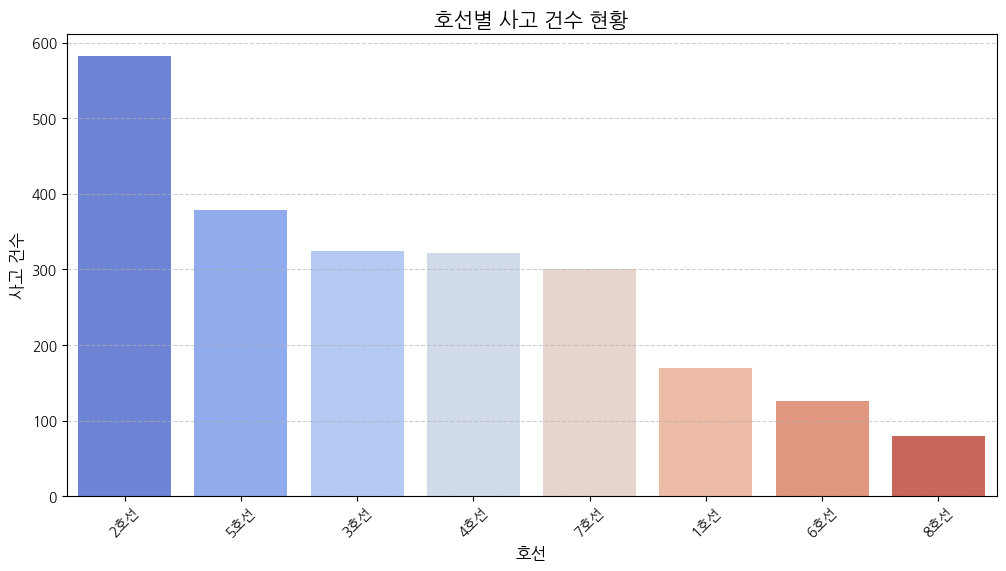

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x=line_counts.index, y=line_counts.values, palette='coolwarm')

plt.title('호선별 사고 건수 현황', fontsize=15)
plt.xlabel('호선', fontsize=12)
plt.ylabel('사고 건수', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)

2호선에서 가장 많은 사고가 발생했고, 그 뒤로 5호선 3호선으로 나열되어있다.

/tmp/ipykernel_1815/1809668999.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




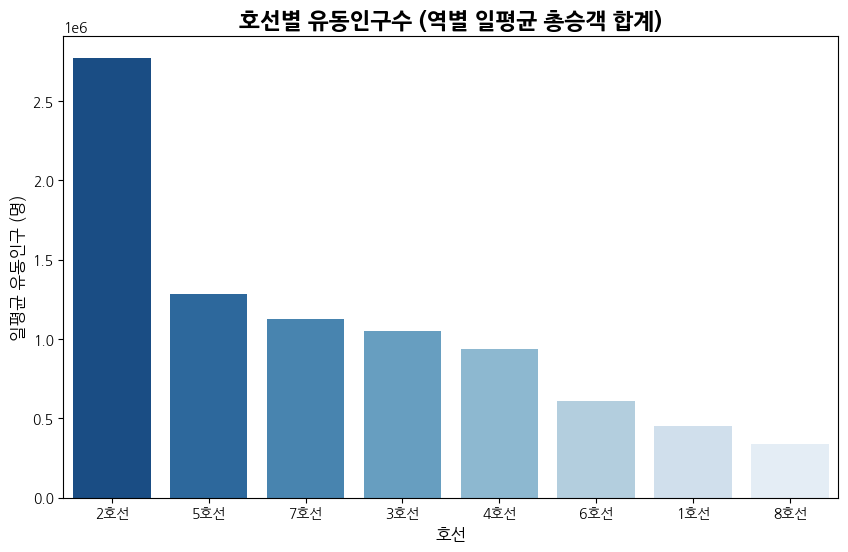

In [ ]:
line_station_pop = df.groupby(['호선', '역명'])['일간총승객'].mean().reset_index()
line_pop = line_station_pop.groupby('호선')['일간총승객'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=line_pop, x='호선', y='일간총승객', palette='Blues_r')
plt.title('호선별 유동인구수 (역별 일평균 총승객 합계)', fontsize=16, fontweight='bold')
plt.xlabel('호선', fontsize=12)
plt.ylabel('일평균 유동인구 (명)', fontsize=12)
plt.show()

사고 데이터라서 사고가 난 역들을 기준으로 2호선이 가장 크게 나타남

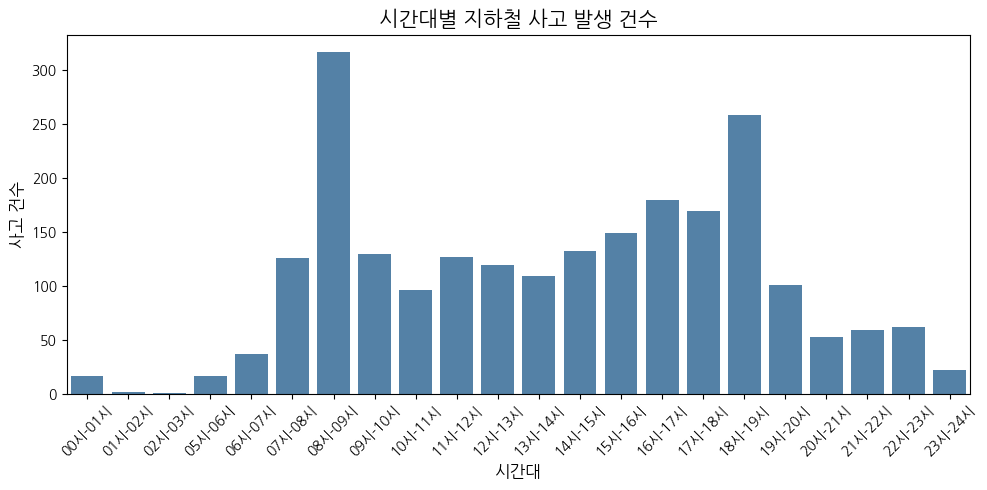

In [ ]:
time_accidents = df.groupby('시간대').size().reset_index(name='사고건수')

plt.figure(figsize=(10, 5))
sns.barplot(data=time_accidents, x='시간대', y='사고건수', color='steelblue')

plt.title('시간대별 지하철 사고 발생 건수', fontsize=15)
plt.xlabel('시간대', fontsize=12)
plt.ylabel('사고 건수', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

사고발생역 환승역 비중

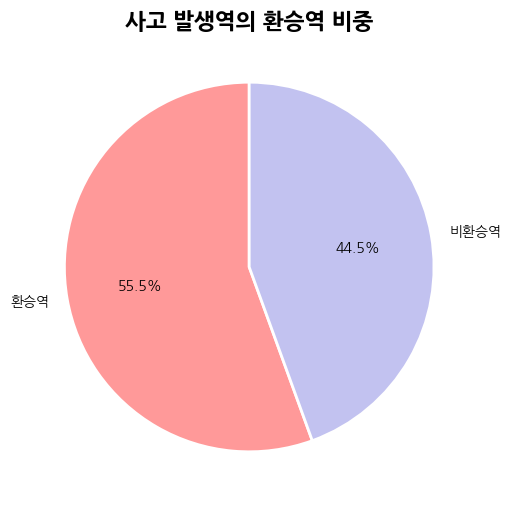

In [ ]:
plt.figure(figsize=(8, 6))
transfer_counts = df['환승여부'].value_counts()
plt.pie(transfer_counts, labels=transfer_counts.index, autopct='%1.1f%%',
        startangle=90, colors=['#ff9999', '#c2c2f0'], wedgeprops={'edgecolor': 'w', 'linewidth': 2})
plt.title('사고 발생역의 환승역 비중', fontsize=16, fontweight='bold')
plt.show()

사고 발생역 노후도 분포

/tmp/ipykernel_1815/3850521628.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




Text(0, 0.5, '사고 발생 건수')

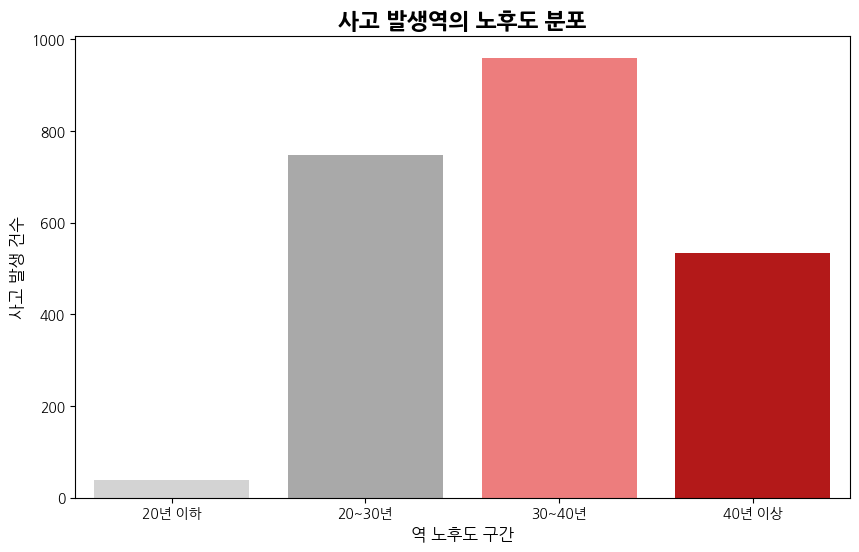

In [ ]:
plt.figure(figsize=(10, 6))
df['노후도_구간'] = pd.cut(df['역노후도'], bins=[0, 20, 30, 40, 100], labels=['20년 이하', '20~30년', '30~40년', '40년 이상'])
age_counts = df['노후도_구간'].value_counts().sort_index()

colors = ['#d3d3d3', '#a9a9a9', '#ff6b6b', '#cc0000']
sns.barplot(x=age_counts.index, y=age_counts.values, palette=colors)
plt.title('사고 발생역의 노후도 분포', fontsize=16, fontweight='bold')
plt.xlabel('역 노후도 구간', fontsize=12)
plt.ylabel('사고 발생 건수', fontsize=12)

사고 발생역 승강장형태 비중

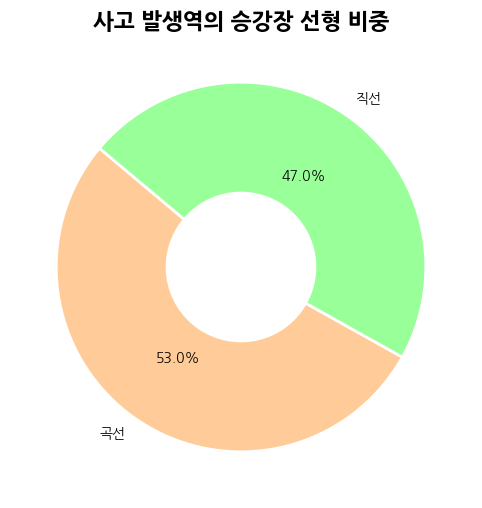

In [ ]:
plt.figure(figsize=(8, 6))
shape_counts = df['승강장선형'].value_counts()
plt.pie(shape_counts, labels=shape_counts.index, autopct='%1.1f%%',
        startangle=140, colors=['#ffcc99', '#99ff99'], wedgeprops={'width': 0.6, 'edgecolor': 'w', 'linewidth': 2})
plt.title('사고 발생역의 승강장 선형 비중', fontsize=16, fontweight='bold')
plt.show()

사건 발생 상위 5개 역

/tmp/ipykernel_1815/1826486812.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




Text(0, 0.5, '사고 건수')

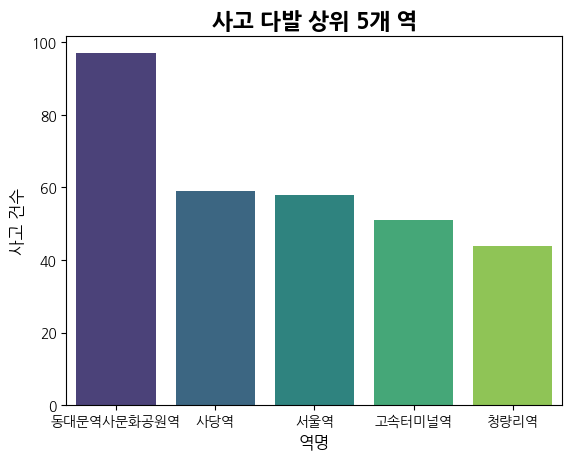

In [ ]:
top5_stations = df['역명'].value_counts().head(5).index
top5_df = df[df['역명'].isin(top5_stations)].groupby('역명').agg({'사고유형':'count', '환승노선수':'max'}).rename(columns={'사고유형':'사고건수'}).sort_values('사고건수', ascending=False)

ax = sns.barplot(x=top5_df.index, y=top5_df['사고건수'], palette='viridis')
plt.title('사고 다발 상위 5개 역', fontsize=16, fontweight='bold')
plt.xlabel('역명', fontsize=12)
plt.ylabel('사고 건수', fontsize=12)

기상상태별 사고 현황

/tmp/ipykernel_1815/3543271653.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




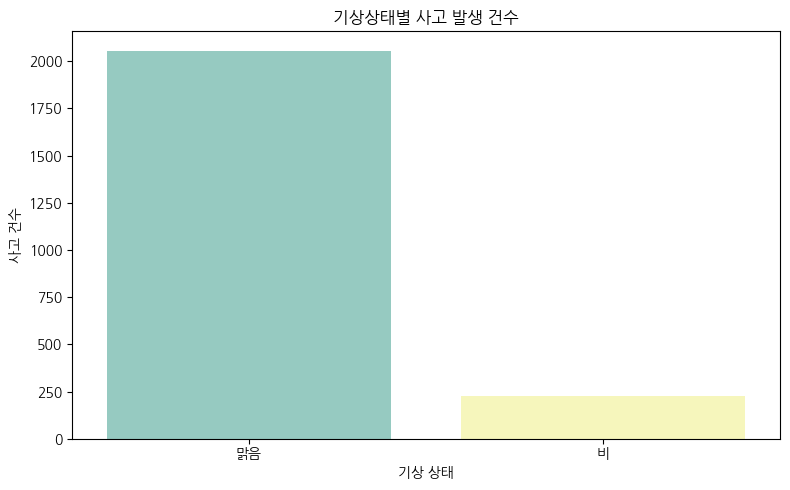

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='기상상태', palette='Set3', order=df['기상상태'].value_counts().index)
plt.title('기상상태별 사고 발생 건수')
plt.xlabel('기상 상태')
plt.ylabel('사고 건수')

plt.tight_layout()
plt.show()

연단간격별 사고 현황

/tmp/ipykernel_1815/132831290.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1815/132831290.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




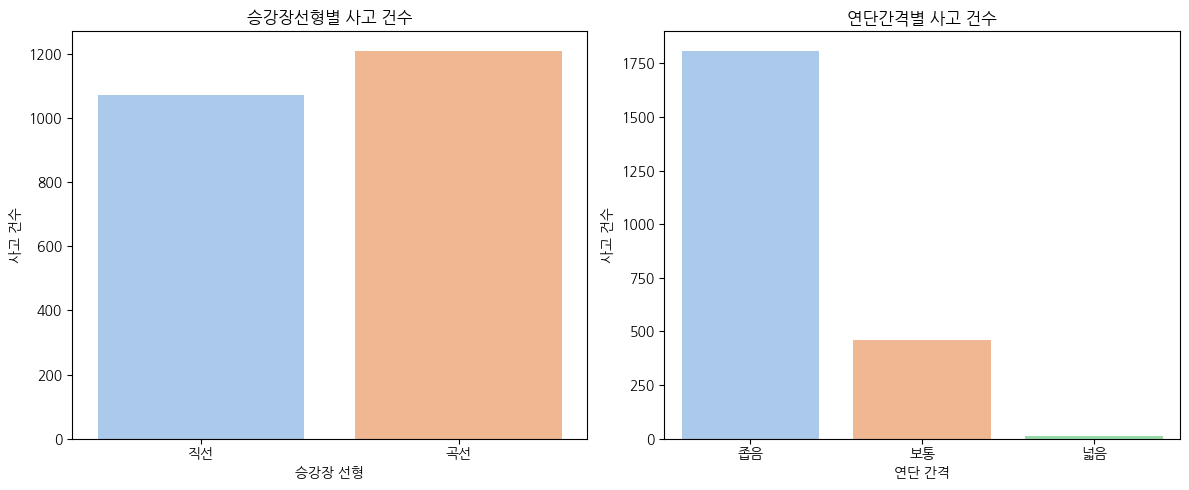

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='승강장선형', ax=axes[0], palette='pastel')
axes[0].set_title('승강장선형별 사고 건수')
axes[0].set_xlabel('승강장 선형')
axes[0].set_ylabel('사고 건수')

sns.countplot(data=df, x='연단간격', ax=axes[1], palette='pastel', order=df['연단간격'].value_counts().index)
axes[1].set_title('연단간격별 사고 건수')
axes[1].set_xlabel('연단 간격')
axes[1].set_ylabel('사고 건수')

plt.tight_layout()
plt.show()

노후도와 안전문

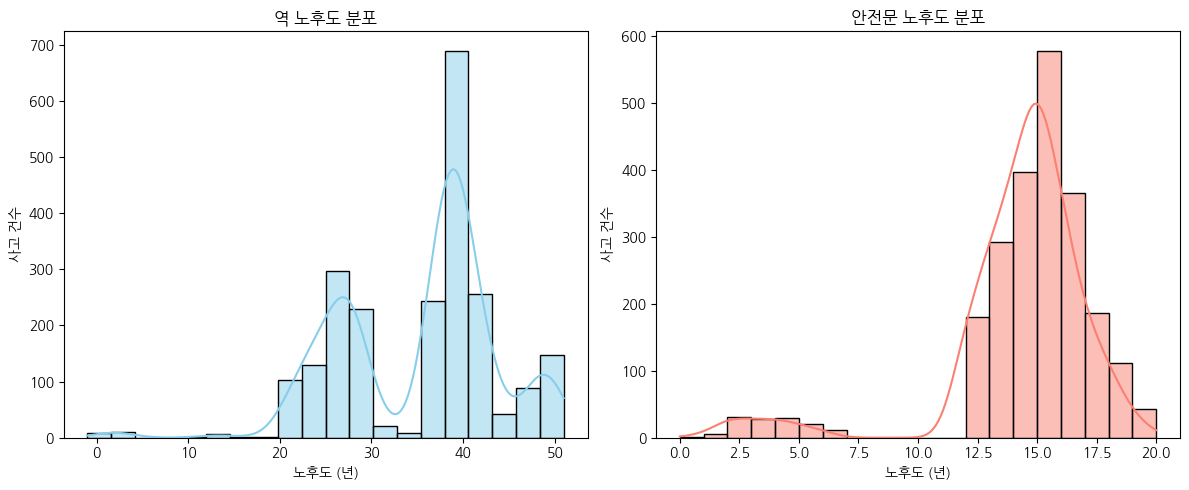

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['역노후도'].dropna(), bins=20, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('역 노후도 분포')
axes[0].set_xlabel('노후도 (년)')
axes[0].set_ylabel('사고 건수')

sns.histplot(df['안전문노후도'].dropna(), bins=20, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('안전문 노후도 분포')
axes[1].set_xlabel('노후도 (년)')
axes[1].set_ylabel('사고 건수')

plt.tight_layout()
plt.show()

사고 유형별 빈도수

/tmp/ipykernel_1815/3776343515.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




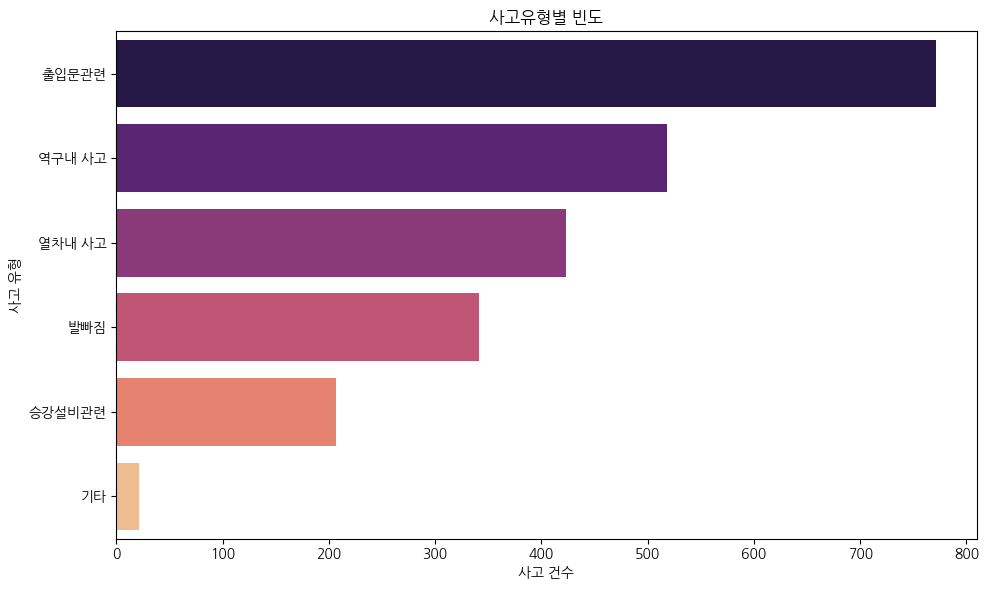

In [ ]:
plt.figure(figsize=(10, 6))
order_type = df['사고유형'].value_counts().index
sns.countplot(data=df, y='사고유형', order=order_type, palette='magma')
plt.title('사고유형별 빈도')
plt.xlabel('사고 건수')
plt.ylabel('사고 유형')
plt.tight_layout()
plt.show()

##8\. EDA 및 핵심 분석

### 8-1. 출입문관련, 발빠짐 사고

#### 가설 1. 출입문_발빠짐 사고는 역 내부 구조와 역의 준공연도에 영향을 받을 것이다

In [ ]:
df['출입문_발빠짐'] = df['사고유형'].str.contains('출입문|발빠짐', na=False)

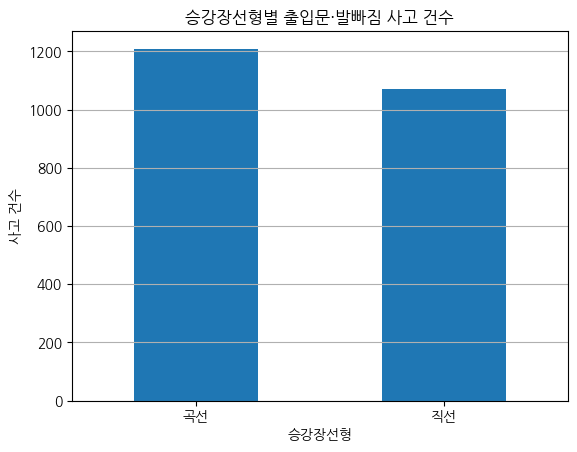

In [ ]:
# 승강장 선형별 출입문_발빠짐 사고 건수
df['승강장선형'].value_counts().plot(kind='bar')

plt.title('승강장선형별 출입문·발빠짐 사고 건수')
plt.xlabel('승강장선형')
plt.ylabel('사고 건수')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [ ]:
df_target = df[df['출입문_발빠짐'] == 1]

station_counts = df_target.groupby(['역명', '승강장선형']).size().reset_index(name='사고건수')

# 두 유형에 해당하는 역의 개수가 다를 수 있으므로
# 곡선역 1개당 평균 사고  vs 직선역 1개당 평균 사고
station_avg = station_counts.groupby('승강장선형')['사고건수'].mean()
station_avg

,사고건수
승강장선형,
곡선,7.118280
직선,4.368932


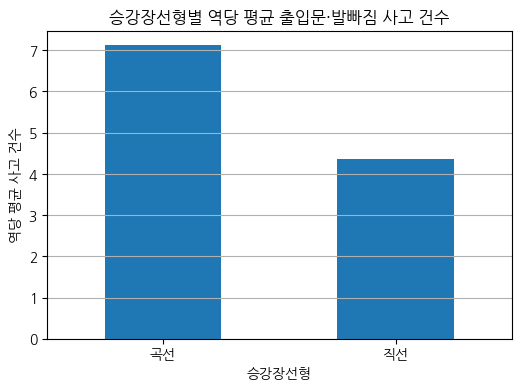

In [ ]:
# 곡선역 1개당 평균 사고 vs 직선역 1개당 평균 사고
station_avg.plot(kind='bar', figsize=(6,4))

plt.title('승강장선형별 역당 평균 출입문·발빠짐 사고 건수')
plt.xlabel('승강장선형')
plt.ylabel('역당 평균 사고 건수')
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.show()

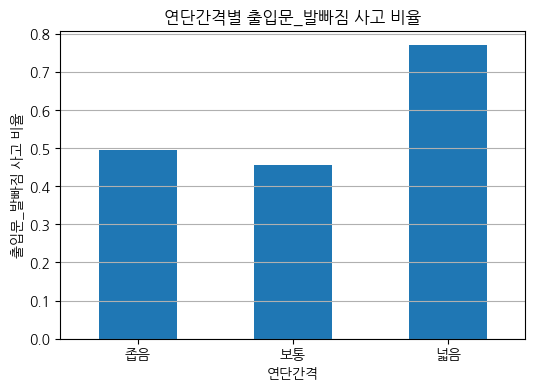

In [ ]:
# 연단간격별 전체 사고 중 출입문·발빠짐 사고가 차지하는 비율

gap_ratio = pd.crosstab(df['연단간격'], df['출입문_발빠짐'], normalize='index')[True]

gap_ratio = gap_ratio.reindex(['좁음', '보통', '넓음'])

gap_ratio.plot(kind='bar', figsize=(6,4))
plt.title('연단간격별 출입문_발빠짐 사고 비율')
plt.xlabel('연단간격')
plt.ylabel('출입문_발빠짐 사고 비율')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

**1-1. 연단간격 별 분석**

*   연단간격이 넓을 때 발생하는 사고의 약 80%는 출입문_발빠짐 사고이다




연단간격         넓음        보통        좁음
승강장선형                              
곡선     0.769231  0.504310  0.554979
직선          NaN  0.405286  0.423669


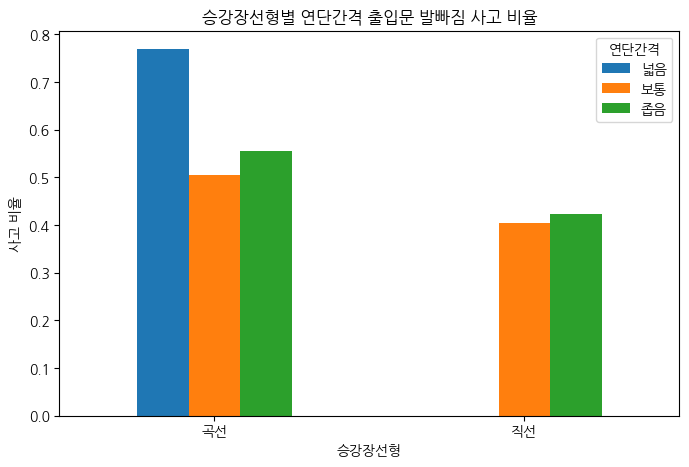

In [ ]:
# 승강장 선형과 연단간격을 한 그래프에 통합해서 다시 확인
result = df.groupby(['승강장선형', '연단간격'])['출입문_발빠짐'].mean().unstack()
print(result)

# 시각화
result.plot(kind='bar', figsize=(8, 5))

plt.title('승강장선형별 연단간격 출입문 발빠짐 사고 비율')
plt.xlabel('승강장선형')
plt.ylabel('사고 비율')
plt.xticks(rotation=0)
plt.legend(title='연단간격')
plt.show()

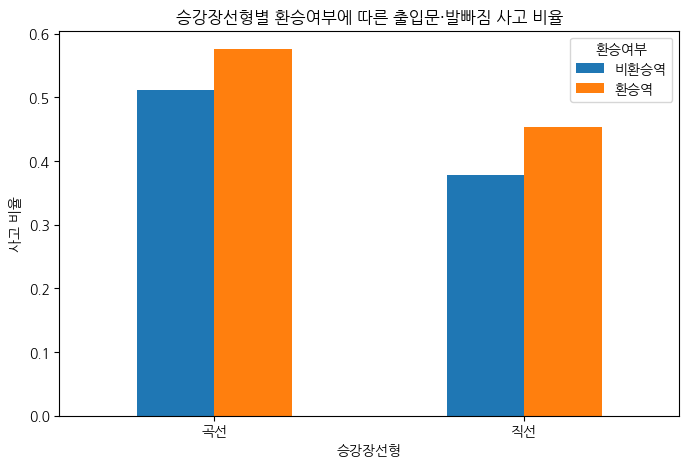

In [ ]:
result4 = df.groupby(['승강장선형', '환승여부'])['출입문_발빠짐'].mean().unstack()

result4.plot(kind='bar', figsize=(8, 5))

plt.title('승강장선형별 환승여부에 따른 출입문·발빠짐 사고 비율')
plt.xlabel('승강장선형')
plt.ylabel('사고 비율')
plt.xticks(rotation=0)
plt.legend(title='환승여부')
plt.show()

**1-2. 승강장 유형별 비교**


* 연단간격이 넓을 때, 승강장이 직선형인 곳에서 사고는 발생하지 않았다.
* 승강장 선형이 곡선이고 환승역일때의 사고 비율이 높게 나타났다.

Text(0, 0.5, '사고 건수')

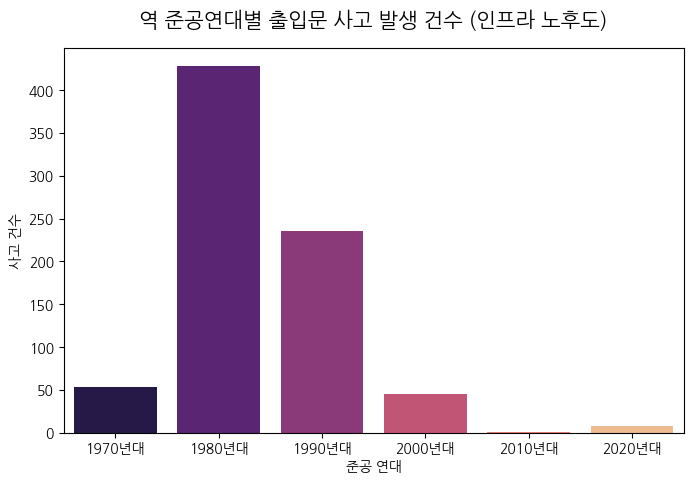

In [ ]:
# 역 준공연도를 10년간의 간격으로 구간화 후 정렬
door_df = df[df['사고유형'] == '출입문관련'].copy()
door_df['준공연대'] = (door_df['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'
age_accidents = door_df['준공연대'].value_counts().sort_index()

# 역 준공연대별 출입문 사고 발생 건수 시각화
fig, axes = plt.subplots(figsize=(8, 5))
sns.barplot(x=age_accidents.index, y=age_accidents.values, ax=axes, hue=age_accidents.index, palette='magma')
axes.set_title('역 준공연대별 출입문 사고 발생 건수 (인프라 노후도)', fontsize=15, pad=15)
axes.set_xlabel('준공 연대')
axes.set_ylabel('사고 건수')

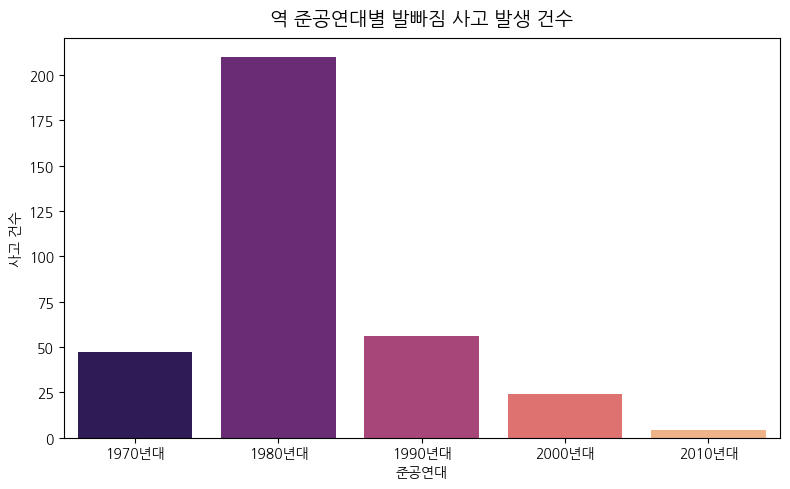

In [ ]:
# 역 준공연도를 10년간의 간격으로 구간화 후 정렬
foot_df = df[df['사고유형'] == '발빠짐'].copy()
foot_df['날짜'] = pd.to_datetime(foot_df['날짜'])
foot_df['월'] = foot_df['날짜'].dt.month
foot_df['준공연대'] = (foot_df['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'

# 역 준공연대별 출입문 사고 발생 건수 시각화
fig, axes = plt.subplots(figsize=(8, 5))
age_foot = foot_df['준공연대'].value_counts().sort_index()

sns.barplot(x=age_foot.index, y=age_foot.values, ax=axes, hue=age_foot.index, palette='magma')
axes.set_title('역 준공연대별 발빠짐 사고 발생 건수', fontsize=14, pad=10)
axes.set_ylabel('사고 건수')
plt.tight_layout()
plt.show()

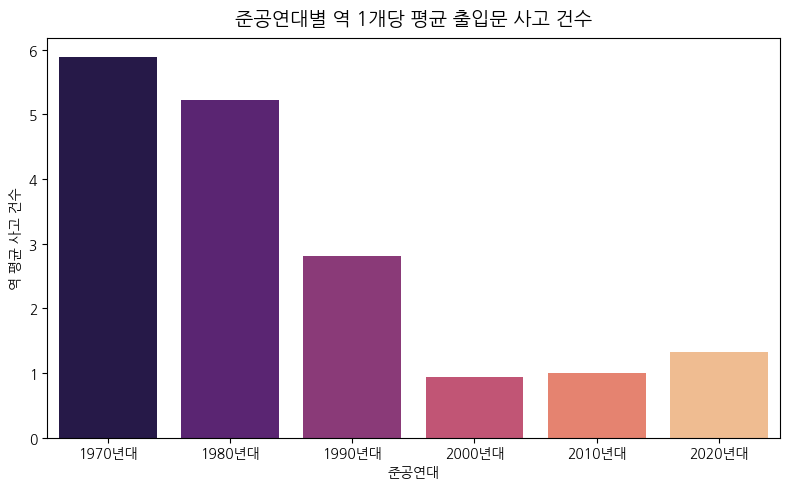

In [ ]:
# 준공연대별 출입문 사고를 단순 사고 건수가 아닌,
# "해당 연대의 총 사고 건수 ÷ 해당 연대의 역 개수"로 계산하여
# 특정 연대에서 역 수가 많아 사고 건수가 과대평가되는 효과를 보정하고,
# 역 1개당 평균 사고 수준을 비교하기 위한 추가 분석 진행

door2_df = df[df['사고유형'] == '출입문관련'].copy()
door2_df['날짜'] = pd.to_datetime(door2_df['날짜'])
door2_df['월'] = door2_df['날짜'].dt.month
door2_df['준공연대'] = (door2_df['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'

# 전체 역 데이터에서 역별 준공연대 1개씩 추출
station3_age = df[['역명', '준공연도']].drop_duplicates().copy()
station3_age['준공연대'] = (station3_age['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'

# 연대별 역 수
station_count2 = station3_age.groupby('준공연대')['역명'].nunique()

# 연대별 출입문 사고 건수
door_count2 = door2_df.groupby('준공연대').size()

# 연대별 역 1개당 평균 출입문 사고 건수
age_door_avg = (door_count2 / station_count2).sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=age_door_avg.index,
    y=age_door_avg.values,
    hue=age_door_avg.index,
    palette='magma',
    legend=False
)

plt.title('준공연대별 역 1개당 평균 출입문 사고 건수', fontsize=14, pad=10)
plt.ylabel('역 평균 사고 건수')
plt.xlabel('준공연대')
plt.tight_layout()
plt.show()

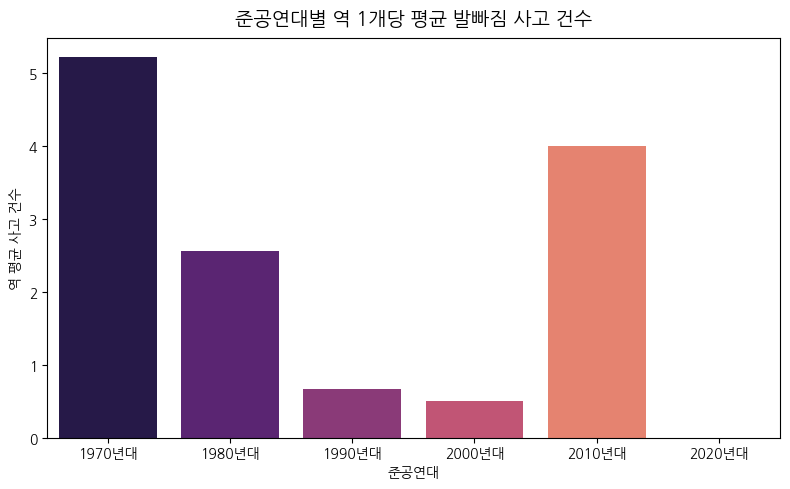

In [ ]:
#준공연대별 역 1개당 평균 발빠짐 사고 건수

foot2_df = df[df['사고유형'] == '발빠짐'].copy()
foot2_df['날짜'] = pd.to_datetime(foot2_df['날짜'])
foot2_df['월'] = foot2_df['날짜'].dt.month
foot2_df['준공연대'] = (foot2_df['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'

# 전체 역 데이터에서 역별 준공연대 1개씩 추출
station2_age = df[['역명', '준공연도']].drop_duplicates().copy()
station2_age['준공연대'] = (station2_age['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'

# 연대별 역 수
station_count = station2_age.groupby('준공연대')['역명'].nunique()

# 연대별 발빠짐 사고 건수
foot_count = foot2_df.groupby('준공연대').size()

# 연대별 역 1개당 평균 발빠짐 사고 건수
age_foot_avg = (foot_count / station_count).sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=age_foot_avg.index, y=age_foot_avg.values, hue=age_foot_avg.index, palette='magma')

plt.title('준공연대별 역 1개당 평균 발빠짐 사고 건수', fontsize=14, pad=10)
plt.ylabel('역 평균 사고 건수')
plt.xlabel('준공연대')
plt.tight_layout()
plt.show()

**1-3. 준공연대별 분석**

: 2010년대에 지어진 역이 3호선 경찰병원역 하나 뿐이라, 준공역에 대한 표본이 단일표본이어서 사고 건수가 이상치처럼 나타난 것을 확인할 수 있다.

따라서 1970년대와 1980년대에 준공된 역들에서 발빠짐 사고가 많이 발생한 것을 확인할 수 있다.

**가설 1번 정리**

* 출입문_발빠짐 사고는 연단간격이 넓고 승강장 선형이 곡선인 곳에서 더 많이
발생한다.
* 역의 준공연도가 오래되었을수록 사고 발생 건수가 더 많이 발생한 것을 확인 할 수 있다. 가설 지지

#### 가설2. 출입문_발빠짐 사고는 지하철 혼잡도에 영향을 받을 것이다.

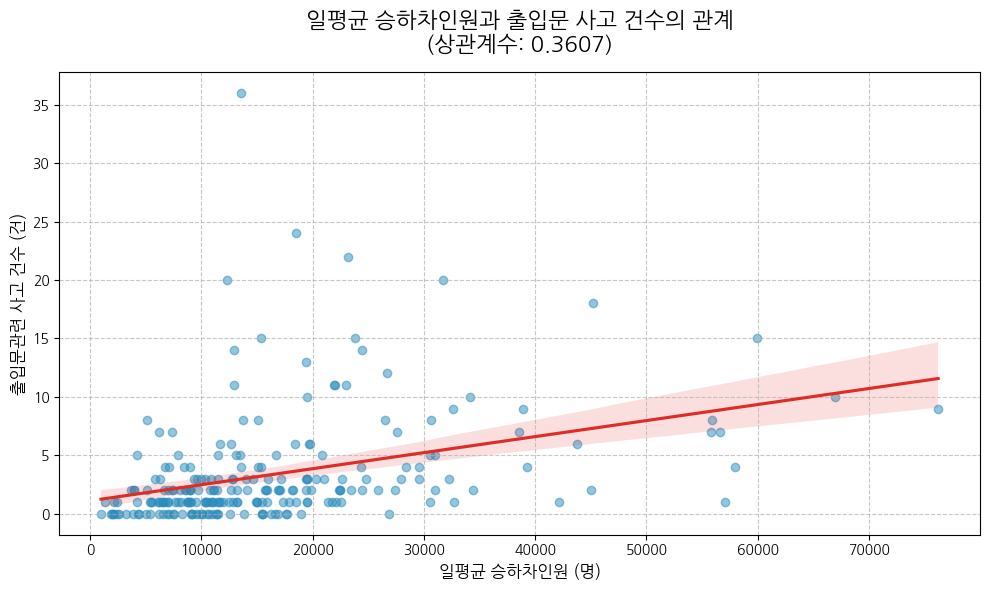

In [ ]:
# 역별 기본 정보 추출 (역마다 1행으로 만들기)
station_info = df.groupby('역명').agg({
    '승강장유형': 'first',    # 해당 역의 승강장 유형 (대표값 1개)
    '일간_총승차인원': 'mean' # 해당 역의 평균 일간 승차 인원
}).reset_index()

# 출입문관련 사고만 필터링 후 역별 사고 건수 계산
door_accidents = df[df['사고유형'] == '출입문관련'].groupby('역명').size().reset_index(name='출입문_사고건수')    # 각 역별 출입문 사고 총 건수

# 역 정보 + 사고 데이터 병합
station_stats = pd.merge(station_info, door_accidents, on='역명', how='left').fillna(0)    # 사고 없는 역도 포함 (NaN → 0으로 처리)

# 승강장유형별로 묶어서 통계 계산
type_stats = station_stats.groupby('승강장유형').agg({
    '출입문_사고건수': 'mean',
    '일간_총승차인원': 'mean',
    '역명': 'count'
}).reset_index()

# 컬럼 이름 보기 좋게 변경
type_stats = type_stats.rename(columns={'역명': '역_개수'})

# 역별 기본 정보(station_info)와 출입문 사고 건수(door_accidents)를 역명을 기준으로 병합
# how='left' → 사고 데이터가 없는 역도 포함 (NaN은 fillna(0)으로 0건 처리)
station_stats = pd.merge(station_info, door_accidents, on='역명', how='left').fillna(0)

# 역별 평균 승차 인원과 출입문 사고 건수 간의 상관계수 계산
# → 혼잡도(승차 인원)가 증가할수록 사고가 증가하는지 관계 파악
correlation = station_stats['일간_총승차인원'].corr(station_stats['출입문_사고건수'])

plt.figure(figsize=(10, 6))

# 역별 평균 승차 인원(x)과 출입문 사고 건수(y)의 산점도 + 회귀선 시각화
sns.regplot(
    data=station_stats,
    x='일간_총승차인원',
    y='출입문_사고건수',
    scatter_kws={'alpha': 0.5, 'color': '#2b8cbe'},   # 각 역의 분포
    line_kws={'color': '#de2d26'}                    # 전체 추세선
)

# 제목에 상관계수를 함께 표시
plt.title(f'일평균 승하차인원과 출입문 사고 건수의 관계\n(상관계수: {correlation:.4f})', fontsize=16, pad=15)

# 축 제목 설정
plt.xlabel('일평균 승하차인원 (명)', fontsize=12)
plt.ylabel('출입문관련 사고 건수 (건)', fontsize=12)

# 격자 추가
plt.grid(True, linestyle='--', alpha=0.7)

# 레이아웃 정리 후 그래프 출력
plt.tight_layout()
plt.show()

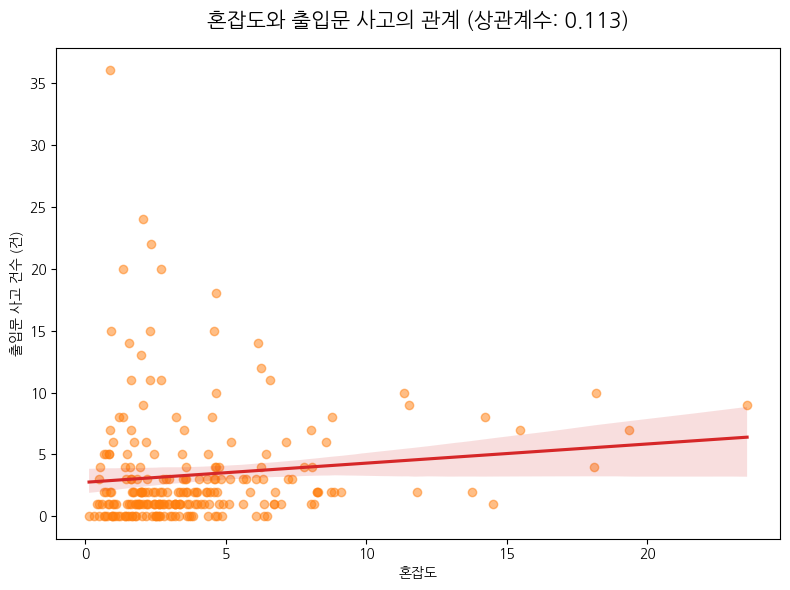

In [ ]:
door2_df = df.copy()
door2_df['출입문여부'] = (door2_df['사고유형'] == '출입문관련').astype(int)

door2_stats = door2_df.groupby('역명', as_index=False).agg({
    '혼잡도': 'mean',
    '출입문여부': 'sum'
}).rename(columns={'출입문여부': '출입문_사고건수'})

plt.figure(figsize=(8, 6))

sns.regplot(
    data=door2_stats,
    x='혼잡도',
    y='출입문_사고건수',
    scatter_kws={'alpha': 0.5, 'color': '#ff7f0e'},
    line_kws={'color': '#d62728'}
)

plt.title(
    f"혼잡도와 출입문 사고의 관계 (상관계수: {door2_stats['혼잡도'].corr(door2_stats['출입문_사고건수']):.3f})",
    fontsize=15,
    pad=15
)
plt.xlabel('혼잡도')
plt.ylabel('출입문 사고 건수 (건)')

plt.tight_layout()
plt.show()

**2-1. 혼잡도와 출입문 사고의 관계**

* 일평균 승하차 인원과 출입문 사고 간에는 중간 수준의 양의 상관관계(0.36)가 나타난 반면, 혼잡도 지표와의 상관계수는 낮게(0.1) 나타났다. 이는 출입문 사고가 공간 대비 밀집도보다는 절대적인 이용객 규모에 더 큰 영향을 받는다는 점을 시사한다.
* 혼잡도 지표는 승객수 / 역 전체 면적으로 계산한 것이므로 출입문 사고가 발생하는 승강장의 면적이 아니기 때문에 혼잡도 지표가 낮게 나왔다고 해서 직접적인 상관관계가 있다고 볼 수 없다.

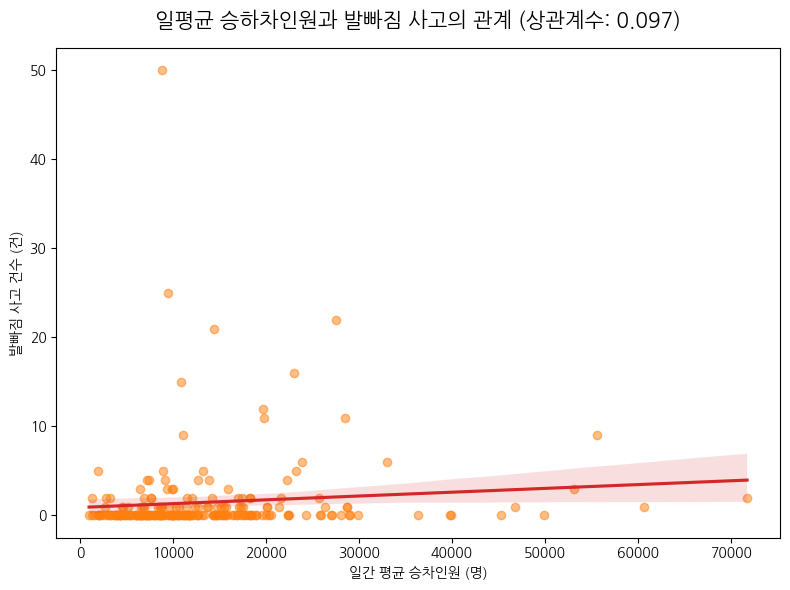

In [ ]:
foot3_df = df.copy()

foot3_df['발빠짐여부'] = foot3_df['사고유형'].str.contains('발빠짐', na=False).astype(int)

foot_stats = foot3_df.groupby('역명', as_index=False).agg({
    '일간_총승차인원': 'first',
    '발빠짐여부': 'sum'
}).rename(columns={'발빠짐여부': '발빠짐_사고건수'})

plt.figure(figsize=(8, 6))

sns.regplot(
    data=foot_stats,
    x='일간_총승차인원',
    y='발빠짐_사고건수',
    scatter_kws={'alpha': 0.5, 'color': '#ff7f0e'},
    line_kws={'color': '#d62728'}
)

plt.title(
    f"일평균 승하차인원과 발빠짐 사고의 관계 (상관계수: {foot_stats['일간_총승차인원'].corr(foot_stats['발빠짐_사고건수']):.3f})",
    fontsize=15,
    pad=15
)
plt.xlabel('일간 평균 승차인원 (명)')
plt.ylabel('발빠짐 사고 건수 (건)')

plt.tight_layout()
plt.show()

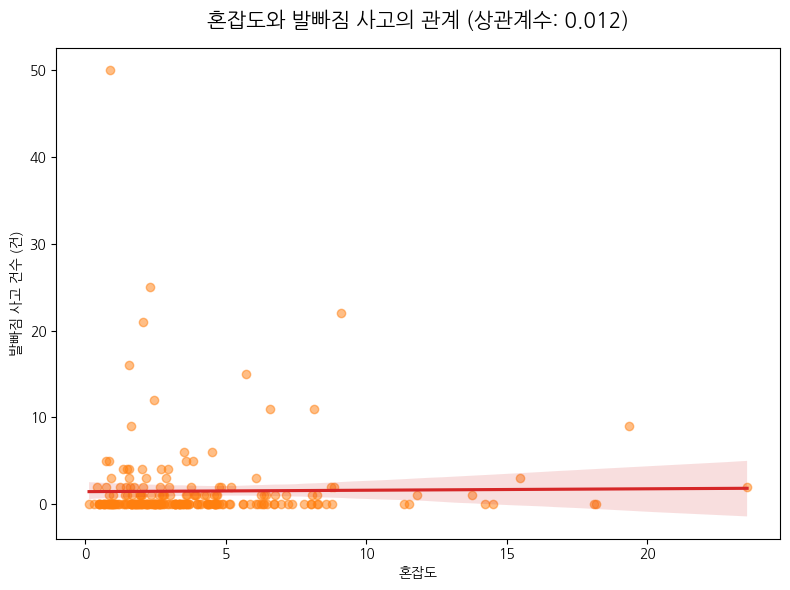

In [ ]:
foot4_df = df.copy()

foot4_df['발빠짐여부'] = foot4_df['사고유형'].str.contains('발빠짐', na=False).astype(int)

foot4_stats = foot4_df.groupby('역명', as_index=False).agg({
    '혼잡도': 'mean',
    '발빠짐여부': 'sum'
}).rename(columns={'발빠짐여부': '발빠짐_사고건수'})

plt.figure(figsize=(8, 6))

sns.regplot(
    data=foot4_stats,
    x='혼잡도',
    y='발빠짐_사고건수',
    scatter_kws={'alpha': 0.5, 'color': '#ff7f0e'},
    line_kws={'color': '#d62728'}
)

plt.title(
    f"혼잡도와 발빠짐 사고의 관계 (상관계수: {foot4_stats['혼잡도'].corr(foot4_stats['발빠짐_사고건수']):.3f})",
    fontsize=15,
    pad=15
)
plt.xlabel('혼잡도')
plt.ylabel('발빠짐 사고 건수 (건)')

plt.tight_layout()
plt.show()

**2-2. 혼잡도와 발빠짐 사고의 관계**

* 발빠짐 사고의 경우 일평균 승하차 인원과 혼잡도 두 개의 그래프에서 모두 상관관계가 낮게 나타났다.
* 발빠짐 사고는 공간 대비 밀집도나 이용객 규모와 영향을 전혀 갖지 않는 점을 시사한다

역유형
한적 비환승역    0.408081
혼잡 비환승역    0.485549
한적 환승역     0.538306
혼잡 환승역     0.450909
Name: 출입문_발빠짐, dtype: float64


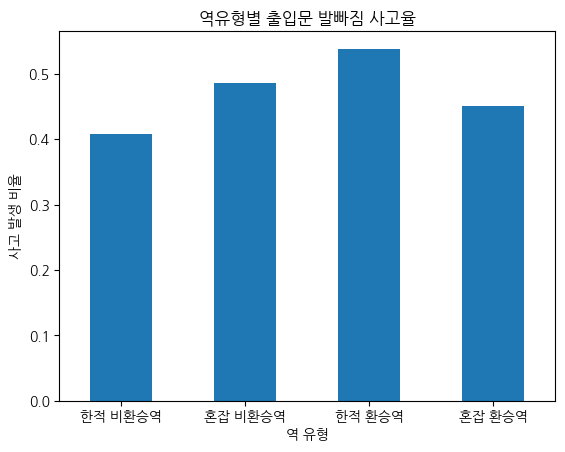

In [ ]:
# 원본 데이터 복사
station_df = df.copy()

# 전체 역의 혼잡도 평균 계산
# → 평균 이하이면 '한적', 평균 초과이면 '혼잡'으로 구분할 기준값
avg_congestion = station_df['혼잡도'].mean()

# 각 행의 혼잡도를 기준으로 혼잡구분 컬럼 생성
station_df['혼잡구분'] = np.where(station_df['혼잡도'] <= avg_congestion, '한적', '혼잡')

# 혼잡구분 + 환승여부를 합쳐 역유형 컬럼 생성
# 예: '한적 비환승역', '혼잡 환승역'
station_df['역유형'] = station_df['혼잡구분'] + ' ' + station_df['환승여부']

# 역유형별 출입문_발빠짐 사고 비율 계산
# 출입문_발빠짐이 0/1 변수이므로 mean()을 하면 사고 발생 비율이 됨
result = station_df.groupby('역유형')['출입문_발빠짐'].mean().reindex(
    ['한적 비환승역', '혼잡 비환승역', '한적 환승역', '혼잡 환승역']
)

# 역유형별 사고 비율 출력
print(result)

# 막대그래프로 시각화
result.plot(kind='bar')

# 그래프 제목 및 축 이름 설정
plt.title('역유형별 출입문 발빠짐 사고율')
plt.xlabel('역 유형')
plt.ylabel('사고 발생 비율')
plt.xticks(rotation=0)

# 그래프 출력
plt.show()

역유형
한적 비환승역    1.463768
혼잡 비환승역    3.705882
한적 환승역     8.612903
혼잡 환승역     5.904762
Name: 출입문_발빠짐, dtype: float64


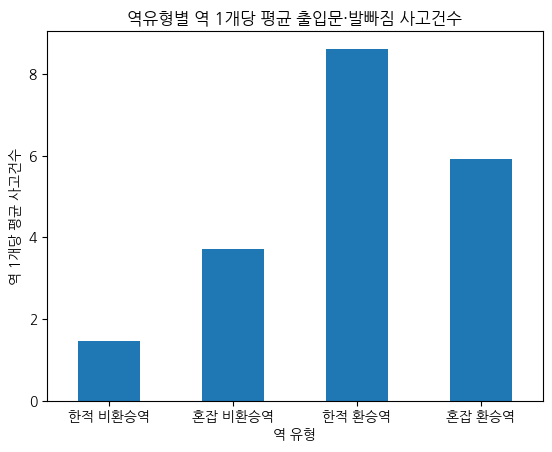

In [ ]:
# 역유형별 "역 1개당 평균 사고건수"
station_count = station_df.groupby(['역명', '역유형'])['출입문_발빠짐'].sum().reset_index()

# 역유형별 "역 1개당 평균 사고건수"
result2 = station_count.groupby('역유형')['출입문_발빠짐'].mean().reindex(
    ['한적 비환승역', '혼잡 비환승역', '한적 환승역', '혼잡 환승역']
)

print(result2)

result2.plot(kind='bar')

plt.title('역유형별 역 1개당 평균 출입문·발빠짐 사고건수')
plt.xlabel('역 유형')
plt.ylabel('역 1개당 평균 사고건수')
plt.xticks(rotation=0)
plt.show()

**2-3. 한적한 환승역에서 사고가 많은 이유**

* 환승 구조 자체가 일반역에 비해 복잡하다. 혼잡하지 않을 경우 방심하는 개인의 부주의의 영향이 작용한 것으로 추측한다.
* 승강장 구조 문제 (곡선) 환승역은 일반역에 비해 구조가 복잡하고 층고가 다양하며, 곡선 승강장이 더 많다.
* 동선이 길어서 타이밍 늦을 경우 발생 환승 동선 길면 도착 타이밍을 놓칠 수 있다. 지각을 면하기 위해 문이 닫히는 상황에서 무리하게 탑승을 시도하여 사고가 발생하는 일이 생길 것으로 예상된다.

**가설 2번 정리**

* 출입문 사고는 혼잡도와 유의미한 양의 상관관계를 보였으나,
발빠짐 사고는 구조적 요인의 영향이 더 크게 작용하여 혼잡도와의 상관관계가 낮게 나타났다.

#### 가설 3: 출입문 사고와 발빠짐 사고는 각각 다른 계절별, 구조적 특징을 가질 것이다.

/tmp/ipykernel_1815/674229007.py:19: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




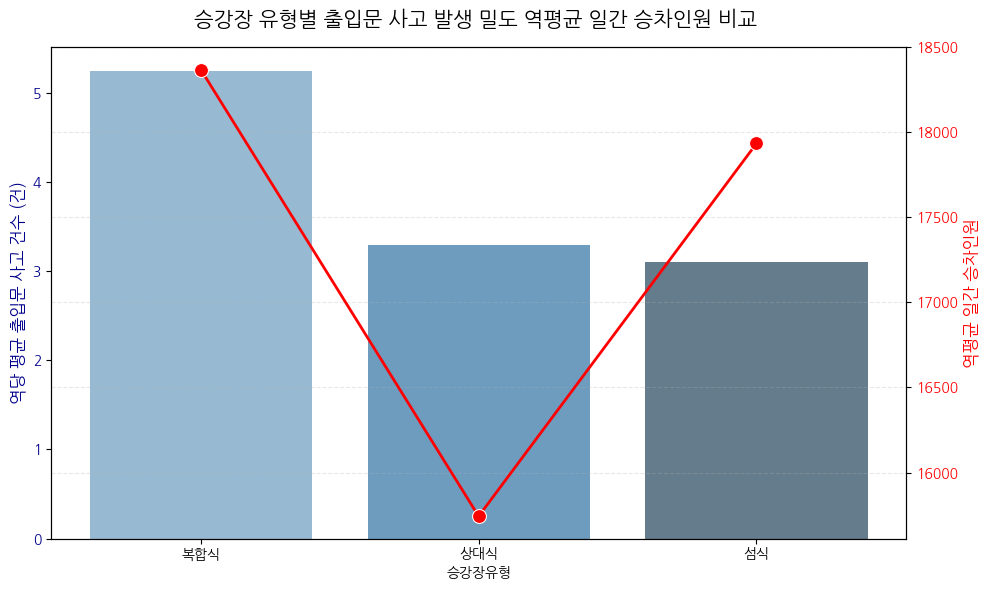

In [ ]:
station_info = df.groupby('역명').agg({
    '승강장유형': 'first',
    '일간_총승차인원': 'mean'
}).reset_index()

door_accidents = df[df['사고유형'] == '출입문관련'].groupby('역명').size().reset_index(name='출입문_사고건수')
station_stats = pd.merge(station_info, door_accidents, on='역명', how='left').fillna(0)

type_stats = station_stats.groupby('승강장유형').agg({
    '출입문_사고건수': 'mean',
    '일간_총승차인원': 'mean',
    '역명': 'count'
}).reset_index()

type_stats = type_stats.rename(columns={'역명': '역_개수'})

fig, ax1 = plt.subplots(figsize=(10, 6))

sns.barplot(data=type_stats, x='승강장유형', y='출입문_사고건수', ax=ax1, palette='Blues_d', alpha=0.8)
ax1.set_ylabel('역당 평균 출입문 사고 건수 (건)', color='darkblue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='darkblue')

ax2 = ax1.twinx() #
sns.lineplot(data=type_stats, x='승강장유형', y='일간_총승차인원', ax=ax2, color='red', marker='o', markersize=10, linewidth=2)
ax2.set_ylabel('역평균 일간 승차인원', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

plt.title('승강장 유형별 출입문 사고 발생 밀도 역평균 일간 승차인원 비교 ', fontsize=15, pad=15)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1815/3184184592.py:21: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




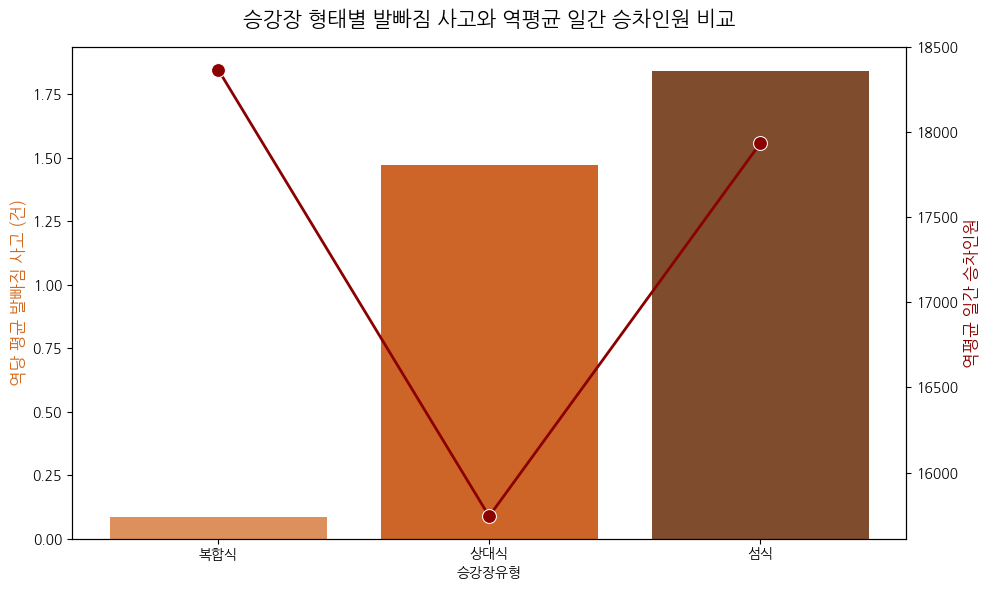

In [ ]:
station_info2 = df.groupby('역명').agg({
    '승강장유형': 'first',
    '일간_총승차인원': 'mean'
}).reset_index()

foot_accidents = df[df['사고유형'].str.contains('발빠짐', na=False)] \
    .groupby('역명').size().reset_index(name='발빠짐_사고건수')

station_stats2 = pd.merge(station_info2, foot_accidents, on='역명', how='left').fillna(0)

type_stats2 = station_stats2.groupby('승강장유형').agg({
    '발빠짐_사고건수': 'mean',
    '일간_총승차인원': 'mean',
    '역명': 'count'
}).reset_index()

type_stats2 = type_stats2.rename(columns={'역명': '역_개수'})

fig, ax1 = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=type_stats2,
    x='승강장유형',
    y='발빠짐_사고건수',
    ax=ax1,
    palette='Oranges_d'
)
ax1.set_ylabel('역당 평균 발빠짐 사고 (건)', color='chocolate', fontsize=12)
ax1.set_xlabel('승강장유형')

ax2 = ax1.twinx()
sns.lineplot(
    data=type_stats2,
    x='승강장유형',
    y='일간_총승차인원',
    ax=ax2,
    color='darkred',
    marker='o',
    markersize=10,
    linewidth=2
)
ax2.set_ylabel('역평균 일간 승차인원', color='darkred', fontsize=12)

plt.title('승강장 형태별 발빠짐 사고와 역평균 일간 승차인원 비교', fontsize=15, pad=15)
plt.tight_layout()
plt.show()

**3-1. 승강장 유형별 출입문, 발빠짐 사고 관계**

* 출입문 사고의 경우 승강장 유형이 복합식일 때 더 많이 발생했다

* 발빠짐 사고의 경우 승강장 유형이 섬식과 상대식일 때 더 많이 발생하였다.

**참고 자료**

* 섬식 승강장: 선로 사이에 하나(양쪽 열차 이용)

* 상대식 승강장: 선로 양쪽에 따로 두 개

* 복합식 승강장 = 둘을 섞어놓은 구조



**복합식은 보통 다음과 같은 상황에서:**

* 환승역에서 동선 분리 필요할 때 / 특정 방향만 따로 처리해야 할 때 / 선로가 3개 이상인 경우 / 급행/완행 분리할 때

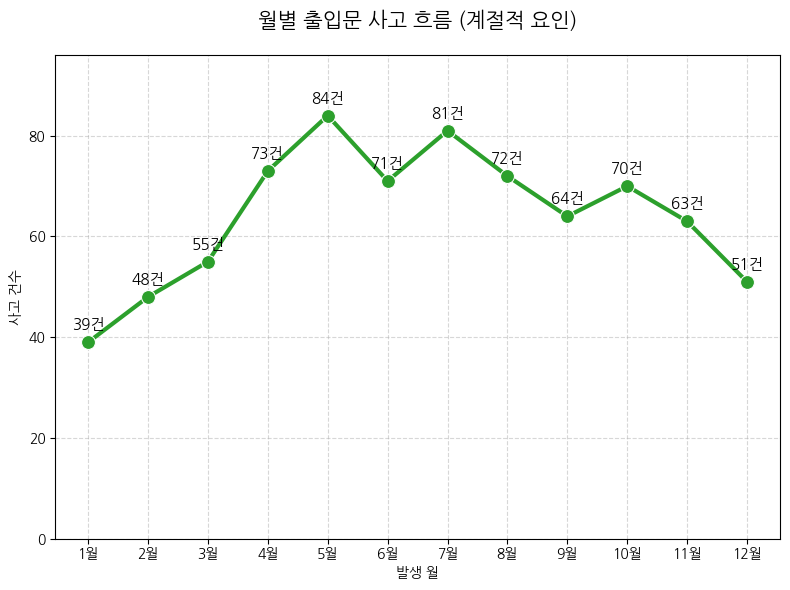

In [ ]:
door2_df['날짜'] = pd.to_datetime(door_df['날짜'])
door2_df['월'] = door2_df['날짜'].dt.month
month_accidents = door2_df['월'].value_counts().sort_index()

plt.figure(figsize=(8, 6))

sns.lineplot(
    x=month_accidents.index,
    y=month_accidents.values,
    marker='o',
    markersize=10,
    linewidth=3,
    color='#2ca02c'
)

for x, y in zip(month_accidents.index, month_accidents.values):
    plt.text(x, y + 2, f'{y}건', ha='center', va='bottom', fontsize=11)

plt.title('월별 출입문 사고 흐름 (계절적 요인)', fontsize=15, pad=20)
plt.xticks(range(1, 13), [f'{i}월' for i in range(1, 13)])
plt.xlabel('발생 월')
plt.ylabel('사고 건수')
plt.ylim(0, month_accidents.max() + 12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

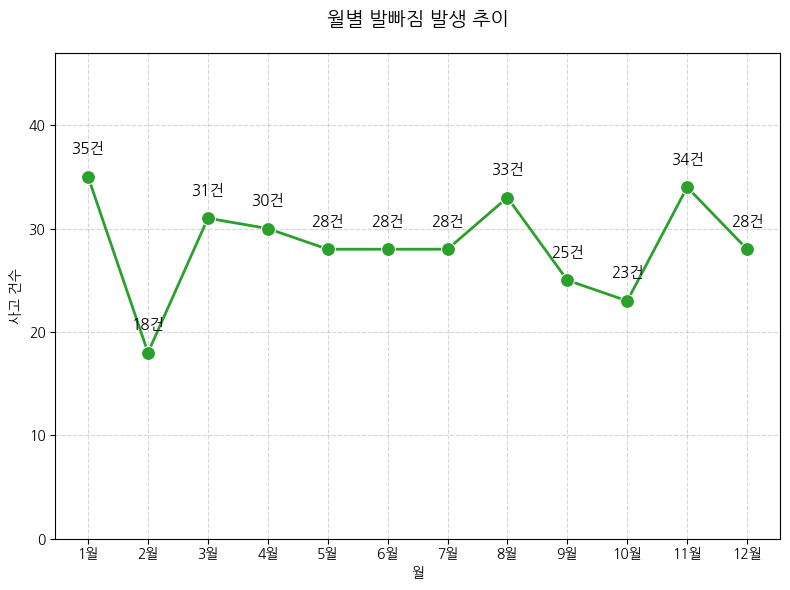

In [ ]:
foot2_df = df[df['사고유형'] == '발빠짐'].copy()
foot2_df['날짜'] = pd.to_datetime(foot2_df['날짜'])
foot2_df['월'] = foot2_df['날짜'].dt.month
foot2_df['준공연대'] = (foot2_df['준공연도'] // 10 * 10).astype(int).astype(str) + '년대'

fig, ax = plt.subplots(figsize=(8, 6))

month_foot = foot2_df['월'].value_counts().sort_index()

sns.lineplot(
    x=month_foot.index,
    y=month_foot.values,
    ax=ax,
    marker='o',
    markersize=10,
    color='#2ca02c',
    linewidth=2
)

for x, y in zip(month_foot.index, month_foot.values):
    ax.text(x, y + 2, f'{y}건', ha='center', va='bottom', fontsize=11)

ax.set_title('월별 발빠짐 발생 추이', fontsize=14, pad=20)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'{i}월' for i in range(1, 13)])
ax.set_ylabel('사고 건수')
ax.set_ylim(0, month_foot.max() + 12)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

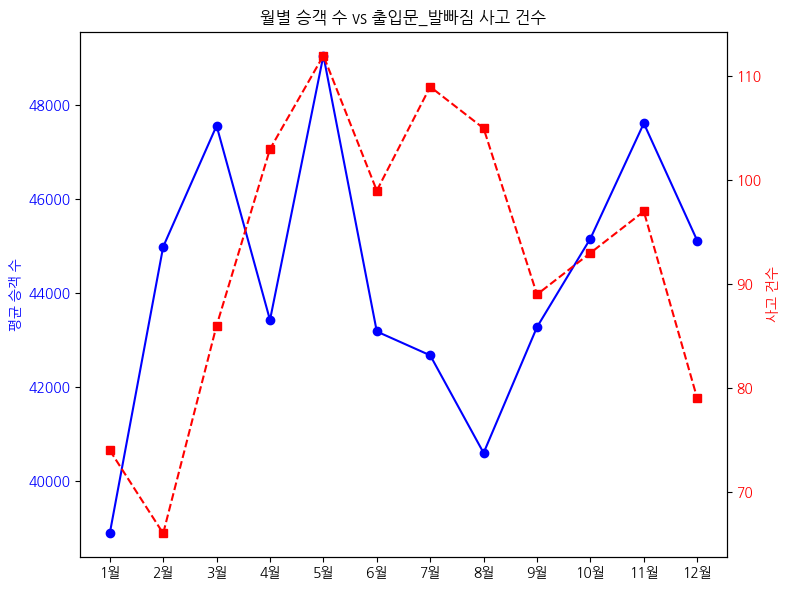

In [ ]:
month_passenger = df.groupby('사고월')['일간총승객'].mean()
month_accident = df.groupby('사고월')['출입문_발빠짐'].sum()

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(month_passenger.index, month_passenger.values, marker='o', color='blue', label='승객 수')
ax1.set_ylabel('평균 승객 수', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(month_accident.index, month_accident.values, marker='s', linestyle='--', color='red', label='사고 건수')
ax2.set_ylabel('사고 건수', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax1.set_xticks(range(1, 13))
ax1.set_xticklabels([f'{i}월' for i in range(1, 13)])
ax1.set_title('월별 승객 수 vs 출입문_발빠짐 사고 건수')

plt.tight_layout()
plt.show()

**3-2. 계절별 차이**

* 출입문과 발빠짐 사고를 통합해서 본 결과 전반적으로 여름에 높았고 겨울에 낮게 나타났다.

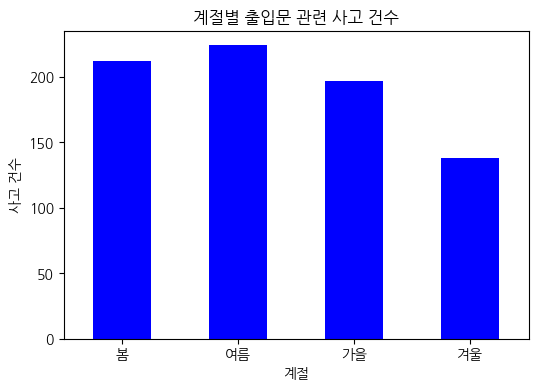

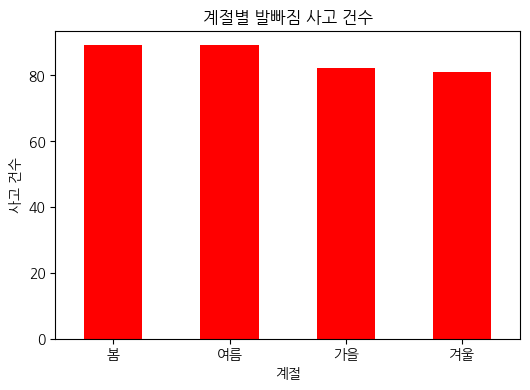

In [ ]:
# 계절별로 구간화
season_map = {
    3: '봄', 4: '봄', 5: '봄',
    6: '여름', 7: '여름', 8: '여름',
    9: '가을', 10: '가을', 11: '가을',
    12: '겨울', 1: '겨울', 2: '겨울'
}

temp_df = df.copy()
temp_df['계절'] = temp_df['사고월'].map(season_map)

# 출입문 관련 사고
door_season = temp_df[temp_df['사고유형'] == '출입문관련'] \
    .groupby('계절').size().reindex(['봄','여름','가을','겨울'])

# 발빠짐 사고
foot_season = temp_df[temp_df['사고유형'].str.contains('발빠짐', na=False)] \
    .groupby('계절').size().reindex(['봄','여름','가을','겨울'])


# 그래프 1: 출입문 관련
plt.figure(figsize=(6,4))
door_season.plot(kind='bar', color='blue')
plt.title('계절별 출입문 관련 사고 건수')
plt.xlabel('계절')
plt.ylabel('사고 건수')
plt.xticks(rotation=0)
plt.show()


# 그래프 2: 발빠짐
plt.figure(figsize=(6,4))
foot_season.plot(kind='bar', color='red')
plt.title('계절별 발빠짐 사고 건수')
plt.xlabel('계절')
plt.ylabel('사고 건수')
plt.xticks(rotation=0)
plt.show()

**가설 3번 정리**

* 출입문 사고의 경우 여름에 더 높게 나타나는 것을 확인할 수 있었다(가설 지지)
* 발빠짐 사고의 경우 봄과 여름에 높았지만 계절에 따른 유의미한 차이를 나타내지는 않았다.

### 8-2. 역 구내 사고

#### 가설 1. 역 구내 사고는 출퇴근 시간대에 많이 발생한다.

In [ ]:
# 역구내사고만 필터링
station_acc = clean_df[clean_df['사고유형'] == '역구내 사고'].copy()

print('전체 사고 건수:', len(df))
print('역구내사고 건수:', len(station_acc))
print('역구내사고 비율:', round(len(station_acc) / len(df) * 100, 2), '%')

전체 사고 건수: 2281
역구내사고 건수: 518
역구내사고 비율: 22.71 %


In [ ]:
# 시간 파생변수 만들기
station_acc['발생시간'] = pd.to_datetime(station_acc['발생시간'])

station_acc['시간'] = station_acc['발생시간'].dt.hour

# 출퇴근 시간대 분류
def commute_label(hour):
    if 7 <= hour <= 9:
        return '출근시간'
    elif 18 <= hour <= 20:
        return '퇴근시간'
    else:
        return '기타시간'

station_acc['시간구분'] = station_acc['시간'].apply(commute_label)

/tmp/ipykernel_1815/1573007441.py:2: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



In [ ]:
# '시간구분' 컬럼의 값별 개수(사고 건수)를 집계한다.
# reindex()를 사용하여 결과를 [출근, 퇴근, 기타] 순서로 정렬한다.
time_group_counts = station_acc['시간구분'].value_counts().reindex(['출근시간','퇴근시간','기타시간'])

# 각 범주가 실제 '몇 시간' 동안 지속되는지 분모 역할을 할 값을 정의한다.
# 출근(3시간), 퇴근(3시간), 기타(18시간)
time_hours = {
    '출근시간': 3,
    '퇴근시간': 3,
    '기타시간': 18
}

# 시간당 사고 계산 결과를 저장하기 위해 기존 사고 건수 시리즈를 복사
time_group_rate = time_group_counts.copy()

# 반복문(for)을 돌며 각 시간대별 '시간당 사고 발생률'을 계산합니다.
# 해당 시간대 총 사고 건수 / 해당 시간대 지속 시간
for k in time_group_rate.index:
    time_group_rate[k] = time_group_counts[k] / time_hours[k]

print("시간대별 총 사고")
print(time_group_counts)

print("\n시간당 사고 발생률")
print(time_group_rate.round(2))

시간대별 총 사고
시간구분
출근시간    109
퇴근시간     63
기타시간    346
Name: count, dtype: int64

시간당 사고 발생률
시간구분
출근시간    36.33
퇴근시간    21.00
기타시간    19.22
Name: count, dtype: float64


/tmp/ipykernel_1815/1399090362.py:19: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '36.333333333333336' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.



/tmp/ipykernel_1815/3162695416.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1815/3162695416.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




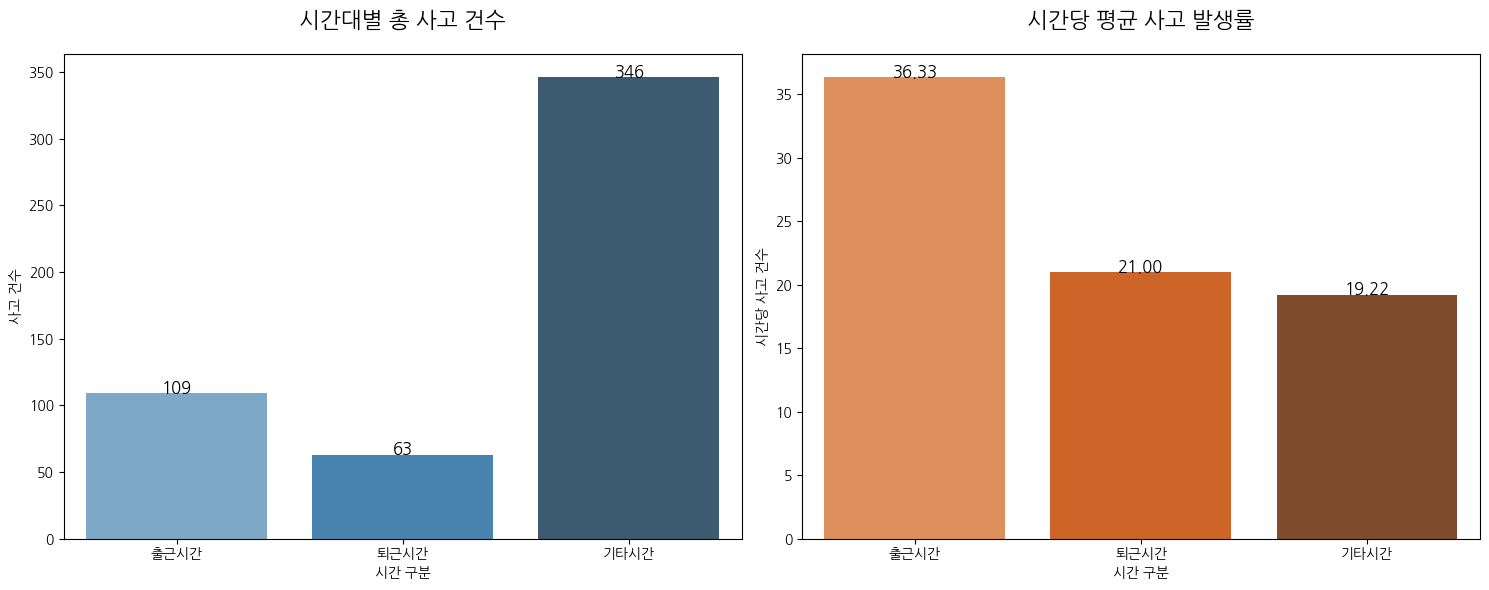

In [ ]:
# 시각화
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- 첫 번째 그래프: 총 사고 건수 ---
sns.barplot(x=time_group_counts.index, y=time_group_counts.values,
            ax=axes[0], palette='Blues_d')
axes[0].set_title('시간대별 총 사고 건수', fontsize=16, pad=20)
axes[0].set_ylabel('사고 건수')
axes[0].set_xlabel('시간 구분')

# 막대 위에 수치 표시
for i, v in enumerate(time_group_counts.values):
    axes[0].text(i, v + 0.5, str(int(v)), ha='center', fontsize=12)

# --- 두 번째 그래프: 시간당 사고 발생률 ---
sns.barplot(x=time_group_rate.index, y=time_group_rate.values,
            ax=axes[1], palette='Oranges_d')
axes[1].set_title('시간당 평균 사고 발생률', fontsize=16, pad=20)
axes[1].set_ylabel('시간당 사고 건수')
axes[1].set_xlabel('시간 구분')

# 막대 위에 수치 표시 (소수점 2자리)
for i, v in enumerate(time_group_rate.values):
    axes[1].text(i, v + 0.01, f'{v:.2f}', ha='center', fontsize=12)

# 전체 레이아웃 조정
plt.tight_layout()
plt.show()

**1-1. 시간대별 사고 발생률**

* 시간구간별 사고 건수를 단순 비교하면 기타시간대의 사고가 가장 많았지만 시간 길이 차이 때문에 왜곡이 발생한다.
이를 보정하기 위해 시간당 사고 발생률로 정규화를 해주니 출근시간대가 시간당 36건으로 가장 높게 나타났다. 이는 기타시간대보다 약 2배 높은 수준이다.

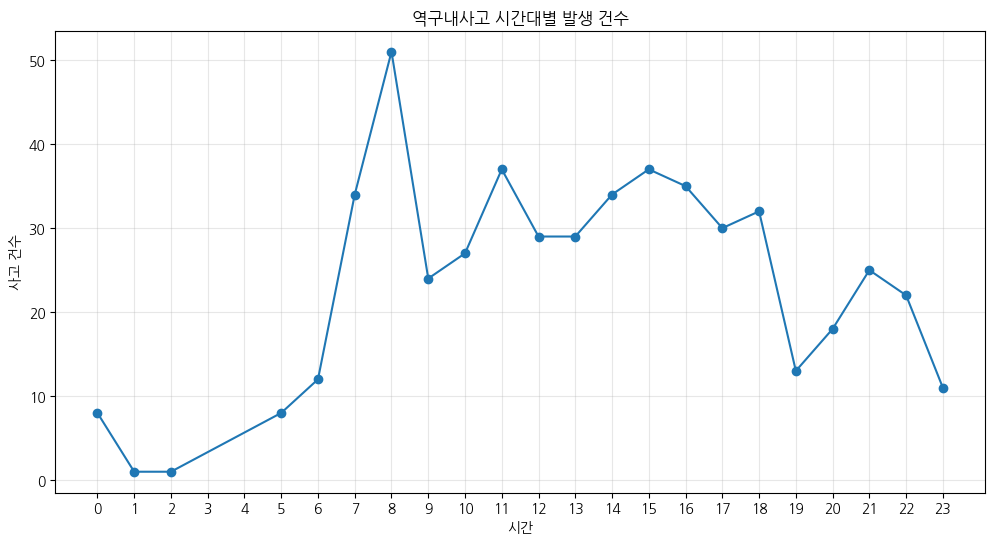

In [ ]:
hour_counts = station_acc['시간'].value_counts().sort_index()

plt.figure(figsize=(12,6))
plt.plot(hour_counts.index, hour_counts.values, marker='o')
plt.xticks(range(0,24))
plt.xlabel('시간')
plt.ylabel('사고 건수')
plt.title('역구내사고 시간대별 발생 건수')
plt.grid(alpha=0.3)
plt.show()

**가설 1번 정리**

* 사고의 흐름을 보기 위해 라인 그래프를 그려본 결과 오전 7시부터 사고가 급격히 증가하고, 8시에 정점을 찍은 뒤 9시 이후 다소 감소한다. 특히 11시~18시 구간도 30건 안팎으로 꾸준히 높게 나타난다.
* 역구내사고가 단순히 출근 시간에만 발생하는 것이 아니라 낮 시간대에도 지속적으로 발생하는 사고 유형임을 보여준다.

#### 가설 2. 특정 역이나 호선에 역 구내 사고가 집중된다.

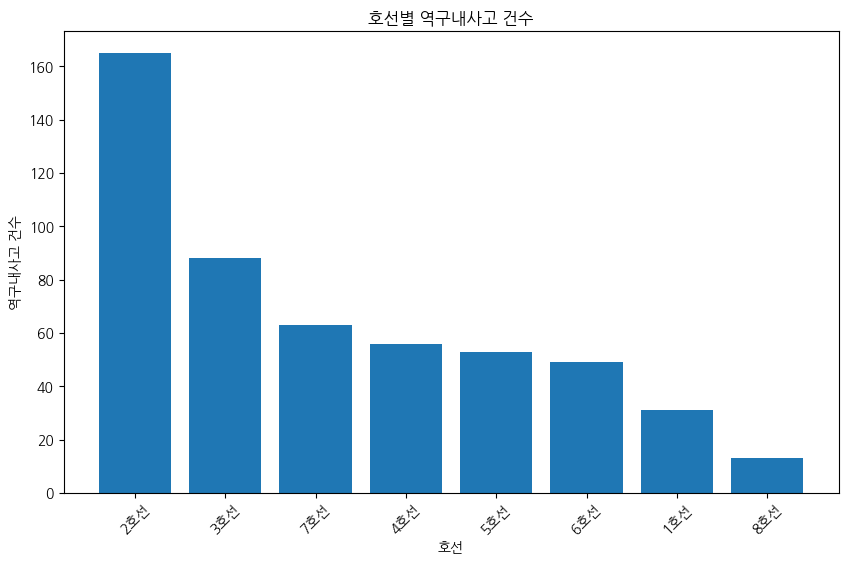

호선
2호선    165
3호선     88
7호선     63
4호선     56
5호선     53
6호선     49
1호선     31
8호선     13
Name: count, dtype: int64


In [ ]:
# 호선 컬럼의 빈도수를 계산하여 사고가 가장 많은 호선부터 내림차순 정렬
line_counts = station_acc['호선'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10,6))

# astype(str)을 이용해 호선명을 문자열로 변환
plt.bar(line_counts.index.astype(str), line_counts.values)

plt.xlabel('호선')
plt.ylabel('역구내사고 건수')
plt.title('호선별 역구내사고 건수')

plt.xticks(rotation=45)

plt.show()

print(line_counts)

**2-1. 역구내사고 중 빈도가 높은 호선**

* 특정 노선 중 2호선에서 사고 발생이 가장 집중되는 경향이 확인되었다.

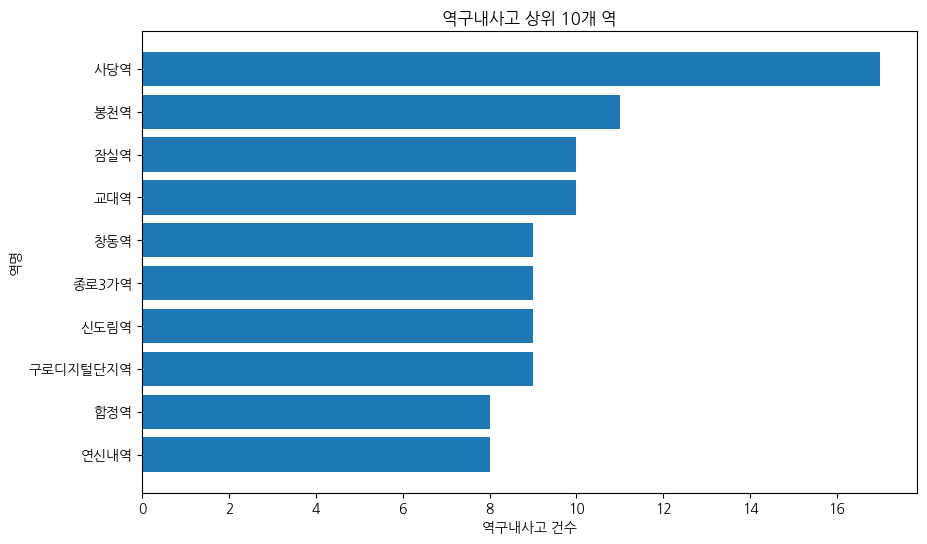

In [ ]:
# 역명 컬럼의 데이터 개수를 세고 사고가 많이 발생한 순서대로 상위 10개역
top10_station = station_acc['역명'].value_counts().head(10).sort_values()

plt.figure(figsize=(10,6))
plt.barh(top10_station.index, top10_station.values)
plt.xlabel('역구내사고 건수')
plt.ylabel('역명')
plt.title('역구내사고 상위 10개 역')
plt.show()

**2-2. 세부적인 역 조사**

* 사고가 모든 역에 고르게 분포하기보다, 환승역 및 유동 인구가 많은 특정 역에 밀집되어 있다.


**가설 2번 정리**

* 사고 데이터의 상위권을 차지한 종로3가(1·3·5호선), 신도림(1·2호선), 사당(2·4호선), 잠실(2·8호선), 교대(2·3호선), 합정(2·6호선) 역들은 환승역이거나 2호선이 포함된 역들이 많았다.

#### 가설 3. 혼잡한 역 일수록 역 구내 사고가 많이 발생한다.

-0.3821898888699347


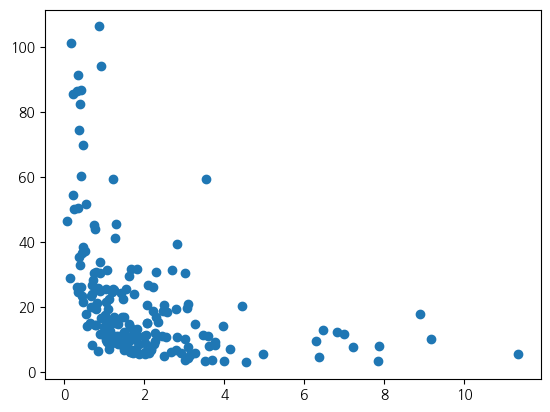

In [ ]:
# 역별 사고 건수
station_count = station_acc.groupby('역명').size().reset_index(name='사고건수')

# 역별 평균 이용객
station_passenger = station_acc.groupby('역명')['일간_총승차인원'].mean().reset_index()

# 역별 면적
station_area = station_acc.groupby('역명')['면적'].first().reset_index()

# 합치기
station_merged = station_count.merge(station_passenger, on='역명').merge(station_area, on='역명')

# 사고율
station_merged['사고율'] = station_merged['사고건수'] / station_merged['일간_총승차인원'] * 100000

# 혼잡도 (일간총승차인원 / 면적)
station_merged['혼잡도'] = station_merged['일간_총승차인원'] / station_merged['면적']

plt.scatter(station_merged['혼잡도'], station_merged['사고율'])
print(station_merged['혼잡도'].corr(station_merged['사고율']))

**3-1. 혼잡도와 사고의 관계**

* 혼잡도와 사고율의 관계를 분석하기 위해 상관관계와 산점도를 확인한 결과 예상과 달리 음의 상관관계(-0.38)가 나타났다. 즉, 혼잡도가 높은 역일수록 사고율은 오히려 낮아지는 경향을 보였다.

/tmp/ipykernel_1815/3922898548.py:10: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



혼잡도구간
낮음      40.136637
중간      20.086139
높음      13.698611
매우높음    12.236783
Name: 사고율, dtype: float64


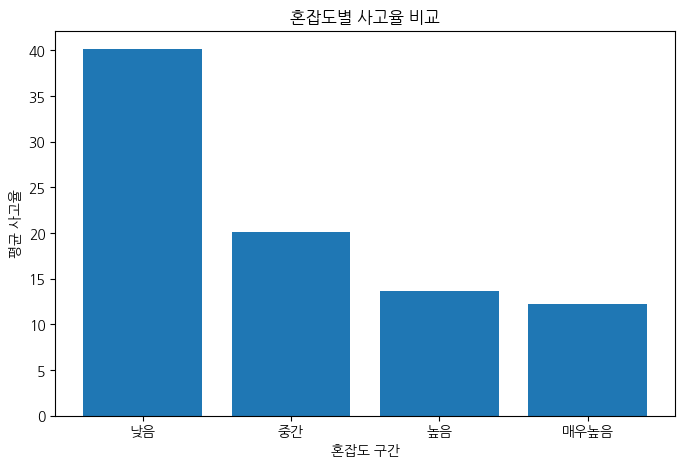

In [ ]:
# 혼잡도 수치 데이터를 4개의 구간(사분위수)으로 나눈다.
# pd.qcut은 데이터 개수가 각 구간에 비슷하게 들어가도록 자르는 함수.
station_merged['혼잡도구간'] = pd.qcut(
    station_merged['혼잡도'],
    q=4,
    labels=['낮음', '중간', '높음', '매우높음']
)

# 혼잡도구간을 기준으로 그룹화하고 각 구간의 사고율 평균을 계산
rate_by_density = station_merged.groupby('혼잡도구간')['사고율'].mean()

print(rate_by_density)

plt.figure(figsize=(8,5))

# x축에는 혼잡도 구간, y축에는 평균 사고율을 넣은 막대그래프
plt.bar(rate_by_density.index, rate_by_density.values)

plt.xlabel('혼잡도 구간')
plt.ylabel('평균 사고율')
plt.title('혼잡도별 사고율 비교')

plt.show()

**3-2. 혼잡도 구간별 비교**

* 직관적으로 확인하기 위해 혼잡도를 4개 구간으로 나누어 평균 사고율을 비교했다. 낮음:40.14, 중간:20.09, 높음:13.70, 매우높음:12.24 로 혼잡도가 증가할수록 사고율이 감소하는 패턴이 나타났다.

**가설 3번 정리**

* 혼잡도가 높은 역이 역구내사고가 더 많이 발생하는 것이 아니라 구조적으로 비효율적이거나 위험한 역이 더 많이 발생한다고 해석된다.

### 8-3. 열차 내 사고

#### 가설 1. 이용객이 몰리는 피크 타임과 동선이 복잡한 환승역이 결합되는 지점에서 혼잡도가 극대화되며, 이것이 열차 내 사고의 주된 원인이 될 것이다.

In [ ]:
import plotly.express as px
# 출퇴근 여부별 월간 총 승객 수
# 출퇴근여부'별로 '월간총승객'의 평균 계산
commute_stats = df.groupby('출퇴근여부', as_index=False)['월간총승객'].mean()

# 정렬 (출근 -> 퇴근 -> 기타)
category_order = ['출근', '퇴근', '기타']
commute_stats['출퇴근여부'] = pd.Categorical(commute_stats['출퇴근여부'], categories=category_order, ordered=True)
commute_stats = commute_stats.sort_values('출퇴근여부')


fig = px.bar(
    commute_stats,
    x='출퇴근여부',
    y='월간총승객',
    color='출퇴근여부',
    title='출퇴근 여부별 평균 월간 총 승객 수',
    labels={'월간총승객': '평균 승객 수 (명)'},
    template='plotly_white'
)

fig.show()

**1-1.출퇴근 월간 총 승객 수**

- 퇴근(17-20시) > 출근(07-10시) > 기타 순으로 이용객이 많다.
- 퇴근 시간대의 평균 이용객이 12만 명 이상으로 가장 높으며, 이는 기타 시간대보다 2배 가까이 많은 수치이다.
- 특정 시간대에 인구 밀도가 급격히 높아지는 물리적 환경이 조성됨을 보여준다.

In [ ]:
# 출퇴근여부별 전체 사고 대비 열차내 사고 비중
# 출퇴근여부별 전체 사고 건수
total_counts = df.groupby('출퇴근여부').size().reset_index(name='전체사고') # 출퇴근여부별 전체 사고 건수


# '사고유형' 컬럼에서 '열차내 사고'만 필터링
train_acc_only = df[df['사고유형'].str.contains('열차내 사고', na=False)]
train_counts = train_acc_only.groupby('출퇴근여부').size().reset_index(name='열차내사고')

analysis_df = pd.merge(train_counts, total_counts, on='출퇴근여부', how='left') # 데이터 병합
analysis_df['전체사고'] = analysis_df['전체사고'].fillna(0) # 사고비율 계산
analysis_df['열차내사고'] = analysis_df['열차내사고'].fillna(0)
analysis_df['사고비율'] = (analysis_df['열차내사고'] / analysis_df['전체사고']) * 100 # 비율 산출
analysis_df['사고비율'] = analysis_df['사고비율'].fillna(0)

# 정렬 (출근 -> 퇴근 -> 기타)
category_order = ['출근', '퇴근', '기타']
analysis_df['출퇴근여부'] = pd.Categorical(analysis_df['출퇴근여부'], categories=category_order, ordered=True)
analysis_df = analysis_df.sort_values('출퇴근여부')


fig = px.bar(
    analysis_df,
    x='출퇴근여부',
    y='사고비율',
    title='출퇴근여부별 전체 사고 대비 열차 내 사고 비중 (%)',
    color='사고비율',
    template='plotly_white'
)

fig.show()

**1-2. 출퇴근여부 별 열차 내 사고 비중**

- 이용객 수 1 위였던 퇴근 시간보다, 출근 시간대의 열차 내 사고 비중이 가장 높다.
- 이는 단순히 사람이 많은 것을 넘어, 출근 시의 시간적 압박과 무리한 승차가 열차 내 밀집도를 한계치까지 발생하여 사고로 이어진다는 것을 시사한다.
- 정해진 시간에 도착해야 하는 출근 특성상 특정 열차에 인원이 과하게 몰리는 현상이 발생한다. 이때 열차가 급제동하거나 흔들리면 승객들이 중심을 잡지 못하고 연쇄적으로 넘어지는 사고가 발생하기 쉽다.
- 기타 시간대에 비해 출근 시간대의 사고 비중이 훨씬 높으므로, 혼잡도가 사고 유형을 결정짓는 핵심 변수임을 증명한다.

In [ ]:
# 열차 내 사고 top 역의 환승여부
train_only_df = df[df['사고유형'] == '열차내 사고'].copy() # '열차내 사고'인 행만 추출
train_only_df.columns = train_only_df.columns.str.strip() # 공백 제거
station_stats = train_only_df.groupby(['역명', '환승여부'], as_index=False).size() # 역명과 환승여부를 기준으로 사고 발생 횟수 계산
station_stats.rename(columns={'size': '사고건수'}, inplace=True)
top10_stations = station_stats.sort_values('사고건수', ascending=False).head(10) # 상위 10개 역만 추출


fig = px.bar(
    top10_stations,
    x='사고건수',
    y='역명',
    color='환승여부',
    title='열차 내 사고 TOP 10 역',
    text_auto=True,
    template='plotly_white',
    category_orders={'역명': top10_stations['역명'].tolist()}
)

fig.show()

**1-3.열차 내 사고 빈도가 높은 역**

- 상위 10개 역 중 90%가 환승역이다.
- 청량리역은 20건으로 가장 높은 수치를 기록하고 있다. 청량리역은 1호선, 수인분당선, 경의중앙선, 경춘선, ktx 등이 얽힌 초거대 허브역이다.
- 환승역은 여러 노선의 승객이 움직이면서 열차 내 혼잡도가 급격하게 증가하는 지점이다. 특히 승하차 상황에 열차 안에서 밀치거나 중심을 잃는 사고가 집중될 수 있다.
- 사고는 인파가 겹치고 동선이 뒤엉키는 구조적 결절점에서 집중 발생한다.

**가설 1번 정리**
- 지하철 사고는 우연히 발생하는 것이 아니라, 최고 혼잡 시간과 혼잡한 환승역이 만나는 지점에서 폭발적으로 증가한다.
- 퇴근 시간보다 이용객이 적은 출근 시간대에 사고 비중이 더 높은 것은, 출근 시 승객들이 열차 내부로 무리하게 진입하는 압착 밀집이 더 심각하기 때문으로 해석된다.

#### 가설 2. 승강장의 선형이 곡선일 경우에 열차 내 사고가 더 많이 발생할 것이다.

In [ ]:
# 열차 내 사고 top10 역 (구조별 비교)
station_platform_info = df[['역명', '승강장선형']].drop_duplicates()
top10_details = pd.merge(top10_stations, station_platform_info, on='역명', how='left')
top10_details.set_index('역명', inplace=True)

fig = px.bar(
    top10_details,
    x='사고건수',
    y=top10_details.index,
    color='승강장선형',
    title='열차 내 사고 TOP 10 역 (구조별 비교)',
    text_auto=True,
    template='plotly_white'
)

fig.show()

**2-1. 열차 내 사고 TOP 10역**

- 열차 내 사고 발생 건수 상위 10개 역 중 청량리, 서울, 신림, 천호, 도봉산, 방배역 등 6개 역(60%)이 곡선 승강장 구조이다. 이는 전체적인 사고 발생의 기저에 '구조적 결함'이 존재함을 시사한다.

In [ ]:
# 열차 내 사고 다발 top10에서 사고유형중 열차 내 사고가 가장 많은 역 추출
target_stations = ['시청역', '신림역', '청량리역',  '도봉산역'] # 분석할 특정 4개 역(시청, 신림, 청량리, 도봉산)의 리스트를 만든다.
filtered_df = df[df['역명'].isin(target_stations)].copy()
analysis_df = filtered_df.groupby(['역명', '사고유형']).size().reset_index(name='사고건수') # '역명'과 '사고유형' 두 가지를 기준으로 그룹화

fig = px.bar(
    analysis_df,
    x='역명',
    y='사고건수',
    color='사고유형',
    barmode='group',
    title='주요 4개 역별 사고 유형',
    text_auto=True,
    template='plotly_white'
)

fig.show()

**2-2. 주요 4개역 사고 유형**

- 주요 4개 역 선별 기준: 전체 사고 유형 중 '열차 내 사고'가 가장 빈번하게 발생하는 상위 10개 역을 전수 조사한 뒤, 사고 유형 중 '열차 내 사고'의 건수가 타 사고보다 높은 역을 선별했다.
- 차트를 보면 모든 역에서 초록색 막대(열차 내 사고)가 독보적으로 높다. 이는 이 역들이 단순히 사고가 많은 것이 아니라, 열차 내부라는 특정 공간에서 발생하는 물리적 위험에 취약한 구조를 가졌음을 입증한다.

In [ ]:
# 주요 4개 분석 역의 승강장 선형 비율
target_stations = ['시청역', '신림역', '청량리역', '도봉산역'] # 분석 타겟인 4개 역의 데이터만 추출
target_df = df[df['역명'].isin(target_stations)].copy()
line_data = target_df[['역명', '승강장선형']].drop_duplicates() # 역별로 '승강장선형' 정보를 하나씩만 남긴다.
chart_data = line_data['승강장선형'].value_counts().reset_index() # 선형별 개수 집계

fig = px.pie(
    chart_data,
    values='count',
    names='승강장선형',
    title='주요 4개 분석 역의 승강장 선형 비율',
    color='승강장선형')

fig.show()

**2-3. 주요 4개 분석의 승강장 선명 비율**

- 주요 4개 역들의 공통점을 분석한 결과, 열차 내 사고가 가장 잦은 4개의 분석 역 중 3개의 역(75%)이 곡선 승강장으로 확인되었다.
- 곡선 선로의 열차 흔들림으로 인해서 승객들이 중심을 잃고 넘어지거나 주변 승객들과 충돌하는 사고가 일어날 위험이 크다.
- 열차 내 사고가 빈번하게 발생하는 역들을 역추적했을 때 '곡선'이라는 결론에 도달한다는 것은, 곡선 선형이 열차 내 사고가 발생하는 결정적 변수임을 시사한다.

In [ ]:
# 직선 승강장 역만 필터링
straight_only = top10_details[top10_details['승강장선형'] == '직선'].copy()

# '환승노선수' 컬럼 추가
# 'straight_only'의 인덱스인 '역명'을 컬럼으로 변환하여 병합 준비
straight_only_temp = straight_only.reset_index()
straight_only_with_transfer = straight_only_temp.merge(
    df[['역명', '환승노선수']].drop_duplicates(subset=['역명']),
    on='역명',
    how='left'
)
# '역명'을 인덱스로 설정
straight_only_with_transfer.set_index('역명', inplace=True)

# 환승여부 그래프
fig_left = px.bar(
    straight_only,
    x=straight_only.index,
    y=[1] * len(straight_only), # 모든 높이를 동일하게 맞춰 라벨처럼 보이게 함
    color='환승여부',
    text='환승여부',
    title='1. 직선 역: 환승 여부',
    template='plotly_white')

fig_left.show()

# 환승 노선 수 그래프
fig_right = px.bar(
    straight_only_with_transfer,
    x=straight_only_with_transfer.index,
    y='환승노선수',
    text='환승노선수',
    title='2. 직선 역: 환승 노선 수',
    template='plotly_white')


fig_right.show()

**2-4. 직선 역 환승역, 환승 노선 수**

- 열차 내 사고 top10에 포함된 직선 역들은 100% 환승역이며, 대부분 2~3개의 노선이 겹치는 복잡한 거점이다.
- 직선 역에서 사고가 나는 이유는 '승강장 선형'때문이 아니라, '복잡한 환승 동선과 인파' 때문임을 알 수 있다.

**가설 2번 정리**
1. 구조적 위험(곡선 승강장)
- 주요 4개역의 승강장 중 3개의 역이 곡선 승강장으로 분석된다.
2. 직선 환승역(인파 관리)
- 열차 내 사고가 구조적 문제가 아닌 '밀집'에서 기인한다.

#### 가설 3.노후화된 역에서 열차 내 사고가 많이 발생할 것이다.

In [ ]:
# 열차 내 사고 다발 TOP10 역 및 역 노후도 현황
train_acc_df = df[df['사고유형'].str.strip() == '열차내 사고']
station_stats = train_acc_df.groupby('역명').agg({  # 역별로 사고 건수와 역노후도의 평균계산
    '사고유형': 'count',
    '역노후도': 'mean'
}).reset_index()

station_stats.columns = ['역명', '사고건수', '평균_역노후도']
top_accident_stations = station_stats.sort_values('사고건수', ascending=False).head(10); # 상위 10개 역 추출


fig = px.bar(
    top_accident_stations,
    x='사고건수',
    y='역명',
    color='평균_역노후도',
    title='열차 내 사고 다발 TOP10 역 및 역 노후도 현황 ',
    text_auto=True,
    template='plotly_white',
    category_orders={'역명': top_accident_stations['역명'].tolist()},
)

fig.show()

**가설 3번 정리**

- 청량리역(노후도 1위, 사고 1위): 노후도가 가장 높은 노란색 계열이며 사고 건수도 20건으로 압도적이다.
- 시청역, 종로3가역, 서울역 등 노란색/주황색(노후도 40~50년 이상)역들이 상위권에 포진되어 있다.
- 반례 데이터(도봉산, 천호역): 도봉산과 천호역은 노후도가 30년 미만임에도 불구하고 열차 내 사고 발생 top10에 진입하였다. 이는 노후도 외에 '곡선 선형'같은 다른 변수가 강력하게 작용했음을 시사한다.

### 8-4. 승강장설비관련 사고

In [ ]:
# 승강설비관련 사고 분석에 필요한 집계, 파생변수, 구간변수 생성

# 승강설비관련 사고 여부 (승강설비관련이면 1 아니면 0)
df['승강설비관련사고'] = (df['사고유형'] == '승강설비관련').astype(int)

# 역 단위로 집계 (호선과 역명 기준으로 묶어서 승강설비관련 사고와 역 특성 변수만 요약)
station_escalator = df.groupby(['호선', '역명'], as_index=False).agg({
    '승강설비관련사고': 'sum',
    '사고유형': 'count',
    '역노후도': 'first',
    '승강기_개수': 'first',
    '일간총승객': 'first',
    '면적': 'first'
}).rename(columns={
    '승강설비관련사고': '승강설비관련사고건수',
    '사고유형': '전체사고건수'
})

#------------------------------------------------------------------------------
# 승강설비관련 파생변수 추가 생성
# 1. 전체 사고 중 승강설비관련 사고가 차지하는 비중
station_escalator['승강설비관련사고비중'] = (
    station_escalator['승강설비관련사고건수'] / station_escalator['전체사고건수']
)

# 2. 승강기 1대당 승강설비관련 사고
# 역명 기준으로 집계
station_elevator = df.groupby('역명', as_index=False).agg({
    '승강설비관련사고': 'sum',
    '승강기_개수': 'mean',
    '역노후도': 'mean'
}).rename(columns={
    '승강설비관련사고': '승강설비관련사고건수'
})

# 각 역의 승강기 1대당 사고 계산(사고건수를 승강기 수로 나눠, 설비 수를 고려한 사고 수준을 확인)
station_elevator['승강기1대당사고'] = (
    station_elevator['승강설비관련사고건수'] / station_elevator['승강기_개수']
)

# 승강기 수가 0 이하인 경우는 계산 불가하므로 결측 처리
station_elevator.loc[station_elevator['승강기_개수'] <= 0, '승강기1대당사고'] = np.nan

# station_elevator에서 노후도를 4개 구간으로 나눔
station_elevator['노후도구간'] = pd.qcut(
    station_elevator['역노후도'],
    4,
    labels=['낮음', '중하', '중상', '높음'],
    duplicates='drop'
)

#------------------------------------------------------------------------------
# 구간 변수 생성
# 1. 역노후도를 4개 분위로 나누어 구간화
station_escalator['노후도구간'] = pd.qcut(
    station_escalator['역노후도'],
    4,
    labels=['낮음', '중하', '중상', '높음'],
    duplicates='drop'
)

# 2. 일간총승객을 4개 분위로 나누어 구간화
station_escalator['승객수구간'] = pd.qcut(
    station_escalator['일간총승객'],
    4,
    labels=['적음', '중하', '중상', '많음'],
    duplicates='drop'
)

# 3. 승강기 개수를 4개 분위로 나누어 구간화
station_escalator['승강기구간'] = pd.qcut(
    station_escalator['승강기_개수'],
    4,
    labels=['적음', '중하', '중상', '많음'],
    duplicates='drop'
)

# 4. 면적을 4개 분위로 나누어 구간화
station_escalator['면적구간'] = pd.qcut(
    station_escalator['면적'],
    4,
    labels=['작음', '중하', '중상', '큼'],
    duplicates='drop'
)

#### 가설 1. 노후한 역일수록 승강설비관련 사고가 더 많이 발생할 것이다.



/tmp/ipykernel_1815/3659156320.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



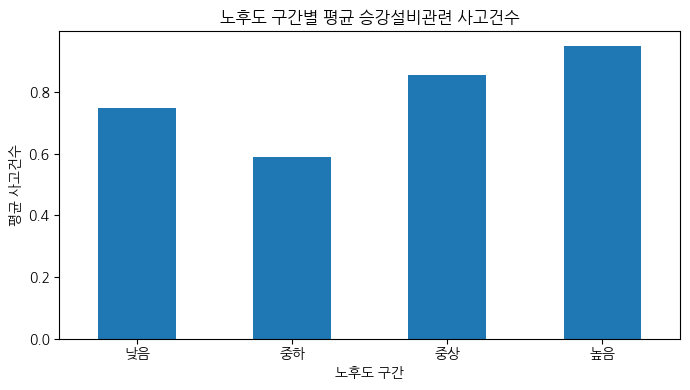

In [ ]:
# 노후도 구간별 평균 승강설비관련 사고건수

station_escalator.groupby('노후도구간')['승강설비관련사고건수'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('노후도 구간별 평균 승강설비관련 사고건수')
plt.xlabel('노후도 구간')
plt.ylabel('평균 사고건수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**1-1. 노후도 구간별 평균 승강설비관련 사고건수**

* 전반적으로 노후도가 높을수록 평균 사고건수가 증가하는 경향이 보인다. 다만
단조롭게 증가하진 않아, 노후도와 승강설비관련 사고의 관계가 완전히 선형적이라기보다는 전반적으로 양의 상관을 보인다고 할 수 있다. 즉, 이 차트만으로는 노후도가 사고의 원인이다라고는 단정할 수 없다.

/tmp/ipykernel_1815/1542346481.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



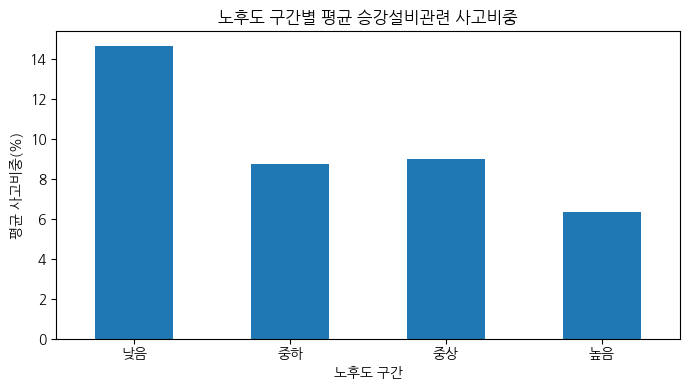

In [ ]:
# 노후도 구간별 평균 승강설비관련 사고비중

(station_escalator.groupby('노후도구간')['승강설비관련사고비중'].mean() * 100).plot(
    kind='bar', figsize=(7, 4)
)
plt.title('노후도 구간별 평균 승강설비관련 사고비중')
plt.xlabel('노후도 구간')
plt.ylabel('평균 사고비중(%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**1-2. 노후도 구간별 평균 승강설비관련 사고비중**

* 위 차트는 해당 노후도 구간 집단 내에서의 승강설비관련 사고는 얼마나 차지하는가를 보여준다. 노후도가 낮은 역일수록 전체 사고 중 승강설비관련 사고가 차지하는 비율은 오히려 높고 노후도가 높은 역일수록 그 비율은 낮아진다. 위 차트와 같이 보면 건수는 노후도가 높은 역에서 증가하지만 비중 자체는 노후도가 낮은 역에서 더 크다. 즉 노후도가 높아질수록 사고의 절대건수는 증가하는 경향이 있으나 이는 노후된 역에서는 승강설비 관련 사고 뿐만 아니라 다른 유형의 사고도 함께 증가했을 가능성을 보인다.

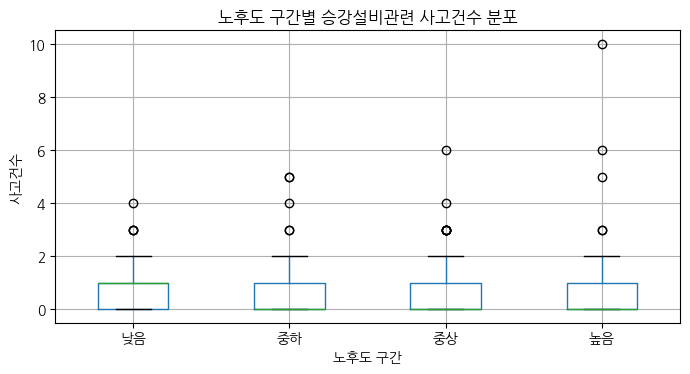

In [ ]:
# 노후도 구간별 승강설비관련 사고건수 분포

station_escalator.boxplot(
    column='승강설비관련사고건수',
    by='노후도구간',
    figsize=(7, 4)
)
plt.title('노후도 구간별 승강설비관련 사고건수 분포')
plt.suptitle('')
plt.xlabel('노후도 구간')
plt.ylabel('사고건수')
plt.tight_layout()
plt.show()

**1-3. 노후도 구간별 승강설비관련 사고건수 분포**

* 대부분의 구간에서 중앙값이 낮고 0에서 1 근처에 몰려있다. 하지만 상위 이상치들이 존재한다. 특히 노후 구간에서 더 높은 이상치가 나타난다. 이는 승강설비관련사고가 모든 역에서 고르게 많은 것이 아니라 일부 역에서 많이 발생하는 구조임을 보여준다. 즉, 노후 구간 전체가 다 위험한 것이 아니라 노후 구간 내 일부 역이 평균을 끌어올리고 있을 가능성이 존재한다.

/tmp/ipykernel_1815/1732393979.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



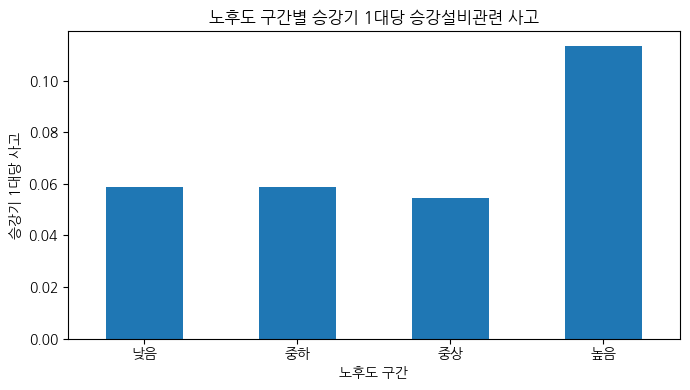

In [ ]:
# 노후도 구간별 승강기 1대당 승강설비관련 사고

station_elevator.groupby('노후도구간')['승강기1대당사고'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('노후도 구간별 승강기 1대당 승강설비관련 사고')
plt.xlabel('노후도 구간')
plt.ylabel('승강기 1대당 사고')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**1-4. 노후도 구간별 승강기 1대당 승강설비관련 사고**

* 위 가설에 대해 ‘단순히 설비(승강기) 수가 많으니까 사고가 많은 것이 아닌가?’ 라는 반론을 제기할 수 있다. 따라서 설비 수를 보정하여 노후도 구간별로 집계한 차트이다. 하지만 차트를 보면 승강기 수를 감안해도 가장 노후한 구간에서 사고 부담이 크다는 걸 알 수 있다. 즉, 단순히 승강기 수가 많아서 사고건수가 큰 것이 아니라 노후한 역일수록 승강설비관련 사고가 더 자주 발생한다는 것이다.

**가설 1번 정리**

* **노후한 역일수록 승강설비관련 사고가 더 많이 발생할 것이다.**

- 노후도가 높은 역일수록 승강설비관련 사고의 평균 건수는 전반적으로 증가하는 경향이 나타났다. 특히 가장 노후한 구간에서 사고 수준이 상대적으로 높게 나타나 역사 노후도가 승강설비관련 사고와 일정한 관련성을 가질 가능성을 확인할 수 있었다. 다만 증가 흐름이 모든 구간에서 완전히 일정하지는 않았고, 사고 분포 역시 일부 역에 집중되는 모습이 보여 노후도만으로 사고를 설명하기는 어려우나 승강기 수를 조정한 이후에도 높은 노후 구간의 사고 부담이 크게 나타나는 것으로 보아 단순히 설비 수 때문이 아니라 노후한 역사 환경 자체가 사고 위험을 높이는 요인 중 하나일 수 있음을 시사한다.

#### 가설 2. 이용객 및 설비 규모가 큰 역일수록 승강설비관련 사고가 더 많이 발생할 것이다.

/tmp/ipykernel_1815/800098838.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



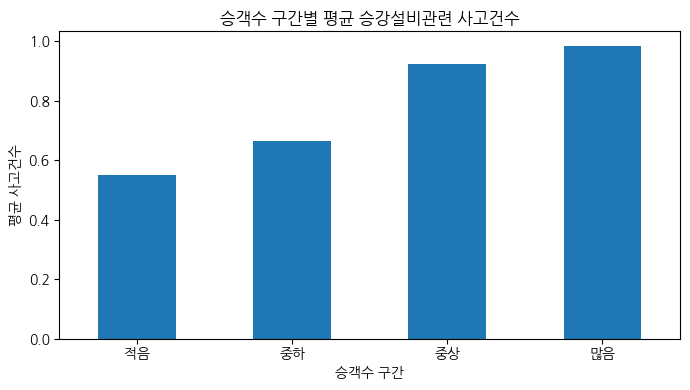

In [ ]:
# 승객수 구간별 평균 승강설비관련 사고건수

station_escalator.groupby('승객수구간')['승강설비관련사고건수'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('승객수 구간별 평균 승강설비관련 사고건수')
plt.xlabel('승객수 구간')
plt.ylabel('평균 사고건수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**2-1. 승객수 구간별 평균 승강설비관련 사고건수**

* 승객수 구간별 평균 승강설비관련 사고건수는 전반적으로 증가한다. 이는 이용객이 많은 역일수록 승강설비를 접하는 사람 수 자체가 많아지기 때문에 사고 발생 가능성도 함께 커질 수 있다로 해석할 수 있다. 다만 역의 규모나 설비 수와 함께 영향을 받을 수 있으므로 단일 요인으로만 보기는 어렵다.

/tmp/ipykernel_1815/2256631703.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



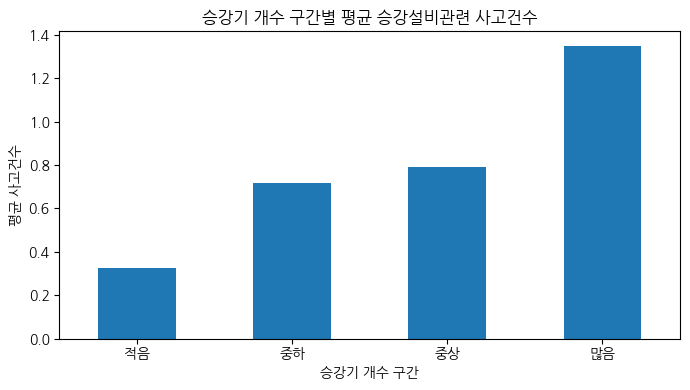

In [ ]:
# 승강기 개수 구간별 평균 승강설비관련 사고건수

station_escalator.groupby('승강기구간')['승강설비관련사고건수'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('승강기 개수 구간별 평균 승강설비관련 사고건수')
plt.xlabel('승강기 개수 구간')
plt.ylabel('평균 사고건수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**2-2. 승강기 개수 구간별 평균 승강설비관련 사고건수**

* 승강기 개수 구간별 평균 승강설비관련 사고건수는 뚜렷한 증가 패턴을 보인다. 이는 설비가 많으니, 이용도 많을 가능성이 크며, 결국 사고건수가 커진다로 해석할 수 있다. 즉, 설비 수 증가에 따른 노출 효과로 해석할 수는 있다. 하지만 동시에 역 규모나 혼잡도와도 연결될 수 있으므로 이 또한 단독 원인으로 보기는 어렵다.

/tmp/ipykernel_1815/3517245664.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



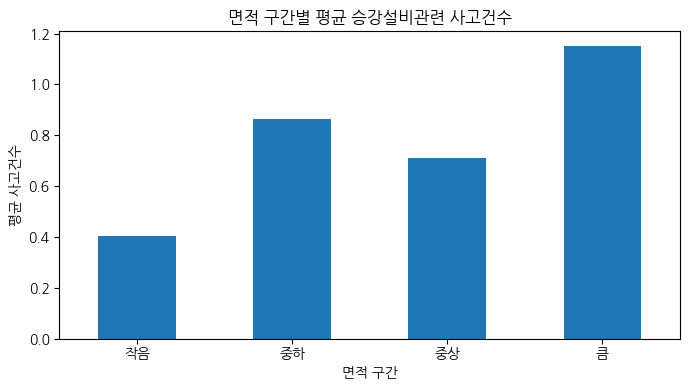

In [ ]:
# 면적 구간별 평균 승강설비관련 사고건수

station_escalator.groupby('면적구간')['승강설비관련사고건수'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('면적 구간별 평균 승강설비관련 사고건수')
plt.xlabel('면적 구간')
plt.ylabel('평균 사고건수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**2-3. 면적 구간별 평균 승강설비관련 사고건수**

* 면적 구간별 평균 승강설비관련 사고건수는 작은 역보다 큰 역 구간에서 전반적으로 더 높게 나타난다. 특히 가장 큰 면적 구간에서 평균 사고건수가 가장 높게 나타나 역의 공간 규모가 클수록 승강설비관련 사고도 함께 증가할 가능성을 보여준다. 이는 대형 역사일수록 이동 동선이 길고 설비 이용 범위가 넓어 사고 발생 지점도 많아질 수 있다로 해석할 수 있다. 다만 차트가 완전히 일정한 증가 흐름은 아니므로, 면적은 보조적 규모 지표로 보는 것이 적절하다고 본다.

/tmp/ipykernel_1815/1115317249.py:4: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



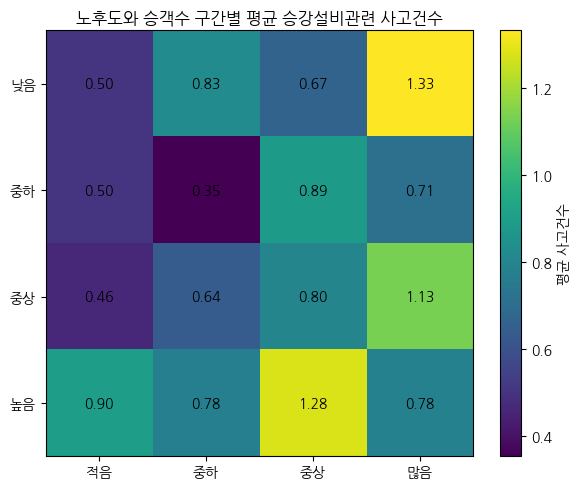

In [ ]:
# 노후도와 승객수 구간별 평균 승강설비관련 사고건수

# 노후도구간 × 승객수구간별 평균 승강설비관련 사고건수 계산
heatmap_data = station_escalator.pivot_table(
    index='노후도구간',
    columns='승객수구간',
    values='승강설비관련사고건수',
    aggfunc='mean'
)

# 히트맵 출력
plt.figure(figsize=(6, 5))
plt.imshow(heatmap_data, aspect='auto')
plt.colorbar(label='평균 사고건수')
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.title('노후도와 승객수 구간별 평균 승강설비관련 사고건수')

# 각 셀 안에 평균값 표시
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]
        if pd.notna(value):
            plt.text(j, i, f'{value:.2f}', ha='center', va='center')

plt.tight_layout()
plt.show()

**2-4. 노후도와 승객수 구간별 평균 승강설비관련 사고건수**

* 노후도와 승객수 구간을 함께 보면 승객수가 많은 구간에서 전반적으로 평균 사고건수가 높게 나타나는 경향이 확인된다. 특히 일부 노후도 구간에서는 승객수 증가와 함께 사고건수가 뚜렷하게 커지는 모습이 나타나 승강설비관련 사고가 단순히 노후도 하나만이 아니라 이용객 규모와 결합된 영향을 받아 발생할 가능성을 보여준다. 즉, 사고는 노후도만으로 설명되기보다 많은 승객이 이용하는 환경에서 더 크게 나타날 수 있다고 해석할 수 있다. 다만 구간별 편차가 존재하므로, 특정 한 변수보다 복합적인 요인의 결과로 이해해야 한다.

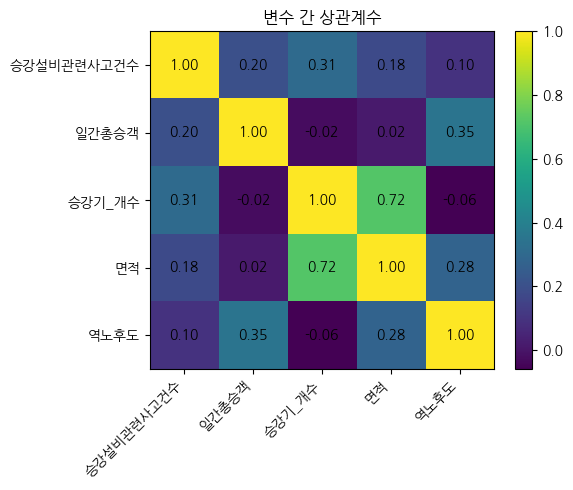

In [ ]:
# 변수 간 상관계수

# 승강설비관련 사고건수와 주요 변수들 간 상관계수 계산
corr = station_escalator[['승강설비관련사고건수', '일간총승객', '승강기_개수', '면적', '역노후도']].corr()

# 히트맵 출력
plt.figure(figsize=(6, 5))
plt.imshow(corr, aspect='auto')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), corr.columns)

# 각 셀 안에 상관계수 값 표시
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')

plt.title('변수 간 상관계수')
plt.tight_layout()
plt.show()

**2-5. 변수 간 상관계수**

* 변수 간 상관계수를 보면 승강설비관련 사고건수는 승강기 개수와 가장 높은 양의 상관을 보였고 일간총승객과 면적도 약한 양의 관계를 나타냈다. 이는 승강설비관련 사고가 이용객 수, 설비 수, 공간 규모와 같은 역의 전체 규모 요인과 함께 관련되어 있음을 시사한다. 특히 승강기 개수와 면적 사이의 상관도 높게 나타나, 규모가 큰 역일수록 설비 수 역시 함께 증가하는 구조를 확인할 수 있다. 따라서 승강설비관련 사고는 단일 변수보다 여러 규모 요인이 함께 작용한 결과로 해석하는 것이 타당하다고 본다.

**가설 2번 정리**

* **이용객 및 설비 규모가 큰 역일수록 승강설비관련 사고가 더 많이 발생할 것이다.**

* 가설 2는 지지되었다. 이용객 수와 설비 규모가 큰 역일수록 승강설비관련 사고의 평균 건수가 전반적으로 높아지는 경향이 나타났다. 특히 승객 수, 승강기 개수, 면적이 큰 구간에서 사고 건수가 더 높게 나타나 승강설비관련 사고가 단순한 개별 설비 문제라기보다 이용 규모와 공간 규모가 큰 역사 환경에서 더 많이 발생할 가능성을 보여준다. 또한 노후도와 승객 수를 함께 본 결과에서도 승객 수가 많은 구간에서 사고 수준이 상대적으로 높게 나타나 사고 발생에는 노후도뿐 아니라 이용객 규모가 함께 작용하고 있음을 확인할 수 있었다. 다만 변수 간 상관을 보면 승강기 개수, 면적, 승객 수가 서로 연결되어 있어, 특정 한 변수의 영향만으로 해석하기보다는 역의 전체 규모와 이용량이 복합적으로 반영된 결과로 볼 수 있다.

#### 가설 3. 승강설비관련 사고는 출퇴근 시간에 집중되기보다 강수와 시간대 특성에 따라 전반적으로 나타날 것이다.

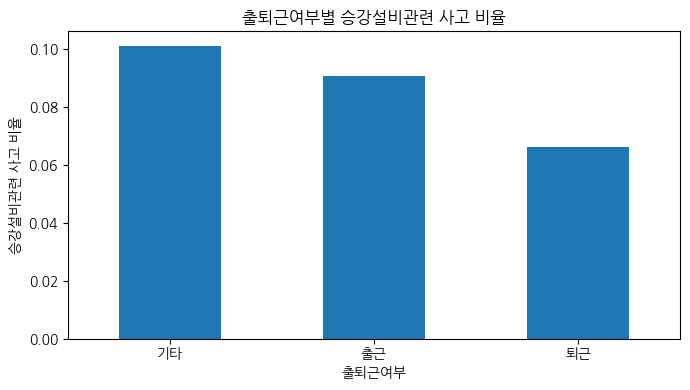

In [ ]:
# 출퇴근여부별 승강설비관련 사고 비율

df.groupby('출퇴근여부')['승강설비관련사고'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('출퇴근여부별 승강설비관련 사고 비율')
plt.xlabel('출퇴근여부')
plt.ylabel('승강설비관련 사고 비율')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**3-1. 출퇴근여부별 승강설비관련 사고 비율**

* 출퇴근여부별 승강설비관련 사고 비율을 보면 출근이나 퇴근 시간대보다 기타 시간대에서 오히려 더 높은 비율이 나타난다. 이는 승강설비관련 사고가 다른 사고 유형과 달리 출퇴근 시간에 집중되어 발생한다기보다 하루 전체 시간대에 걸쳐 비교적 분산되어 나타날 가능성을 보여준다. 특히 퇴근 시간대의 비율이 가장 낮게 나타난 점을 고려하면 승강설비관련 사고는 단순히 이용객이 몰리는 출퇴근 시간의 문제로만 보기 어렵다. 따라서 이 가설의 '출퇴근 시간에 집중되기보다’라는 방향성과 부합한다고 해석할 수 있다.

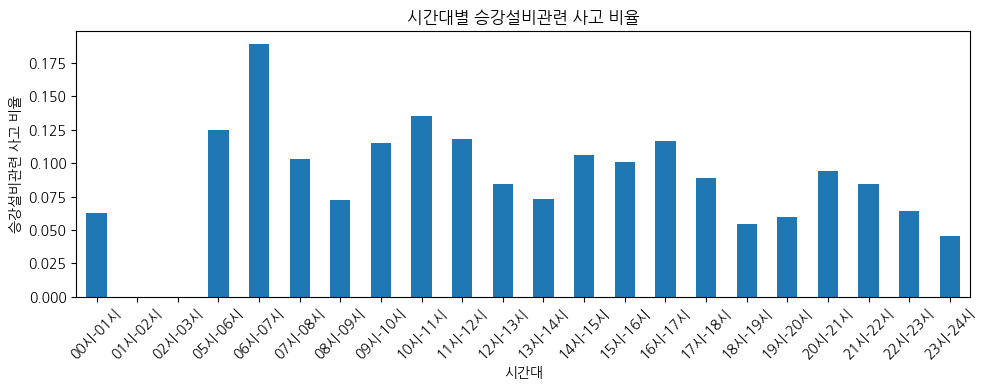

In [ ]:
# 시간대별 승강설비관련 사고 비율

df.groupby('시간대')['승강설비관련사고'].mean().sort_index().plot(
    kind='bar', figsize=(10, 4)
)
plt.title('시간대별 승강설비관련 사고 비율')
plt.xlabel('시간대')
plt.ylabel('승강설비관련 사고 비율')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**3-2. 시간대별 승강설비관련 사고 비율**

* 시간대별 승강설비관련 사고 비율을 보면 사고가 특정 한두 시간대에만 몰려 있지 않고 여러 시간대에 걸쳐 나타나는 모습이 확인된다. 이른 아침 시간대의 비율이 비교적 높게 나타나기는 했지만, 오전 중반과 오후, 일부 저녁 시간대에서도 일정 수준의 사고 비율이 유지된다. 이는 승강설비관련 사고가 단순히 출근이나 퇴근에 해당하는 혼잡 시간대에만 집중되는 것이 아니라 시간대별 환경과 이용 패턴에 따라 전반적으로 발생할 수 있음을 시사한다. 즉, 사고는 특정 피크 시간대에 국한되기보다 여러 시간대에 분산된 특성을 가진다고 볼 수 있다.

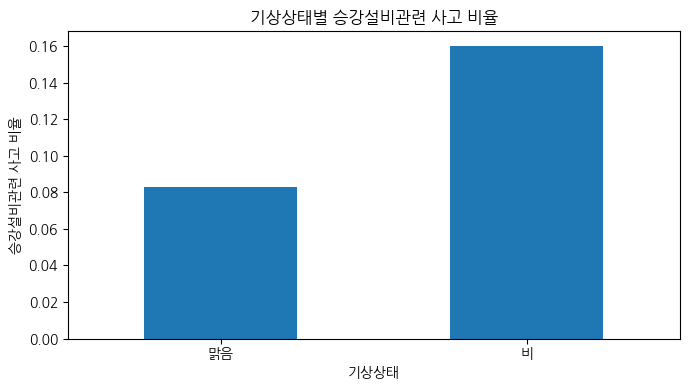

In [ ]:
# 기상상태별 승강설비관련 사고 비율

df.groupby('기상상태')['승강설비관련사고'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('기상상태별 승강설비관련 사고 비율')
plt.xlabel('기상상태')
plt.ylabel('승강설비관련 사고 비율')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**3-3. 기상상태별 승강설비관련 사고 비율**

* 기상상태별 승강설비관련 사고 비율을 보면 비가 오지 않는 날보다 비가 오는 날에 사고 비율이 훨씬 높게 나타난다. 이는 강수로 인해 바닥이 미끄러워지거나 보행 안정성이 저하되면서 승강설비 이용 과정에서 사고 위험이 커질 수 있음을 보여준다. 즉, 승강설비관련 사고는 날씨 조건, 특히 강수의 영향을 함께 받는 것으로 해석할 수 있다. 따라서 강수는 승강설비관련 사고를 설명하는 중요한 환경적 요인 중 하나라고 볼 수 있다.

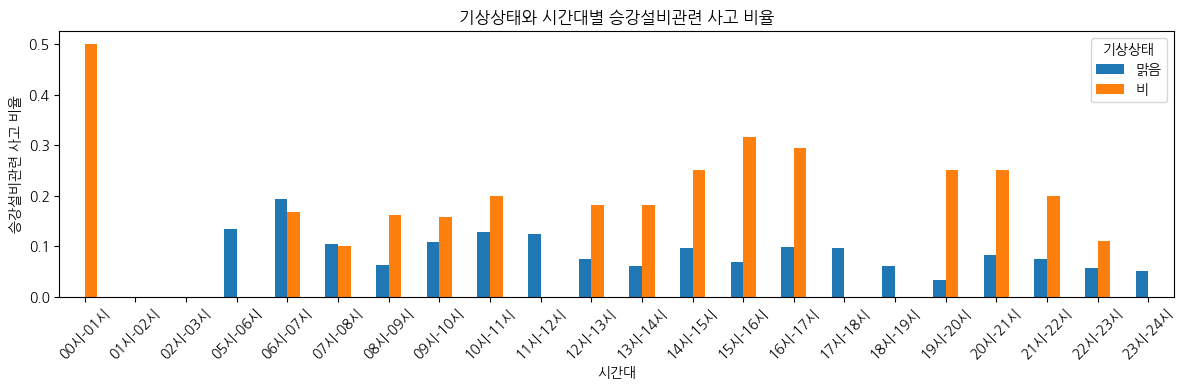

In [ ]:
# 강수여부와 시간대별 승강설비관련 사고 비율

# 시간대와 기상상태별 승강설비관련 사고 비율 계산
rain_time = df.pivot_table(
    index='시간대',
    columns='기상상태',
    values='승강설비관련사고',
    aggfunc='mean'
).sort_index()

# 막대그래프 출력
rain_time.plot(kind='bar', figsize=(12, 4))
plt.title('기상상태와 시간대별 승강설비관련 사고 비율')
plt.xlabel('시간대')
plt.ylabel('승강설비관련 사고 비율')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**3-4. 기상상태와 시간대별 승강설비관련 사고 비율**

* 기상상태와 시간대별 사고 비율을 함께 보면 비가 오는 경우 전반적으로 더 높은 사고 비율이 나타나며 그 차이는 시간대에 따라 다르게 나타난다. 일부 시간대에서는 비가 오는 경우 사고 비율이 특히 크게 높아져 승강설비관련 사고가 단순히 특정 시간대 자체의 문제가 아니라 강수와 시간대 특성이 결합될 때 더 두드러질 수 있음을 보여준다. 이는 같은 시간대라도 기상 조건에 따라 사고 위험 수준이 달라질 수 있음을 의미한다. 따라서 승강설비관련 사고는 특정 시간대의 집중 현상보다는 강수와 시간대 특성이 함께 작용하는 것으로 이해하는 것이 더 적절하다.

**가설 3번 정리**

* **승강설비관련 사고는 출퇴근 시간에 집중되기보다 강수와 시간대 특성에 따라 전반적으로 나타날 것이다.**

* 가설 3은 부분적으로 지지되었다. 승강설비관련 사고는 다른 사고 유형과 달리 출퇴근 시간에 집중되기보다 하루 여러 시간대에 걸쳐 비교적 분산되어 나타나는 경향을 보였다. 시간대별 사고 비율을 보면 일부 오전, 오후 시간대에서 상대적으로 높게 나타나는 구간은 있었지만 특정 출퇴근 시간에만 뚜렷하게 몰리는 패턴은 확인되지 않았다. 반면 기상상태를 함께 살펴보면 비가 오는 날 사고 비율이 맑은 날보다 전반적으로 더 높게 나타나 승강설비관련 사고가 단순한 혼잡 시간대의 문제라기보다 강수와 시간대 특성이 함께 작용하는 환경적 사고일 가능성을 보여준다. 다만 시간대별 차이는 뚜렷한 집중 패턴보다는 분산된 양상에 가까워, 시간대 자체의 영향은 제한적으로 해석할 필요가 있다.

##9\. 인사이트 정리

### 9-1. 출입문관련, 발빠짐 사고

출입문 사고와 발빠짐 사고를 통합하여 분석한 결과, 특정 단일 요인보다는 시간적·공간적·구조적 요인이 복합적으로 작용하는 양상이 확인되었다.

먼저, 승강장 구조와 노후도 측면에서 보면, 곡선 승강장에서 사고 발생이 더 높은 경향을 보였으며, 준공연도가 오래된 역일수록 사고 건수가 많은 것으로 나타났다. 이는 곡선 승강장의 구조적 특성상 열차와 승강장 사이 간격이 불균일하게 형성되기 쉽고, 노후 역일수록 시설 개선이 충분히 이루어지지 않았을 가능성이 있기 때문으로 해석된다.

다음으로, 혼잡도와 역 유형에 따른 특성을 살펴보면, 한적한 환승역에서 사고 비율이 높게 나타나는 특징이 확인되었다. 일반적으로 혼잡한 환경에서는 승객들이 서로를 인지하며 조심하는 경향이 있지만, 상대적으로 한적한 환경에서는 시간에 맞춰 열차를 이용하려는 과정에서 무리한 행동이 발생할 가능성이 높다. 특히 환승역은 구조가 복잡하고 이동 동선이 길기 때문에, 이러한 상황에서 개인의 부주의가 사고로 이어질 가능성이 있는 것으로 해석된다.

사고 유형별로 구분하면, 출입문 사고와 발빠짐 사고는 서로 다른 특성을 보였다. 출입문 사고의 경우 혼잡도와 비교적 높은 양의 상관관계를 보였으며, 복합식 승강장과 여름철에 사고가 증가하는 경향이 나타났다. 이는 승객 밀집으로 인한 물리적 충돌, 복잡한 동선에서의 승하차 간섭, 그리고 계절적 요인에 따른 이용객 증가가 복합적으로 작용한 결과로 볼 수 있다. 즉, 출입문 사고는 구조적 요인뿐 아니라 승객 흐름과 이용 환경의 영향을 크게 받는 사고 유형으로 해석된다.

반면, 발빠짐 사고는 혼잡도나 계절과의 뚜렷한 관계는 나타나지 않았으며, 상대식 및 섬식 승강장에서 주로 발생하는 경향을 보였다. 추가적으로 연단 간격과 높이 차이에 대해서는 유의미한 차이가 확인되지 않았으며, 승강장 선형(곡선 여부)이 사고 발생에 더 큰 영향을 미치는 것으로 나타났다. 특히 곡선 승강장의 경우 열차와 승강장 간의 간격 인지와 발 디딤 위치 판단이 어려워 사고로 이어질 가능성이 있는 것으로 해석된다. 또한, 한적한 환승역에서 사고가 상대적으로 많이 발생한 점을 고려할 때, 구조적 특성과 더불어 개인의 부주의가 복합적으로 작용했을 가능성이 있다. 특히 환승역의 경우 복잡한 구조와 긴 이동 동선으로 인해 승강장 도착 시점이 지연되기 쉬우며, 이에 따라 열차 도착 시 급하게 탑승하려는 행동이 나타날 가능성이 있다.

### 9-2. 역 구내 사고

분석 결과를 종합하면 역구내 사고는 시간적·공간적·구조적 요인이 복합적으로 작용하여 발생하는 현상임을 알 수 있다.

첫째, 시간적 측면에서 사고는 오전 8시를 기점으로 한 출근 시간대에 가장 높은 밀도를 보이며 발생한다. 이는 정규화된 사고 발생률 분석을 통해 입증되었고 기타 시간대 대비 2배에 달하는 위험 수치는 이 구간에 대한 안전 관리 집중이 필요함을 보여준다. 또한 낮 시간대의 지속적인 사고 발생은 피크 타임 이후에도 일정 수준 이상의 안전 시스템이 상시 가동되어야 함을 뒷받침한다.

둘째, 공간적 측면에서는 2호선을 중심으로 한 주요 환승 거점역으로의 사고 편중 현상이 뚜렷하다. 사당, 교대, 종로3가와 같은 역들은 단순히 유동 인구가 많은 것을 넘어, 다수의 노선이 교차하며 발생하는 복잡한 동선 체계를 가지고 있다. 이러한 구조적 복잡성은 이용객 간의 물리적 충돌 가능성을 높이는 요인으로 작용한다고 보인다.

셋째, 혼잡도와 사고율의 관계를 분석한 결과 음의 상관관계(-0.38)로 기존의 상식을 뒤집는 결과가 확인되었다. 일반적으로 사람이 많을수록 사고가 자주 날 것이라 예상하지만, 실제 데이터를 분석해 보니 오히려 혼잡도가 높은 역보다 낮은 역에서 사고율이 더 높게 나타나는 현상이 발견되었다. 강남이나 잠실처럼 사람이 아주 많은 역은 이미 안전 인력이 충분히 배치되어 있거나 이용객들이 주의를 기울이는 반면, 이용객 수에 비해 통로가 좁거나 동선 설계가 잘못된 역들이 안전에 더 취약할 수 있다고 보여진다.

### 9-3. 열차 내 사고

지하철 열차 내 사고는 다중 환승역의 극심한 혼잡도, 곡선 선로의 물리적 흔들림, 그리고 역사 시설의 노후화라는 세 가지 핵심 요인이 상호작용하며 위험을 증폭시키는 복합적인 결과물이다.
먼저 환승 거점의 인파 밀집은 승객 간의 물리적 마찰을 유발하는 기초적인 사고 환경을 조성하며, 여기에 곡선 구간 특유의 원심력과 차체 흔들림이 더해지면 승객이 중심을 잃고 쓰러지는 전도 사고가 발생할 확률이 극대화된다. 특히 노후화된 역사는 진동 흡수력이 낮고 동선 설계가 비효율적이라 이러한 물리적 불안정성과 병목 현상을 더욱 가중시키는 촉매제 역할임을 알 수 있다.

### 9-4. 승강장설비관련 사고

승강설비관련 사고는 단일 원인보다 역의 노후도, 이용객 및 설비 규모, 그리고 외부 환경 요인이 복합적으로 작용한 결과로 나타난다는 점을 확인할 수 있었다. 먼저 노후한 역일수록 평균 사고건수와 설비당 사고 부담이 높아지는 경향이 나타나 역사 노후도가 사고 위험과 일정한 관련성을 가질 가능성을 확인하였다. 동시에 승객 수, 승강기 개수, 면적이 큰 역에서도 사고가 더 많이 발생해, 승강설비관련 사고가 단순히 오래된 설비의 문제만이 아니라 이용객이 많고 공간 및 설비 규모가 큰 환경에서 더욱 자주 나타날 수 있음을 보여주었다. 한편 시간대 측면에서는 사고가 특정 출퇴근 시간에만 뚜렷하게 집중되기보다 여러 시간대에 걸쳐 분산되어 나타났으며, 특히 비가 오는 날 사고 비율이 더 높게 나타나 강수와 같은 환경적 조건이 사고 발생에 중요한 영향을 줄 수 있음을 보여주었다.

종합하면 승강설비관련 사고는 노후 역사, 대형 역사, 우천 환경 조건이 함께 작용할 때 위험이 커지는 복합적 사고 유형으로 해석할 수 있으며 이에 따라 시설 상태, 역사 규모, 기상상황을 함께 고려한 관리 대책이 필요하다.

##10\. 결론 및 개선 방향


### 승강장 사고 및 발빠짐 사고

지하철 승강장 내 출입문 및 발빠짐 사고는 특정 단일 요인이 아닌, 구조적, 환경적, 심리적 요인이 복합적으로 작용하여 발생함을 확인하였다. 이에 실효성 있는 사고 예방을 위해 다각적인 개선 방안을 제안한다.

1. 신규 역사 설계 및 기존 노선 보안
- 신규 역사를 설계할 때, 사고 발생 위험이 적은 직선형 승강장 구조를 우선적으로 고려해야 한다.
- 운영 중인 역사 중 대다수가 곡선 승강장의 형태를 가지고 있다. 이를 해결 하기 위해 연단 간격 보완이나 시각적 경고 표시 강화 등을 통한 안전 관리가 요구된다.
2. 승객 행동 유도 및 인지 강화
- 환승 동선 내 안내 강화나 열차 도착 정보 제공을 통해 승객의 급한 이동을 완화하는 방안을 고려할 수 있다.
- 바닥 유도선 설치나 혼잡 시간대 승객 분산 유도, 안내 인력 배치와 같은 운영적 대응이 효과적일 것으로 판단된다.
- 발빠짐 사고 예방을 위해서는 위험 구간에 대한 시각적 안내 강화와 함께 승객의 주의를 환기시키는 안내 체계 개선이 필요하다.

### 역 구내 사고

역 구내 사고는 단순한 인구 밀집 현상이 아닌, 시간적·공간적·구조적 요인이 복합적으로 작용하여 발생하는 현상임을 알 수 있다. 특히 혼잡도와 사고율의 역 상관관계는 '사림이 적은 곳이 더 위험 할 수 있다.'는 새로운 관점을 시사한다.
이에 따라 다각적인 개선 방안을 제시한다.

1. 시간대별 안전망 구축
- 사고 발생률이 높아지는 시간대(출근, 퇴근)에 가용 인원 추가 배치, 또는 실시간 모니터링 도입으로 사고 예방에 주력해야 한다.
2. 거점 환승역 맞춤형 동선
- 사고 발생률이 높은 환승역에 승객 간 충돌 위험을 방지하기 위해 바닥 유도선, 우측보행 유도 구조물 등을 도입한다. 환승 교차 동선을 단순화 및 직관화 효과로 물리적 충돌을 방지할 수  있다.
3. 저혼잡/고위험 역사 점검
- 단순 이용객 수 중심의 안전 평가에서 벗어나, 이용객이 적더라도 통로 병목현상이 발생하거나, 좁은 역사를 선별해 점검, 개선을 진행해야 한다.
- 규모는 작지만 구조적으로 안전에 취약한 역사를 파악하고 안전 인력, 예산을 재분배 하여 유연한 운영 체계를 만들어야 한다.

###열차 내 사고

열차 내 사고는 환승역의 혼잡도를 기반으로, 곡선 선로 주행 시 발생하는 물리적 흔들림, 노후 시설의 진동 흡수력 저하가 결합되어 발생한다. 이러한 환경적 결함을 근본적으로 제거하고 승객의 안전을 확보하기 위해 세가지 측면에서 해결방안을 제시한다.

1. 환승 및 혼잡 관리
- 인파 관리 시스템을 도입하여 실시간으로 혼잡도를 제어하고 동선을 최적화함으로써 승객 간의 물리적 충돌 가능성을 원천 차단해야 한다.
2. 곡선 선형 관리
- 열차 내부에 수직 지지봉을 확충하고 능동형 현가장치를 도입하여 곡선 구간의 물리적 쏠림 현상을 기술적으로 상쇄함으로써 승객이 신체를 의지할 수 있는 지점을 늘려야 한다.
3. 노후 인프라 관리
- 노후 인프라 관리 차원에서 선로의 캔트(Cant) 수정과 바닥재 논슬립 강화 등 시설 현대화 사업을 병행하여 사고가 발생할 수 있는 환경적 결함을 근본적으로 제거해야 한다.

###승강장설비관련 사고

승강 설비 관련 사고는 단일원인보다 역의 노후도, 이용객 및 설비 규모, 그리고 외부환경 요인이 복합적으로 작용한 결과다. 특정 피크타임에 발생하는 것이 아닌, 전 시간대에 걸쳐 발생하는 특성을 고려하여, 상시적이고 입체적인 관리 체계가 요구되며 다음과 같은 개선 방안을 제시한다.

1. 노후 역사 설비 관리
- 일괄적인 점검 주기를 적용하기보단, 고장 이력을 바탕으로 위험 등급을 산정해 사전 예방적 정비 체계로 전환한다.
- 안전 보조 장치에 대한 교육량을 높히고, 안전 보조장치에 대한 부품도 주기적으로 교체 및 점검을 실시해야 한다.

2. 역사 내 동선 분산 및 모니터링
- 이용객 수와 면적이 큰 대형 역사는 설비 입구에서 발생하는 병목 현상이 사고의 원인이다. 승강장의 임계치가 초과할 경우, 전광판과 바닥 유도선을 설치해 승객을 분산 시켜 동선을 제어한다.
- 특정 시간대만 한정되어 발생하는 사고가 아니기 때문에, 전 시간대에 걸쳐 안전 요원 및 CCTV 모니터링 체계를 확립해야 한다.

3. 기상현상 메뉴
- 우천 시 기기 표면과 승객의 신발 사이의 수막현상을 원인으로 발생한다. 비 오는 날에 흡수 매트를 배치하고, 미끄럼 방지 마감을 강화해야 한다.
- 우천 시 설비 이용객들에게 "물기로 인해 미끄러우니 손잡이를 잡고 탑승해 주세요." 같은 팝업 안내 방송을 이용하여 이용객들에게 경고할 수 있는 시스템을 구축해야 한다.

###최종결론

본 데이터 분석을 통해 지하철 내 주요 안전사고의 발생 양상을 종합한 결과 지하철 사고는 단순한 기계적 결함, 승객 개인의 부주의라는 단편적인 원인으로 설명될 수 없음을 확인하였다. 역사의 노후도 및 선형(물리/구조적 한계), 역사 내 복잡성 및 우천(환경적 요인), 마지막으로 조급함이나 동선 간섭(심리적 요인)이 유기적으로 얽혀 있다.

혼잡도 역설, 곡선 승강장 발빠짐 사고, 궤도의 물리적 흔들림 등은 기존의 일률적인 안전 관리 체계가 가진 맹점을 명확히 시사한다.

따라서 향후 지하철 안전 정책은 사후 대응이 아닌, "데이터 기반 예방"으로 역사별, 시간대별, 기상별 개선 및 운영으로 전환해야 한다. 지능형 인파 제어, 능동형 현가장치, 자동 안전발판 도입 등 하드웨어의 현대화를 통해 모두가 안심하고 이용할 수 있는 견고한 대중교통 안정망을 만들 수 있을 것이다.